# 01 — LVVI3 data exploration

**Step 01 of the LVVI3 preprocessing pipeline** (`scripts/LVVI3/data_preprocessing/`).

- **Purpose**: explore the raw LVVI3 survey responses (or = outdoor recreation, nbt = nature-based tourism) and produce the English-labeled intermediate tables.
- **Inputs**: `data/LVVI3/LVVI3_VIMAS_Leyi_Stateowned_land.xlsx` (raw survey), `data/LVVI3/LVVI3_activities.csv` (activity taxonomy), `data/boundaries/` geopackages (municipalities / state-owned lands).
- **Outputs**: `data/LVVI3/lvvi3_or.csv`, `data/LVVI3/lvvi3_nbt.csv`, `data/LVVI3/lvvi3_or_en.csv`, `data/LVVI3/lvvi3_nbt_en.csv` — consumed by step 02 (`02_lvvi3_data_preprocessing.ipynb`).


**Path fixes applied during reorganization (2026-10-20):** paths standardized to kernel-CWD = notebook folder; the survey xlsx is read as `LVVI3_VIMAS_Leyi_Stateowned_land_variables.xlsx` (an exact-name `LVVI3_VIMAS_Leyi_Stateowned_land.xlsx` also exists under `data/YouTube/` — check which is intended before rerun).

# Import packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Read data

In [48]:
# Read the LVVI3 activities dataset
df_lvvi3_activities = pd.read_csv('../../../data/LVVI3/LVVI3_activities.csv')

In [49]:
# Read the LVVI3 dataset
df_lvvi3_origin = pd.read_excel('../../../data/LVVI3/LVVI3_VIMAS_Leyi_Stateowned_land_variables.xlsx', sheet_name='LVVI3_VIMAS_Leyi_Stateowned_lan')

In [50]:
df_lvvi3 = df_lvvi3_origin.copy()

In [51]:
df_lvvi3.shape

(636, 242)

# Preprocess data

In [52]:
# Replace placeholder values with NaN
df_lvvi3 = df_lvvi3.replace([99, 999], np.nan)

In [53]:
# Fill missing values in A51_km based on A51_m
df_lvvi3['A51_km'] = df_lvvi3.apply(lambda row: row['A51_m'] / 1000 if pd.isna(row['A51_km']) and pd.notna(row['A51_m']) else row['A51_km'], axis=1)

In [54]:
# Remove rows with missing values in following columns
df_lvvi3 = df_lvvi3.dropna(subset=['A50', 'A51_km', 'A52', 'A_kansallispuisto', 'A_retkeilyalue', 'TA49h'])

df_lvvi3.shape

(557, 242)

In [55]:
# Activity data preprocessing
# Remove rows with missing values in B1_1 and B2_1
df_lvvi3 = df_lvvi3[~((df_lvvi3['B1_1'].isnull()) & (df_lvvi3['B2_1'].isnull()))]

# Remove rows with value 23 in B1_1 and B2_1
df_lvvi3 = df_lvvi3[df_lvvi3['B1_1'] != 23]
df_lvvi3 = df_lvvi3[df_lvvi3['B2_1'] != 23]

# Remove respondent with kohdenro 10202 as his/her activity data is inconsistent
df_lvvi3 = df_lvvi3[df_lvvi3['kohdenro'] != 10202]

df_lvvi3.shape

(484, 242)

# Distinguish outdoor recreation and nature-based tourism participants

## Column selection

In [56]:
# Get common columns for both datasets
common_columns = ['kohdenro', 'paino2', 'A1', 'A2', 'A48', 'TA49h', 'A50', 'A51_km', 'A_paiva1', 'A_paiva2',
                  'A_paiva3a', 'A_paiva3b', 'A52', 'A53a', 'A53b', 'A53c', 'A53d', 'A53e', 'A53f', 'A53muu',
                  'A54', 'A55', 'A_kansallispuisto', 'A_retkeilyalue', 'A_kansallispuisto_krt', 'A_retkeilyalue_krt',
                  'Ymp1a', 'Ymp1b', 'Ymp1c', 'Ymp1d', 'Ymp1e', 'Ymp1f', 'Ymp1g', 'Ymp1h', 'Ymp1i', 'Ymp1j',
                  'Ymp1l', 'Ymp1m', 'Ymp2a', 'Ymp2b', 'Ymp2c', 'Ymp2d', 'Ymp2e', 'Ymp2f', 'Ymp2g', 'Ymp2h',
                  'Ymp2i', 'Ymp3a', 'Ymp3b', 'Ymp3c', 'Ymp3d', 'Ymp4a', 'Ymp4b', 'Ymp4c', 'Ymp4d', 'Ymp4e',
                  'Ymp4f', 'A_GPSkello', 'activity', 'sub_activity', 'hobby', 'motivation_1', 'motivation_2',
                  'motivation_3', 'motivation_4', 'motivation_5', 'motivation_6', 'motivation_7', 'motivation_8',
                  'motivation_9', 'motivation_10', 'area_destination', 'area_municipality', 'area_classification', 'area_name',
                  'B_2', 'B_2a', 'B_2b', 'B_6a', 'B_6b', 'B_6c', 'B_6d', 'B_6e', 'B_6f', 'B_6g', 'B_6h', 'B_6i', 'B_6j',
                  'B_6k', 'B_6l', 'B_6m', 'B_6n', 'B_6muu', 'B_7a', 'B_7b', 'B_7suo', 'B_7c', 'B_7d', 'B_7e', 'B_7f',
                  'B_7g', 'B_7h', 'B_7i', 'B_7j', 'B_7k', 'B_7l', 'B_7m', 'B_7n', 'B_7muu', 'B_typicality']

# Get B1 columns related to outdoor recreation
or_columns = ['B1_3', 'B1_3muu', 'B1_8', 'B1_8muu', 'B1_9']


# Get B2 columns related to outdoor recreation
nbt_columns = ['B2_6', 'B2_8', 'B2_11', 'B2_12', 'B2_seu', 'A55kesto', 'B2mataik', 'B2saav', 'B2_palv']

## Outdoor recreation participants

In [57]:
# Get outdoor recreation participants only
df_or = df_lvvi3[df_lvvi3['B1_1'].notnull()]
df_or.shape

(179, 242)

In [58]:
# Map B1 activities to unified activity codes
or_act_columns = ['B1_kavely', 'B1_pyora', 'B1_juoksu', 'B1_koira', 'B1_lapsi', 'B1_teltta', 'B1_vene',
                  'B1_uinti', 'B1_retki', 'B1_metsa', 'B1_kasvi', 'B1_kala', 'B1_hirvi', 'B1_marja', 'B1_kuvaus',
                  'B1_hiihto', 'B1_luistelu', 'B1_aarre', 'B1_rollerblading', 'B1_golf', 'B1_mopo', 'B1_opas']
or_act_series = pd.Series(dtype=int)
or_sub_act_series = pd.Series(dtype=int)
for i, row in df_or.iterrows():
    act_cat = int(row['B1_1'])
    act_column = or_act_columns[act_cat-1]
    sub_act_cat = int(row[act_column])
    or_act_series[i] = df_lvvi3_activities[df_lvvi3_activities['activity_cat']==act_cat]['activity'].values[0]
    or_sub_act_series[i] = df_lvvi3_activities[(df_lvvi3_activities['activity_cat']==act_cat) & (df_lvvi3_activities['sub_activity_cat']==sub_act_cat)]['sub_activity'].values[0]
df_or['activity'] = or_act_series
df_or['sub_activity'] = or_sub_act_series

C:\Users\leyixu\AppData\Local\Temp\ipykernel_13472\125821526.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_or['activity'] = or_act_series
C:\Users\leyixu\AppData\Local\Temp\ipykernel_13472\125821526.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_or['sub_activity'] = or_sub_act_series


In [59]:
dict_or_hobbys = {1: 'Walking', 2: 'Running', 3: 'Outdoor activities with dogs',
                  4: 'Outdoor activities with children', 5: 'Cycling', 6: 'Cross-country skiing',
                  7: 'Nature product collection', 8: 'Nordic walking', 9: 'Other activities'}

df_or['hobby'] = df_or['B1pharr'].map(dict_or_hobbys)

C:\Users\leyixu\AppData\Local\Temp\ipykernel_13472\4183702151.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_or['hobby'] = df_or['B1pharr'].map(dict_or_hobbys)


In [60]:
# Drop rows where any B1 motivation column is NA
B1_motivation_columns = ['B1_motivaatio1', 'B1_motivaatio2', 'B1_motivaatio3', 'B1_motivaatio4', 'B1_motivaatio5',
                         'B1_motivaatio6', 'B1_motivaatio7', 'B1_motivaatio8', 'B1_motivaatio9', 'B1_motivaatio10']

B1_motivation_mask = df_or[B1_motivation_columns].isnull().any(axis=1)
df_or = df_or[~B1_motivation_mask]

# Rename motivation columns
df_or = df_or.rename(columns={'B1_motivaatio1': 'motivation_1', 'B1_motivaatio2': 'motivation_2',
                              'B1_motivaatio3': 'motivation_3', 'B1_motivaatio4': 'motivation_4',
                              'B1_motivaatio5': 'motivation_5', 'B1_motivaatio6': 'motivation_6',
                              'B1_motivaatio7': 'motivation_7', 'B1_motivaatio8': 'motivation_8',
                              'B1_motivaatio9': 'motivation_9', 'B1_motivaatio10': 'motivation_10'})

df_or.shape

(166, 245)

In [61]:
# Rename columns for uniforming columns in df_or and df_nbt
df_or = df_or.rename(columns={'B1_2': 'B_2',
                              'B1_2a': 'B_2a',
                              'B1_2b': 'B_2b',
                              'lvkayt2': 'area_classification',
                              'B1_5a': 'area_name',
                              'B1_6a': 'B_6a',
                              'B1_6b': 'B_6b',
                              'B1_6c': 'B_6c',
                              'B1_6d': 'B_6d',
                              'B1_6e': 'B_6e',
                              'B1_6f': 'B_6f',
                              'B1_6g': 'B_6g',
                              'B1_6h': 'B_6h',
                              'B1_6i': 'B_6i',
                              'B1_6j': 'B_6j',
                              'B1_6k': 'B_6k',
                              'B1_6l': 'B_6l',
                              'B1_6m': 'B_6m',
                              'B1_6n': 'B_6n',
                              'B1_6muu': 'B_6muu',
                              'B1_7a': 'B_7a',
                              'B1_7b': 'B_7b',
                              'B1_7suo': 'B_7suo',
                              'B1_7c': 'B_7c',
                              'B1_7d': 'B_7d',
                              'B1_7e': 'B_7e',
                              'B1_7f': 'B_7f',
                              'B1_7g': 'B_7g',
                              'B1_7h': 'B_7h',
                              'B1_7i': 'B_7i',
                              'B1_7j': 'B_7j',
                              'B1_7k': 'B_7k',
                              'B1_7l': 'B_7l',
                              'B1_7m': 'B_7m',
                              'B1_7n': 'B_7n',
                              'B1_7muu': 'B_7muu',
                              'B1_tyypillisyys': 'B_typicality'})

In [62]:
# Create a new column area_destination to get the combined values of B1_4 and B1_4G
df_or['area_destination'] = df_or.apply(lambda row: row['B1_4G'] if pd.isna(row['B1_4']) and pd.notna(row['B1_4G']) else row['B1_4'], axis=1)

# Create a new column area_municipality to get the combined values of B1_5c and B1K_2b
df_or['area_municipality'] = df_or.apply(lambda row: row['B1_5c'] if pd.isna(row['B1K_2b']) and pd.notna(row['B1_5c']) else row['B1K_2b'], axis=1)
df_or['area_municipality'] = df_or['area_municipality'].apply(lambda x: x.lower().title() if pd.notna(x) else x)

# Remove rows with missing values in B_2
df_or = df_or.dropna(subset=['B_2'])
df_or.shape

(165, 247)

In [63]:
# Keep only the common columns and outdoor recreation columns
df_or = df_or[common_columns + or_columns]

df_or.shape

(165, 115)

## Nature-based tourism participants

In [64]:
# Get nature-based tourism participants only
df_nbt = df_lvvi3[df_lvvi3['B2_1'].notnull()]
df_nbt.shape

(305, 242)

In [65]:
# Map B2 activities to unified activity codes
nbt_act_columns = ['B2_kavely', 'B2_pyora', 'B2_juoksu', 'B2_koira', 'B2_lapsi', 'B2_teltta', 'B2_vene',
                   'B2_uinti', 'B2_retki', 'B2_metsa', 'B2_kasvi', 'B2_kala', 'B2_hirvi', 'B2_marja', 'B2_kuvaus',
                   'B2_hiihto', 'B2_luistelu', 'B2_aarre', 'B2_rollerblading', 'B2_golf', 'B2_mopo', 'B2_opas']
nbt_act_series = pd.Series(dtype=int)
nbt_sub_act_series = pd.Series(dtype=int)
for i, row in df_nbt.iterrows():
    act_cat = int(row['B2_1'])
    act_column = nbt_act_columns[act_cat-1]
    sub_act_cat = int(row[act_column])
    nbt_act_series[i] = df_lvvi3_activities[df_lvvi3_activities['activity_cat']==act_cat]['activity'].values[0]
    nbt_sub_act_series[i] = df_lvvi3_activities[(df_lvvi3_activities['activity_cat']==act_cat) & (df_lvvi3_activities['sub_activity_cat']==sub_act_cat)]['sub_activity'].values[0]
df_nbt['activity'] = nbt_act_series
df_nbt['sub_activity'] = nbt_sub_act_series

C:\Users\leyixu\AppData\Local\Temp\ipykernel_13472\4135782200.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_nbt['activity'] = nbt_act_series
C:\Users\leyixu\AppData\Local\Temp\ipykernel_13472\4135782200.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_nbt['sub_activity'] = nbt_sub_act_series


In [66]:
# Drop rows where any B2 motivation column is NA
B2_motivation_columns = ['B2_motivaatio1', 'B2_motivaatio2', 'B2_motivaatio3', 'B2_motivaatio4', 'B2_motivaatio5',
                         'B2_motivaatio6', 'B2_motivaatio7', 'B2_motivaatio8', 'B2_motivaatio9', 'B2_motivaatio10']

B2_motivation_mask = df_nbt[B2_motivation_columns].isnull().any(axis=1)
df_nbt = df_nbt[~B2_motivation_mask]

# Rename motivation columns
df_nbt = df_nbt.rename(columns={'B2_motivaatio1': 'motivation_1', 'B2_motivaatio2': 'motivation_2',
                                'B2_motivaatio3': 'motivation_3', 'B2_motivaatio4': 'motivation_4',
                                'B2_motivaatio5': 'motivation_5', 'B2_motivaatio6': 'motivation_6',
                                'B2_motivaatio7': 'motivation_7', 'B2_motivaatio8': 'motivation_8',
                                'B2_motivaatio9': 'motivation_9', 'B2_motivaatio10': 'motivation_10'})
df_nbt.shape

(287, 244)

In [67]:
dict_nbt_hobbys = {1: 'Walking', 2: 'Hiking', 3: 'Camping',
                   4: 'Cross-country skiing', 5: 'Outdoor activities with dogs', 6: 'Fishing',
                   7: 'Skiing', 8: 'Nature photography', 9: 'Outdoor activities with children',
                   10: 'Boating', 11: 'Nature product collection', 12: 'Other activities'}

df_nbt['hobby'] = df_nbt['B2pharr'].map(dict_nbt_hobbys)

In [68]:
# Map B2 columns to unified codes
df_nbt['B2_9a'] = df_nbt.apply(lambda row: row['B2K_4a'] if pd.isna(row['B2_9a']) else row['B2_9a'], axis=1)
df_nbt['B2_9b'] = df_nbt.apply(lambda row: row['B2K_4b'] if pd.isna(row['B2_9b']) else row['B2_9b'], axis=1)
df_nbt['B2_9c'] = df_nbt.apply(lambda row: row['B2K_4c'] if pd.isna(row['B2_9c']) else row['B2_9c'], axis=1)
df_nbt['B2_9d'] = df_nbt.apply(lambda row: row['B2K_4d'] if pd.isna(row['B2_9d']) else row['B2_9d'], axis=1)
df_nbt['B2_10i'] = df_nbt.apply(lambda row: row['B2K_4e'] if pd.isna(row['B2_10i']) else row['B2_10i'], axis=1)
df_nbt['B2_10j'] = df_nbt.apply(lambda row: row['B2K_4f'] if pd.isna(row['B2_10j']) else row['B2_10j'], axis=1)
df_nbt['B2_10k'] = df_nbt.apply(lambda row: row['B2K_4g'] if pd.isna(row['B2_10k']) else row['B2_10k'], axis=1)
df_nbt['B2_10l'] = df_nbt.apply(lambda row: row['B2K_4h'] if pd.isna(row['B2_10l']) else row['B2_10l'], axis=1)
df_nbt['B2_10m'] = df_nbt.apply(lambda row: row['B2K_4i'] if pd.isna(row['B2_10m']) else row['B2_10m'], axis=1)
df_nbt['B2_10n'] = df_nbt.apply(lambda row: row['B2K_4j'] if pd.isna(row['B2_10n']) else row['B2_10n'], axis=1)

In [69]:
df_nbt = df_nbt.rename(columns={'B2_2': 'B_2',
                                'B2_3': 'B_2a',
                                'B2_4': 'B_2b',
                                'makayt2': 'area_classification',
                                'B2_7a': 'area_name',
                                'B2_9a': 'B_6a',
                                'B2_9b': 'B_6b',
                                'B2_9c': 'B_6c',
                                'B2_9d': 'B_6d',
                                'B2_9e': 'B_6e',
                                'B2_9f': 'B_6f',
                                'B2_9g': 'B_6g',
                                'B2_9h': 'B_6h',
                                'B2_9i': 'B_6i',
                                'B2_9j': 'B_6j',
                                'B2_9k': 'B_6k',
                                'B2_9l': 'B_6l',
                                'B2_9m': 'B_6m',
                                'B2_9n': 'B_6n',
                                'B2_9muu': 'B_6muu',
                                'B2_10a': 'B_7a',
                                'B2_10b': 'B_7b',
                                'B2_10suo': 'B_7suo',
                                'B2_10c': 'B_7c',
                                'B2_10d': 'B_7d',
                                'B2_10e': 'B_7e',
                                'B2_10f': 'B_7f',
                                'B2_10g': 'B_7g',
                                'B2_10h': 'B_7h',
                                'B2_10i': 'B_7i',
                                'B2_10j': 'B_7j',
                                'B2_10k': 'B_7k',
                                'B2_10l': 'B_7l',
                                'B2_10m': 'B_7m',
                                'B2_10n': 'B_7n',
                                'B2_10muu': 'B_7muu',
                                'B2_tyypillisyys': 'B_typicality'})

In [70]:
# Create a new column area_destination to get the combined values of B2_6 and B2K_3
df_nbt['area_destination'] = df_nbt.apply(lambda row: row['B2K_3'] if pd.isna(row['B2_6']) and pd.notna(row['B2K_3']) else row['B2_6'], axis=1)

# Create a new column area_municipality to get the combined values of B2_7b and B2K_2b
df_nbt['area_municipality'] = df_nbt.apply(lambda row: row['B2_7b'] if pd.isna(row['B2K_2b']) and pd.notna(row['B2_7b']) else row['B2K_2b'], axis=1)
df_nbt['area_municipality'] = df_nbt['area_municipality'].apply(lambda x: x.lower().title() if pd.notna(x) else x)

# Remove rows with missing values in B_2
df_nbt = df_nbt.dropna(subset=['B_2'])
df_nbt.shape

(286, 247)

In [71]:
# Keep only the common columns and nature-based tourism columns
df_nbt = df_nbt[common_columns + nbt_columns]

df_nbt.shape

(286, 119)

## Correct municipality names

In [72]:
df_or['area_municipality'] = df_or['area_municipality'].replace({'Jällivaara, Ruotsi': np.nan})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Jällivaara, Ruotsi': np.nan})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Ruovedellä': 'Ruovesi'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Ruovedellä': 'Ruovesi'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Vasa': 'Vaasa'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Vasa': 'Vaasa'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Kiiminki': 'Oulu'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Kiiminki': 'Oulu'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Äkäslompolo': 'Kolari'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Äkäslompolo': 'Kolari'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Ylläs': 'Kolari'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Ylläs': 'Kolari'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Saariselkä': 'Inari'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Saariselkä': 'Inari'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Raseborg': 'Raasepori'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Raseborg': 'Raasepori'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Evo, Asikkala': 'Asikkala'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Evo, Asikkala': 'Asikkala'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Helsingfors': 'Helsinki'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Helsingfors': 'Helsinki'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Vantaa Ja Helsinki': 'Vantaa'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Vantaa Ja Helsinki': 'Vantaa'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Korpilahti': 'Jyväskylä'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Korpilahti': 'Jyväskylä'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Uimaharju': 'Joensuu'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Uimaharju': 'Joensuu'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Gran Canaria': np.nan})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Gran Canaria': np.nan})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Hirvas': 'Rovaniemi'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Hirvas': 'Rovaniemi'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Åbo': 'Turku'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Åbo': 'Turku'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Nykarleby': 'Uusikaarlepyy'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Nykarleby': 'Uusikaarlepyy'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Jakobstad': 'Pedersören kunta'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Jakobstad': 'Pedersören kunta'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Lammi, Hämeenlinna': 'Hämeenlinna'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Lammi, Hämeenlinna': 'Hämeenlinna'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Kuru': 'Ylöjärvi'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Kuru': 'Ylöjärvi'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Hyrysalmi': 'Hyrynsalmi'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Hyrysalmi': 'Hyrynsalmi'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Koskitl': 'Koski Tl'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Koskitl': 'Koski Tl'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Kokkoa': 'Kokkola'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Kokkoa': 'Kokkola'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Teijo': 'Salo'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Teijo': 'Salo'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Vuokatti': 'Sotkamo'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Vuokatti': 'Sotkamo'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Levi': 'Kittilä'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Levi': 'Kittilä'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Ivalo ?': 'Inari'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Ivalo ?': 'Inari'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Pudasjärvi / Norra Österbotten': 'Pudasjärvi'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Pudasjärvi / Norra Österbotten': 'Pudasjärvi'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Ivalo': 'Inari'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Ivalo': 'Inari'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Kilpisjärvi': 'Enontekiö'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Kilpisjärvi': 'Enontekiö'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Lappi': 'Rauma'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Lappi': 'Rauma'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Varkaus-Kangaslampi': 'Varkaus'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Varkaus-Kangaslampi': 'Varkaus'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Raseborg (Tenala)': 'Raasepori'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Raseborg (Tenala)': 'Raasepori'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Inari, Lappi': 'Inari'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Inari, Lappi': 'Inari'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Tulppio': 'Savukoski'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Tulppio': 'Savukoski'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Tuuri': 'Alavus'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Tuuri': 'Alavus'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Näätämö': 'Inari'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Näätämö': 'Inari'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Kauhajoki?': 'Kauhajoki'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Kauhajoki?': 'Kauhajoki'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Inari Ja Utsjoki': 'Inari'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Inari Ja Utsjoki': 'Inari'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Nauvo': 'Parainen'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Nauvo': 'Parainen'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Eri Kuntien Alueella': np.nan})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Eri Kuntien Alueella': np.nan})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Pedersöre': 'Pedersören kunta'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Pedersöre': 'Pedersören kunta'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Lapin Lääni': np.nan})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Lapin Lääni': np.nan})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Juankoski': 'Kuopio'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Juankoski': 'Kuopio'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Karunki': 'Tornio'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Karunki': 'Tornio'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Koli': 'Lieksa'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Koli': 'Lieksa'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Inari, Sodankylä': 'Inari'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Inari, Sodankylä': 'Inari'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Nuuksio': 'Espoo'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Nuuksio': 'Espoo'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Mathildedal': 'Salo'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Mathildedal': 'Salo'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Ruka Kuusamo': 'Kuusamo'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Ruka Kuusamo': 'Kuusamo'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Grönlanti': np.nan})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Grönlanti': np.nan})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Vahto-Säkylä Akseli': 'Säkylä'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Vahto-Säkylä Akseli': 'Säkylä'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Ilomantsi Ja Inari': 'Ilomantsi'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Ilomantsi Ja Inari': 'Ilomantsi'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Pelkosenniemi Ja Savukoski': 'Pelkosenniemi'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Pelkosenniemi Ja Savukoski': 'Pelkosenniemi'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Lammi': 'Hämeenlinna'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Lammi': 'Hämeenlinna'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Kivijärvi/Perho/Kinnula': 'Kivijärvi'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Kivijärvi/Perho/Kinnula': 'Kivijärvi'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Haapajäri': 'Haapajärvi'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Haapajäri': 'Haapajärvi'})

df_or['area_municipality'] = df_or['area_municipality'].replace({'Pohjois-Karjala': 'Joensuu'})
df_nbt['area_municipality'] = df_nbt['area_municipality'].replace({'Pohjois-Karjala': 'Joensuu'})

## Translate column names into English

In [ ]:
# df_or.to_csv('../../../data/LVVI3/lvvi3_or.csv', index=False)
# df_nbt.to_csv('../../../data/LVVI3/lvvi3_nbt.csv', index=False)

df_or = pd.read_csv('../../../data/LVVI3/lvvi3_or.csv')
df_nbt = pd.read_csv('../../../data/LVVI3/lvvi3_nbt.csv')

In [74]:
# Translating column names into English
df_or_en = df_or.rename(columns={'kohdenro': 'kohdenro_reference_num',
                                 'paino2': 'paino2_weight',
                                 'A1': 'A1_gender',
                                 'A2': 'A2_age',
                                 'A48': 'A48_last_activity_time',
                                 'TA49h': 'TA49h_last_activity_duration',
                                 'A50': 'A50_travel_time',
                                 'A51_km': 'A51_km_travel_distance',
                                 'A_paiva1': 'A_paiva1_day_trip_last_year',
                                 'A_paiva2': 'A_paiva2_day_trip_last_year_times',
                                 'A_paiva3a': 'A_paiva3a_day_trip_area',
                                 'A_paiva3b': 'A_paiva3b_day_trip_city',
                                 'A52': 'A52_multi_day_trip_last_year',
                                 'A53a': 'A53a_multi_day_trip_last_year_cottage',
                                 'A53b': 'A53b_multi_day_trip_last_year_lapland_winter',
                                 'A53c': 'A53c_multi_day_trip_last_year_lapland_summer',
                                 'A53d': 'A53d_multi_day_trip_last_year_archipelago',
                                 'A53e': 'A53e_multi_day_trip_last_year_lake',
                                 'A53f': 'A53f_multi_day_trip_last_year_other',
                                 'A53muu': 'A53muu_multi_day_trip_last_year_other_specify',
                                 'A54': 'A54_last_multi_day_trip_time',
                                 'A55': 'A55_last_multi_day_trip_duration',
                                 'A_kansallispuisto': 'A_national_park_last_year',
                                 'A_retkeilyalue': 'A_recreational_area_last_year',
                                 'A_kansallispuisto_krt': 'A_national_park_last_year_times',
                                 'A_retkeilyalue_krt': 'A_recreational_area_last_year_times',
                                 'Ymp1a': 'Ymp1a_concern_logging',
                                 'Ymp1b': 'Ymp1b_concern_climate_change',
                                 'Ymp1c': 'Ymp1c_concern_noise',
                                 'Ymp1d': 'Ymp1d_concern_water_quality',
                                 'Ymp1e': 'Ymp1e_concern_forest_reduction',
                                 'Ymp1f': 'Ymp1f_concern_species_loss',
                                 'Ymp1g': 'Ymp1g_concern_alien_species',
                                 'Ymp1h': 'Ymp1h_concern_vegetarian',
                                 'Ymp1i': 'Ymp1i_concern_oil_spill',
                                 'Ymp1j': 'Ymp1j_concern_landscape_closure',
                                 'Ymp1l': 'Ymp1l_concern_wind_farms',
                                 'Ymp1m': 'Ymp1m_concern_harmful_substances',
                                 'Ymp2a': 'Ymp2a_frequency_save_energy',
                                 'Ymp2b': 'Ymp2b_frequency_energy_saving_products',
                                 'Ymp2c': 'Ymp2c_frequency_household_waste',
                                 'Ymp2d': 'Ymp2d_frequency_eco-products',
                                 'Ymp2e': 'Ymp2e_frequency_organic_food',
                                 'Ymp2f': 'Ymp2f_frequency_avoid_driving',
                                 'Ymp2g': 'Ymp2g_frequency_avoid_flying',
                                 'Ymp2h': 'Ymp2h_frequency_vegetarian',
                                 'Ymp2i': 'Ymp2i_frequency_recycled_products',
                                 'Ymp3a': 'Ymp3a_attitude_avoid_driving',
                                 'Ymp3b': 'Ymp3b_attitude_more_travelling_time',
                                 'Ymp3c': 'Ymp3c_attitude_nearby_destination',
                                 'Ymp3d': 'Ymp3d_attitude_reduce_purchase_equipments',
                                 'Ymp4a': 'Ymp4a_attitude_low_carbon_travel',
                                 'Ymp4b': 'Ymp4b_attitude_more_travelling_time',
                                 'Ymp4c': 'Ymp4c_attitude_nearby_destination',
                                 'Ymp4d': 'Ymp4d_attitude_group_travel',
                                 'Ymp4e': 'Ymp4e_attitude_low_carbon_services',
                                 'Ymp4f': 'Ymp4f_attitude_avoid_trips',
                                 'A_GPSkello': 'A_GPSkello_watch_use',
                                 'motivation_1': 'motivation_1_peace',
                                 'motivation_2': 'motivation_2_natural_products',
                                 'motivation_3': 'motivation_3_landscapes',
                                 'motivation_4': 'motivation_4_experiences',
                                 'motivation_5': 'motivation_5_fitness',
                                 'motivation_6': 'motivation_6_recovery',
                                 'motivation_7': 'motivation_7_time',
                                 'motivation_8': 'motivation_8_social',
                                 'motivation_9': 'motivation_9_personal_skills',
                                 'motivation_10': 'motivation_10_adventure',
                                 'B_2': 'B_2_accompany',
                                 'B_2a': 'B_2a_accompany_num',
                                 'B_2b': 'B_2b_accompany_children',
                                 'B_6a': 'B_6a_area_footpath',
                                 'B_6b': 'B_6b_area_built_path',
                                 'B_6c': 'B_6c_area_references',
                                 'B_6d': 'B_6d_area_signposting',
                                 'B_6e': 'B_6e_area_visitor_center',
                                 'B_6f': 'B_6f_area_outdoor_house',
                                 'B_6g': 'B_6g_area_deserted_house',
                                 'B_6h': 'B_6h_area_fireplace',
                                 'B_6i': 'B_6i_area_beach',
                                 'B_6j': 'B_6j_area_camping_area',
                                 'B_6k': 'B_6k_area_ski_trail',
                                 'B_6l': 'B_6l_area_ski_slope',
                                 'B_6m': 'B_6m_area_boat_dock',
                                 'B_6n': 'B_6n_area_other',
                                 'B_6muu': 'B_6muu_area_other_specify',
                                 'B_7a': 'B_7a_lawn',
                                 'B_7b': 'B_7b_forest',
                                 'B_7suo': 'B_7suo_swamp',
                                 'B_7c': 'B_7c_cultivated_field',
                                 'B_7d': 'B_7d_meadow',
                                 'B_7e': 'B_7e_mountain',
                                 'B_7f': 'B_7f_lake',
                                 'B_7g': 'B_7g_sea',
                                 'B_7h': 'B_7h_river',
                                 'B_7i': 'B_7i_berry',
                                 'B_7j': 'B_7j_mushroom',
                                 'B_7k': 'B_7k_hunting',
                                 'B_7l': 'B_7l_fishing',
                                 'B_7m': 'B_7m_natural_attraction',
                                 'B_7n': 'B_7n_other',
                                 'B_7muu': 'B_7muu_other_specify',
                                 'B_typicality': 'B_typicality_usual_area',
                                 'B1_3': 'B1_3_departure_destination',
                                 'B1_3muu': 'B1_3muu_departure_destination_specify',
                                 'B1_8': 'B1_8_transportation_mode',
                                 'B1_8muu': 'B1_8muu_other_specify',
                                 'B1_9': 'B1_9_same_destination_times'})

In [75]:
df_nbt_en = df_nbt.rename(columns={'kohdenro': 'kohdenro_reference_num',
                                   'paino2': 'paino2_weight',
                                   'A1': 'A1_gender',
                                   'A2': 'A2_age',
                                   'A48': 'A48_last_activity_time',
                                   'TA49h': 'TA49h_last_activity_duration',
                                   'A50': 'A50_travel_time',
                                   'A51_km': 'A51_km_travel_distance',
                                   'A_paiva1': 'A_paiva1_day_trip_last_year',
                                   'A_paiva2': 'A_paiva2_day_trip_last_year_times',
                                   'A_paiva3a': 'A_paiva3a_day_trip_area',
                                   'A_paiva3b': 'A_paiva3b_day_trip_city',
                                   'A52': 'A52_multi_day_trip_last_year',
                                   'A53a': 'A53a_multi_day_trip_last_year_cottage',
                                   'A53b': 'A53b_multi_day_trip_last_year_lapland_winter',
                                   'A53c': 'A53c_multi_day_trip_last_year_lapland_summer',
                                   'A53d': 'A53d_multi_day_trip_last_year_archipelago',
                                   'A53e': 'A53e_multi_day_trip_last_year_lake',
                                   'A53f': 'A53f_multi_day_trip_last_year_other',
                                   'A53muu': 'A53muu_multi_day_trip_last_year_other_specify',
                                   'A54': 'A54_last_multi_day_trip_time',
                                   'A55': 'A55_last_multi_day_trip_duration',
                                   'A_kansallispuisto': 'A_national_park_last_year',
                                   'A_retkeilyalue': 'A_recreational_area_last_year',
                                   'A_kansallispuisto_krt': 'A_national_park_last_year_times',
                                   'A_retkeilyalue_krt': 'A_recreational_area_last_year_times',
                                   'Ymp1a': 'Ymp1a_concern_logging',
                                   'Ymp1b': 'Ymp1b_concern_climate_change',
                                   'Ymp1c': 'Ymp1c_concern_noise',
                                   'Ymp1d': 'Ymp1d_concern_water_quality',
                                   'Ymp1e': 'Ymp1e_concern_forest_reduction',
                                   'Ymp1f': 'Ymp1f_concern_species_loss',
                                   'Ymp1g': 'Ymp1g_concern_alien_species',
                                   'Ymp1h': 'Ymp1h_concern_vegetarian',
                                   'Ymp1i': 'Ymp1i_concern_oil_spill',
                                   'Ymp1j': 'Ymp1j_concern_landscape_closure',
                                   'Ymp1l': 'Ymp1l_concern_wind_farms',
                                   'Ymp1m': 'Ymp1m_concern_harmful_substances',
                                   'Ymp2a': 'Ymp2a_frequency_save_energy',
                                   'Ymp2b': 'Ymp2b_frequency_energy_saving_products',
                                   'Ymp2c': 'Ymp2c_frequency_household_waste',
                                   'Ymp2d': 'Ymp2d_frequency_eco-products',
                                   'Ymp2e': 'Ymp2e_frequency_organic_food',
                                   'Ymp2f': 'Ymp2f_frequency_avoid_driving',
                                   'Ymp2g': 'Ymp2g_frequency_avoid_flying',
                                   'Ymp2h': 'Ymp2h_frequency_vegetarian',
                                   'Ymp2i': 'Ymp2i_frequency_recycled_products',
                                   'Ymp3a': 'Ymp3a_attitude_avoid_driving',
                                   'Ymp3b': 'Ymp3b_attitude_more_travelling_time',
                                   'Ymp3c': 'Ymp3c_attitude_nearby_destination',
                                   'Ymp3d': 'Ymp3d_attitude_reduce_purchase_equipments',
                                   'Ymp4a': 'Ymp4a_attitude_low_carbon_travel',
                                   'Ymp4b': 'Ymp4b_attitude_more_travelling_time',
                                   'Ymp4c': 'Ymp4c_attitude_nearby_destination',
                                   'Ymp4d': 'Ymp4d_attitude_group_travel',
                                   'Ymp4e': 'Ymp4e_attitude_low_carbon_services',
                                   'Ymp4f': 'Ymp4f_attitude_avoid_trips',
                                   'A_GPSkello': 'A_GPSkello_watch_use',
                                   'motivation_1': 'motivation_1_peace',
                                   'motivation_2': 'motivation_2_natural_products',
                                   'motivation_3': 'motivation_3_landscapes',
                                   'motivation_4': 'motivation_4_experiences',
                                   'motivation_5': 'motivation_5_fitness',
                                   'motivation_6': 'motivation_6_recovery',
                                   'motivation_7': 'motivation_7_time',
                                   'motivation_8': 'motivation_8_social',
                                   'motivation_9': 'motivation_9_personal_skills',
                                   'motivation_10': 'motivation_10_adventure',
                                   'B_2': 'B_2_accompany',
                                   'B_2a': 'B_2a_accompany_num',
                                   'B_2b': 'B_2b_accompany_children',
                                   'B_6a': 'B_6a_area_footpath',
                                   'B_6b': 'B_6b_area_built_path',
                                   'B_6c': 'B_6c_area_references',
                                   'B_6d': 'B_6d_area_signposting',
                                   'B_6e': 'B_6e_area_visitor_center',
                                   'B_6f': 'B_6f_area_outdoor_house',
                                   'B_6g': 'B_6g_area_deserted_house',
                                   'B_6h': 'B_6h_area_fireplace',
                                   'B_6i': 'B_6i_area_beach',
                                   'B_6j': 'B_6j_area_camping_area',
                                   'B_6k': 'B_6k_area_ski_trail',
                                   'B_6l': 'B_6l_area_ski_slope',
                                   'B_6m': 'B_6m_area_boat_dock',
                                   'B_6n': 'B_6n_area_other',
                                   'B_6muu': 'B_6muu_area_other_specify',
                                   'B_7a': 'B_7a_lawn',
                                   'B_7b': 'B_7b_forest',
                                   'B_7suo': 'B_7suo_swamp',
                                   'B_7c': 'B_7c_cultivated_field',
                                   'B_7d': 'B_7d_meadow',
                                   'B_7e': 'B_7e_mountain',
                                   'B_7f': 'B_7f_lake',
                                   'B_7g': 'B_7g_sea',
                                   'B_7h': 'B_7h_river',
                                   'B_7i': 'B_7i_berry',
                                   'B_7j': 'B_7j_mushroom',
                                   'B_7k': 'B_7k_hunting',
                                   'B_7l': 'B_7l_fishing',
                                   'B_7m': 'B_7m_natural_attraction',
                                   'B_7n': 'B_7n_other',
                                   'B_7muu': 'B_7muu_other_specify',
                                   'B_typicality': 'B_typicality_usual_area',
                                   'B2_8': 'B2_8_urban_rural_trip',
                                   'B2_11': 'B2_11_travel_distance',
                                   'B2_12': 'B2_12_travel_time',
                                   'B2_seu': 'B2_accompany',
                                   'A55kesto': 'A55kesto_trip_duration',
                                   'B2mataik': 'B2mataik_travel_time',
                                   'B2saav': 'B2saav_accessibility',
                                   'B2_palv': 'B2_palv_services'})

In [ ]:
# df_or_en.to_csv('../../../data/LVVI3/lvvi3_or_en.csv', index=False)
# df_nbt_en.to_csv('../../../data/LVVI3/lvvi3_nbt_en.csv', index=False)

In [4]:
df_or = pd.read_csv('../../../data/LVVI3/lvvi3_or_en.csv').assign(source='or')
df_nbt = pd.read_csv('../../../data/LVVI3/lvvi3_nbt_en.csv').assign(source='nbt')
df = pd.concat([df_or, df_nbt], ignore_index=True)

print(f'Outdoor recreation data count: {df_or.shape[0]}')
print(f'Nature-based tourism data count: {df_nbt.shape[0]}')
print(f'Combined data count: {df.shape[0]}')

Outdoor recreation data count: 165
Nature-based tourism data count: 286
Combined data count: 451


In [4]:
df[df['area_municipality'].notna()]

,kohdenro_reference_num,paino2_weight,A1_gender,A2_age,A48_last_activity_time,TA49h_last_activity_duration,A50_travel_time,A51_km_travel_distance,A_paiva1_day_trip_last_year,A_paiva2_day_trip_last_year_times,...,source,B2_6,B2_8_urban_rural_trip,B2_11_travel_distance,B2_12_travel_time,B2_accompany,A55kesto_trip_duration,B2mataik_travel_time,B2saav_accessibility,B2_palv_services
1,30988,432.243936,1,7,2.0,4.00,2.0,1.0,1.0,NaN,...,or,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,31908,594.559221,1,3,2.0,1.50,2.0,3.0,1.0,NaN,...,or,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10076,595.644327,1,3,10.0,3.00,6.0,72.0,1.0,NaN,...,or,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,31734,387.434733,2,6,2.0,2.00,2.0,1.0,3.0,NaN,...,or,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,32052,776.838043,1,2,1.0,3.00,3.0,10.0,3.0,NaN,...,or,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
445,54497,594.559221,1,3,2.0,4.00,3.0,3.0,NaN,NaN,...,nbt,NaN,NaN,761.0,6.0,2.0,3.0,4.0,4.0,9.0
446,54518,468.000935,2,5,1.0,0.75,2.0,0.1,NaN,NaN,...,nbt,3.0,2.0,460.0,5.0,2.0,3.0,3.0,3.0,3.0
447,54590,564.251390,1,5,2.0,1.00,1.0,3.0,NaN,NaN,...,nbt,2.0,2.0,800.0,5.0,3.0,4.0,3.0,4.0,3.0
449,54801,467.115705,1,6,9.0,5.00,5.0,30.0,NaN,NaN,...,nbt,3.0,2.0,200.0,4.0,2.0,3.0,3.0,2.0,3.0


## Exploratory data analysis of NBT and OR datasets

In [ ]:
from pandas_profiling import ProfileReport
profile_or = ProfileReport(df_or, title="Report_or")
profile_or.to_file("report_or.html")

C:\Users\leyixu\AppData\Local\Temp\ipykernel_412\2766764837.py:1: DeprecationWarning: `import pandas_profiling` is going to be deprecated by April 1st. Please use `import ydata_profiling` instead.
  from pandas_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 137/137 [00:05<00:00, 26.56it/s]
c:\Python3115\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
c:\Python3115\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
c:\Python3115\Lib\site-packages\ydata_profiling\model\pandas\duplicates_pandas.py:41: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .reset_index(name=duplicates_key)
c:\Python3115\Lib\site-packages\ydata_profiling\model\pandas\duplicates_pandas.py:41: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.ins

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
profile_nbt = ProfileReport(df_nbt, title="Report_nbt")
profile_nbt
profile_nbt.to_file("report_nbt.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 142/142 [00:01<00:00, 78.20it/s]
c:\Python3115\Lib\site-packages\ydata_profiling\model\pandas\duplicates_pandas.py:41: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .reset_index(name=duplicates_key)
c:\Python3115\Lib\site-packages\ydata_profiling\model\pandas\duplicates_pandas.py:41: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .reset_index(name=duplicates_key)
c:\Python3115\Lib\site-packages\ydata_profiling\model\pandas\duplicates_pandas.py:41: PerformanceWarning: DataFrame is highly fragmented.  This is usual

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

# Demographics

## Gender

In [75]:
gender_counts_or = df_or['A1_gender'].value_counts(dropna=True).sort_index()
gender_counts_nbt = df_nbt['A1_gender'].value_counts(dropna=True).sort_index()
df_gender = pd.DataFrame({'Daytrip': gender_counts_or, 'Multiday_trip': gender_counts_nbt}).fillna(0).astype(int)
# map numeric index to gender names
dict_gender = {
    1: 'Male',
    2: 'Female',
    3: 'Other'}
df_gender.index = df_gender.index.map(dict_gender)
df_gender

,Daytrip,Multiday_trip
A1_gender,,
Male,101,139
Female,63,145
Other,1,2


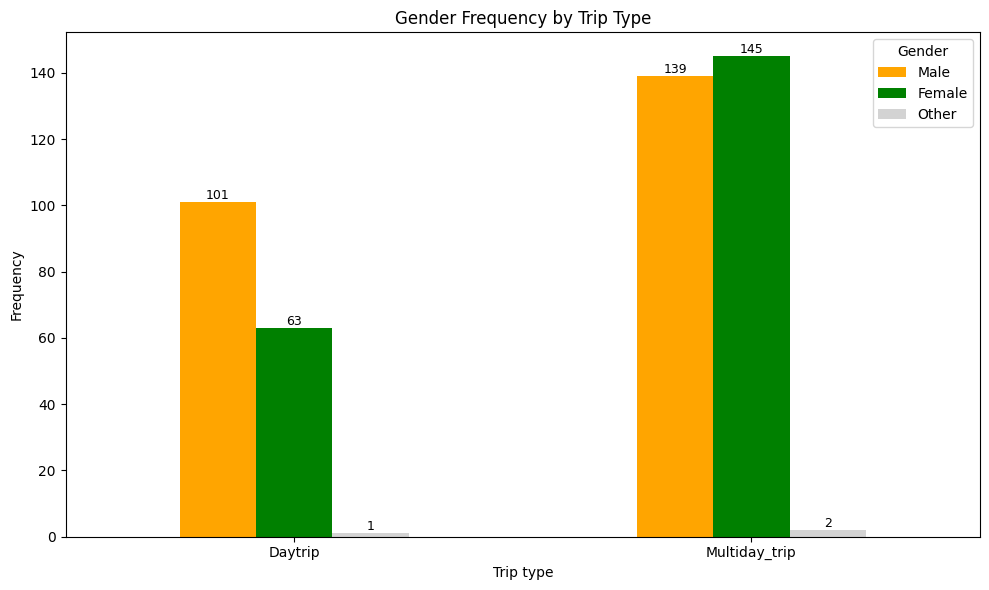

In [78]:
# Transpose so trip type is on x-axis and gender is legend
df_plot = df_gender.T

colors = ['orange', 'green', 'lightgrey']

ax = df_plot.plot(
    kind='bar',
    figsize=(10, 6),
    color=colors
)

ax.set_xlabel('Trip type')
ax.set_ylabel('Frequency')
ax.set_title('Gender Frequency by Trip Type')
ax.legend(title='Gender')

plt.xticks(rotation=0)

# Optional: annotate bar values
for p in ax.patches:
    ax.annotate(
        int(p.get_height()),
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()
plt.show()


## Age group

In [79]:
age_counts_or = df_or['A2_age'].value_counts(dropna=True).sort_index()
age_counts_nbt = df_nbt['A2_age'].value_counts(dropna=True).sort_index()
df_age = pd.DataFrame({'Daytrip': age_counts_or, 'Multiday_trip': age_counts_nbt}).fillna(0).astype(int)
# map numeric index to age names
dict_age = {
    1: '<16',
    2: '16-24',
    3: '25-34',
    4: '35-44',
    5: '45-54',
    6: '55-64',
    7: '65-74',
    8: '>75'}
df_age.index = df_age.index.map(dict_age)
df_age

,Daytrip,Multiday_trip
A2_age,,
<16,1,5
16-24,19,20
25-34,27,63
35-44,31,56
45-54,24,61
55-64,32,43
65-74,25,34
>75,6,4


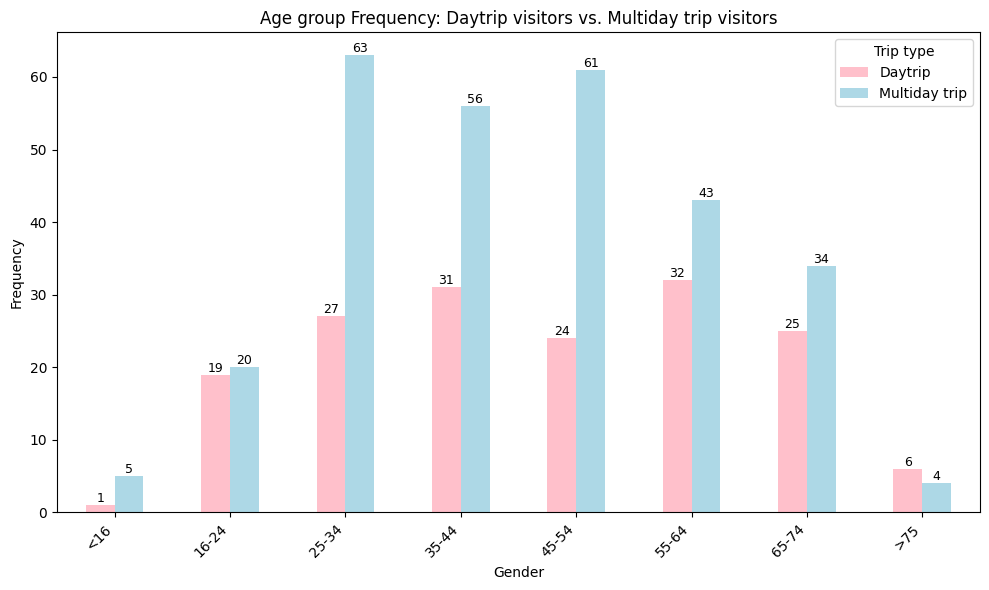

In [83]:
# Plot activity frequencies for daytrips and multiday trips side-by-side
colors = ['pink', 'lightblue']
ax = df_age.plot(kind='bar', figsize=(10,6), color=colors)
ax.set_xlabel('Gender')
ax.set_ylabel('Frequency')
ax.set_title('Age group Frequency: Daytrip visitors vs. Multiday trip visitors')
ax.legend(['Daytrip', 'Multiday trip'], title='Trip type')
plt.xticks(rotation=45, ha='right')

# optional: annotate bar values
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()
# ...existing code...

# Activities

## Activities

In [454]:
# Get the frequency counts for activities
act_counts_or = df_or.activity.value_counts(dropna=True).sort_index()
act_counts_nbt = df_nbt.activity.value_counts(dropna=True).sort_index()

df_act = pd.DataFrame({'Daytrip': act_counts_or, 'Multiday_trip': act_counts_nbt}).fillna(0).astype(int)
df_act = df_act.sort_values(by=['Daytrip', 'Multiday_trip'], ascending=False)
df_act

,Daytrip,Multiday_trip
activity,,
Walking,74,145
Outdoor activities with dogs,17,8
Cycling,14,3
Skiing,10,30
Running,8,4
Hunting,6,6
Fishing,5,18
Nature photography,5,14
Treasure hunting,5,2


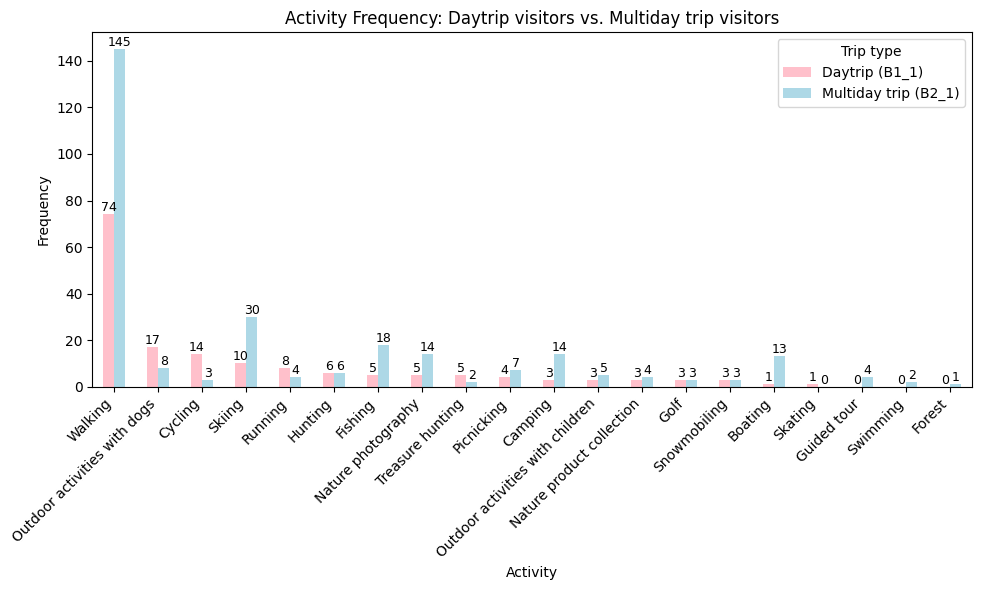

In [455]:
# Plot activity frequencies for daytrips and multiday trips side-by-side
colors = ['pink', 'lightblue']
ax = df_act.plot(kind='bar', figsize=(10,6), color=colors)
ax.set_xlabel('Activity')
ax.set_ylabel('Frequency')
ax.set_title('Activity Frequency: Daytrip visitors vs. Multiday trip visitors')
ax.legend(['Daytrip (B1_1)', 'Multiday trip (B2_1)'], title='Trip type')
plt.xticks(rotation=45, ha='right')

# optional: annotate bar values
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
# Plot accompany type for the full dataset
import matplotlib.pyplot as plt

act_counts = df.activity.value_counts(dropna=True).sort_index()
print(act_counts)

# ax = df['activity'].plot(
#     kind='hist',
#     bins=30,
#     figsize=(10, 6),
#     xlabel='Activity'
# )

# plt.tight_layout()
# plt.show()
act_counts

activity
Boating                              14
Camping                              17
Cycling                              17
Fishing                              23
Forest                                1
Golf                                  6
Guided tour                           4
Hunting                              12
Nature photography                   19
Nature product collection             7
Outdoor activities with children      8
Outdoor activities with dogs         25
Picnicking                           11
Running                              12
Skating                               1
Skiing                               40
Snowmobiling                          6
Swimming                              2
Treasure hunting                      7
Walking                             219
Name: count, dtype: int64


activity
Boating                              14
Camping                              17
Cycling                              17
Fishing                              23
Forest                                1
Golf                                  6
Guided tour                           4
Hunting                              12
Nature photography                   19
Nature product collection             7
Outdoor activities with children      8
Outdoor activities with dogs         25
Picnicking                           11
Running                              12
Skating                               1
Skiing                               40
Snowmobiling                          6
Swimming                              2
Treasure hunting                      7
Walking                             219
Name: count, dtype: int64

## Sub-activities

In [456]:
# Get the frequency counts for sub_activities
sub_act_counts_or = df_or.sub_activity.value_counts(dropna=True).sort_index()
sub_act_counts_nbt = df_nbt.sub_activity.value_counts(dropna=True).sort_index()

df_sub_act = pd.DataFrame({'Daytrip': sub_act_counts_or, 'Multiday_trip': sub_act_counts_nbt}).fillna(0).astype(int)

# map numeric index to activit
df_sub_act = df_sub_act.sort_values(by=['Daytrip', 'Multiday_trip'], ascending=False)
df_sub_act

,Daytrip,Multiday_trip
sub_activity,,
Other walking for exercise,53,50
Hiking at least 10 km,17,58
Dog walking in nature,17,8
Other recreational cycling or leisure biking,13,0
Jogging or running on walking paths and outdoor trails,7,2
Cross-country skiing on prepared runs (less than 20 km),6,16
"Birding, small game hunting or other hunting",5,4
Trolling,4,11
Nordic walking,4,4


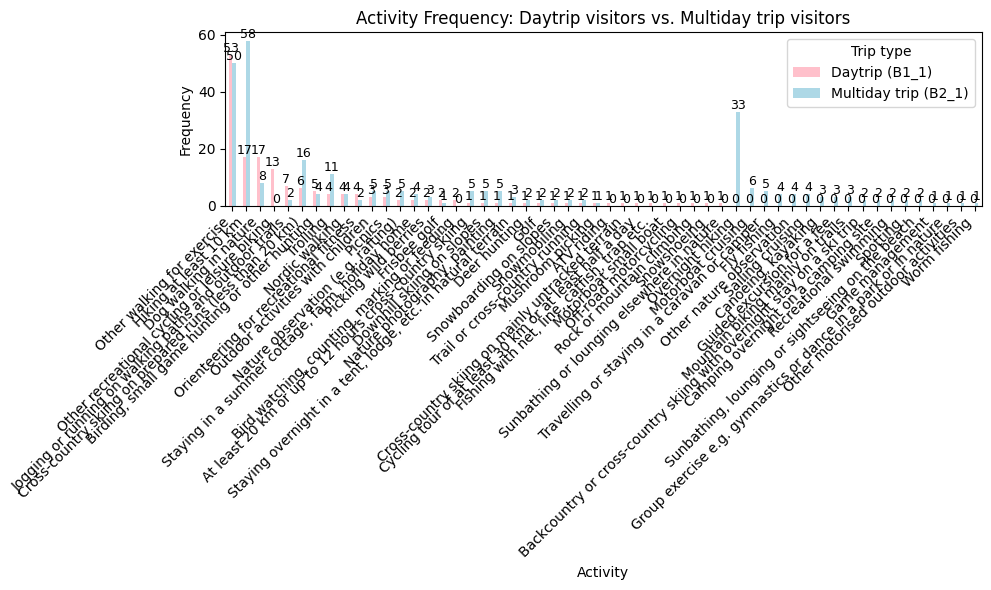

In [457]:
# Plot activity frequencies for daytrips and multiday trips side-by-side
colors = ['pink', 'lightblue']
ax = df_sub_act.plot(kind='bar', figsize=(10,6), color=colors)
ax.set_xlabel('Activity')
ax.set_ylabel('Frequency')
ax.set_title('Activity Frequency: Daytrip visitors vs. Multiday trip visitors')
ax.legend(['Daytrip (B1_1)', 'Multiday trip (B2_1)'], title='Trip type')
plt.xticks(rotation=45, ha='right')

# optional: annotate bar values
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# Hobbies

In [458]:
# Get the frequency counts for hobbies
hobby_counts_or = df_or.hobby.value_counts(dropna=True).sort_index()
hobby_counts_nbt = df_nbt.hobby.value_counts(dropna=True).sort_index()

df_hobby = pd.DataFrame({'Daytrip': hobby_counts_or, 'Multiday_trip': hobby_counts_nbt}).fillna(0).astype(int)

df_or_hobby = df_hobby.sort_values(by=['Daytrip', 'Multiday_trip'], ascending=False)
df_or_hobby

,Daytrip,Multiday_trip
hobby,,
Other activities,56,67
Walking,53,50
Outdoor activities with dogs,17,8
Cycling,14,0
Cross-country skiing,8,23
Running,7,0
Nordic walking,4,0
Outdoor activities with children,3,5
Nature product collection,3,4


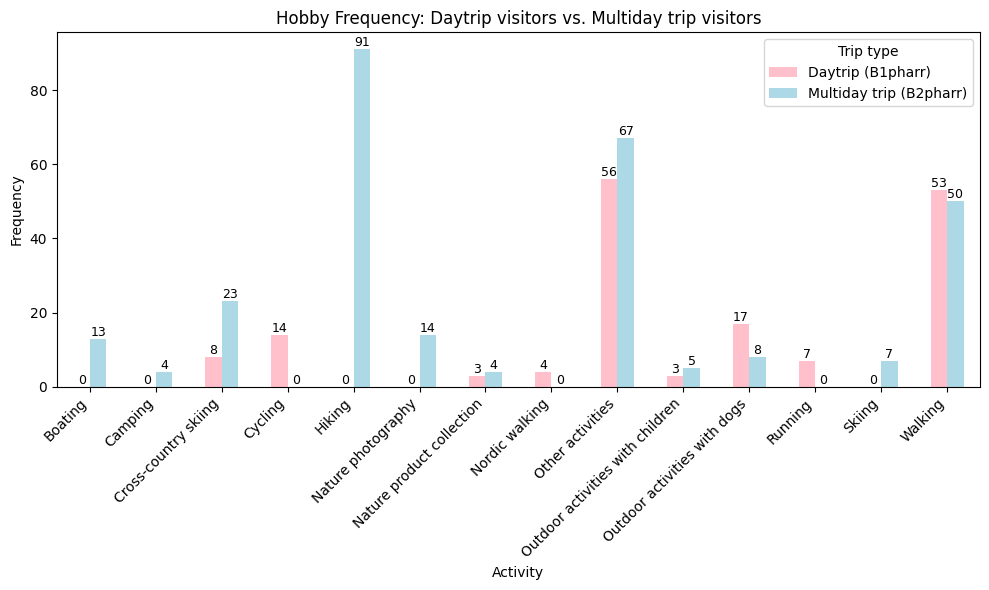

In [459]:
# Plot activity frequencies for daytrips and multiday trips side-by-side
colors = ['pink', 'lightblue']
ax = df_hobby.plot(kind='bar', figsize=(10,6), color=colors)
ax.set_xlabel('Activity')
ax.set_ylabel('Frequency')
ax.set_title('Hobby Frequency: Daytrip visitors vs. Multiday trip visitors')
ax.legend(['Daytrip (B1pharr)', 'Multiday trip (B2pharr)'], title='Trip type')
plt.xticks(rotation=45, ha='right')

# optional: annotate bar values
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# Motivations

## Daytrip visitors

Motivation patterns

In [ ]:
motivation_col = ['motivation_1_peace', 'motivation_2_natural_products', 'motivation_3_landscapes',
                  'motivation_4_experiences', 'motivation_5_fitness', 'motivation_6_recovery',
                  'motivation_7_time', 'motivation_8_social', 'motivation_9_personal_skills',
                  'motivation_10_adventure']

def explore_motivation(df, motivation_col):
    # Rename numeric values for readability
    mapping = {
        1: "Not at all important",
        2: "Somewhat important",
        3: "Fairly important",
        4: "Very important",
        5: "Don't know"
    }

    df_m = df[motivation_col].replace(mapping)

    # Count responses per category
    counts = df_m.apply(lambda x: x.value_counts()).fillna(0)

    # Reorder categories
    order = ["Not at all important", "Somewhat important", "Fairly important", "Very important", "Don't know"]
    counts = counts.reindex(order).fillna(0)

    # Define a color palette
    colors = ["#d73027", "#fc8d59", "#fee08b", "#1a9850", "#bdbdbd"]

    # Plot
    ax = counts.T.plot(kind="barh", stacked=True, figsize=(10, 8), color=colors)

    plt.xlabel("Number of respondents")
    plt.ylabel("Motivation")
    plt.title("Motivation Importance (Stacked Likert Visualization)")

    # Legend outside the plot
    plt.legend(
        title="Response",
        loc="upper center",
        bbox_to_anchor=(0.5, -0.15),
        ncol=3
    )

    plt.tight_layout()
    plt.show()



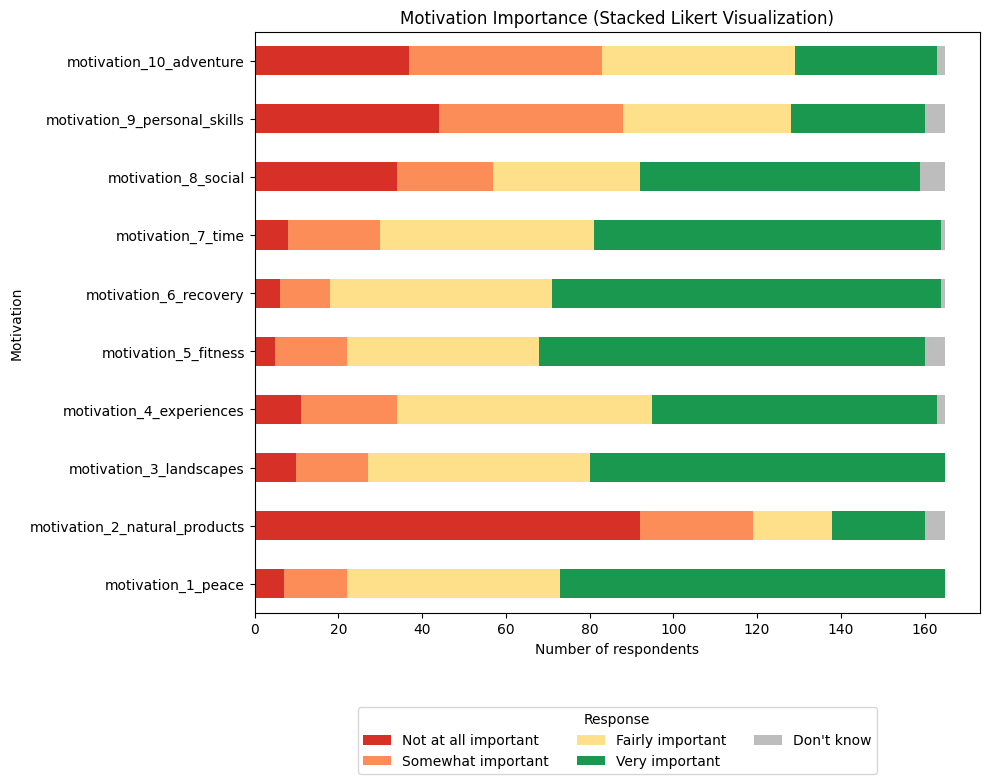

In [113]:
explore_motivation(df_or, motivation_col)

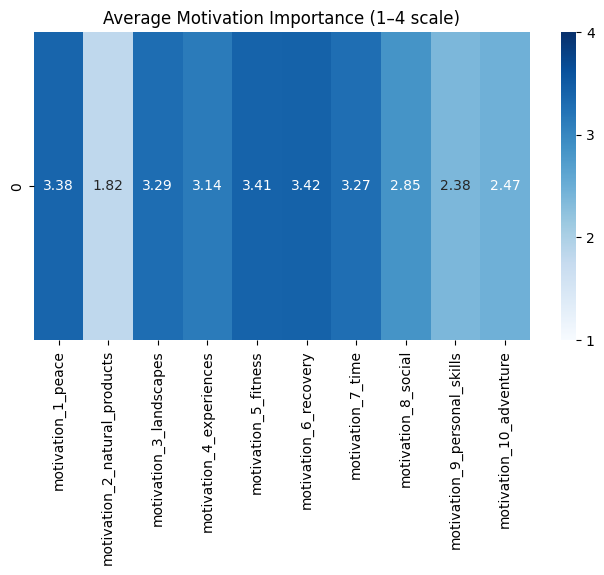

In [476]:
import seaborn as sns
import matplotlib.pyplot as plt

df_clean = df_or[motivation_col].replace(5, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8,4))
ax = sns.heatmap(
    avg.to_frame().T,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=1,
    vmax=4,
    cbar_kws={'ticks': [1, 2, 3, 4]}
)
plt.title("Average Motivation Importance (1–4 scale)")
plt.show()


Visitor clustering based on motivations

In [115]:
# Replace 5 with NaN for motivation columns
df_or_motivation = df_or[motivation_col].replace(5, np.nan)

# Impute with column mean
df_or_motivation = df_or_motivation.fillna(df_or_motivation.mean())

In [116]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_or = scaler.fit_transform(df_or_motivation)


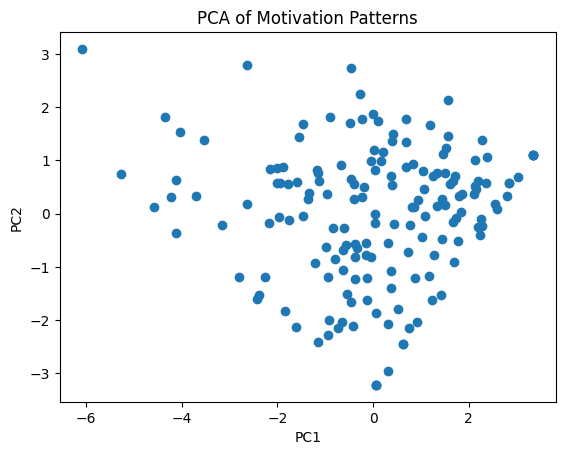

In [117]:
# PCA on motivations
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
coords = pca.fit_transform(X_or)

plt.scatter(coords[:,0], coords[:,1])
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Motivation Patterns")
plt.show()


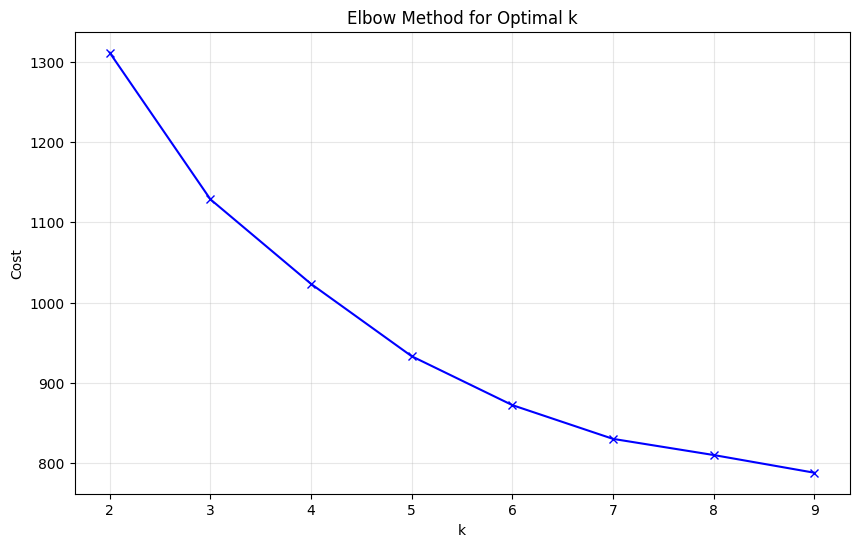

In [118]:
from sklearn.cluster import KMeans
# Find optimal number of clusters using elbow method
cost = []
k_range = range(2, 10)

for k in k_range:
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(X_or)
    cost.append(model.inertia_)

# Plot elbow curve
plt.figure(figsize=(10, 6))
plt.plot(k_range, cost, 'bx-')
plt.xlabel('k')
plt.ylabel('Cost')
plt.title('Elbow Method for Optimal k')
plt.grid(True, alpha=0.3)
plt.show()

In [119]:
# Apply KMeans clustering with chosen k
k = 4
model = KMeans(n_clusters=k, random_state=42)
clusters = model.fit_predict(X_or)

# Add cluster labels to the original dataframe
df_or["motivation_cluster"] = clusters

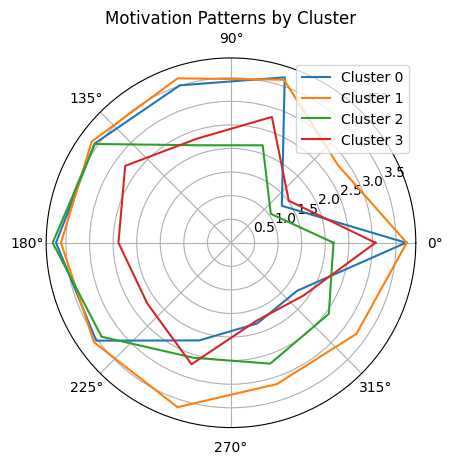

In [120]:
import matplotlib.pyplot as plt
import numpy as np

cluster_means = df_or.groupby("motivation_cluster")[motivation_col].mean()

# Radar plot
labels = motivation_col
angles = np.linspace(0, 2*np.pi, len(labels), endpoint=False)

for cluster in cluster_means.index:
    stats = cluster_means.loc[cluster].tolist()
    stats += stats[:1]  # close loop
    ang = np.concatenate((angles, [angles[0]]))

    plt.polar(ang, stats, label=f"Cluster {cluster}")

plt.legend()
plt.title("Motivation Patterns by Cluster")
plt.show()

## Multiday trip visitors

Motivation patterns

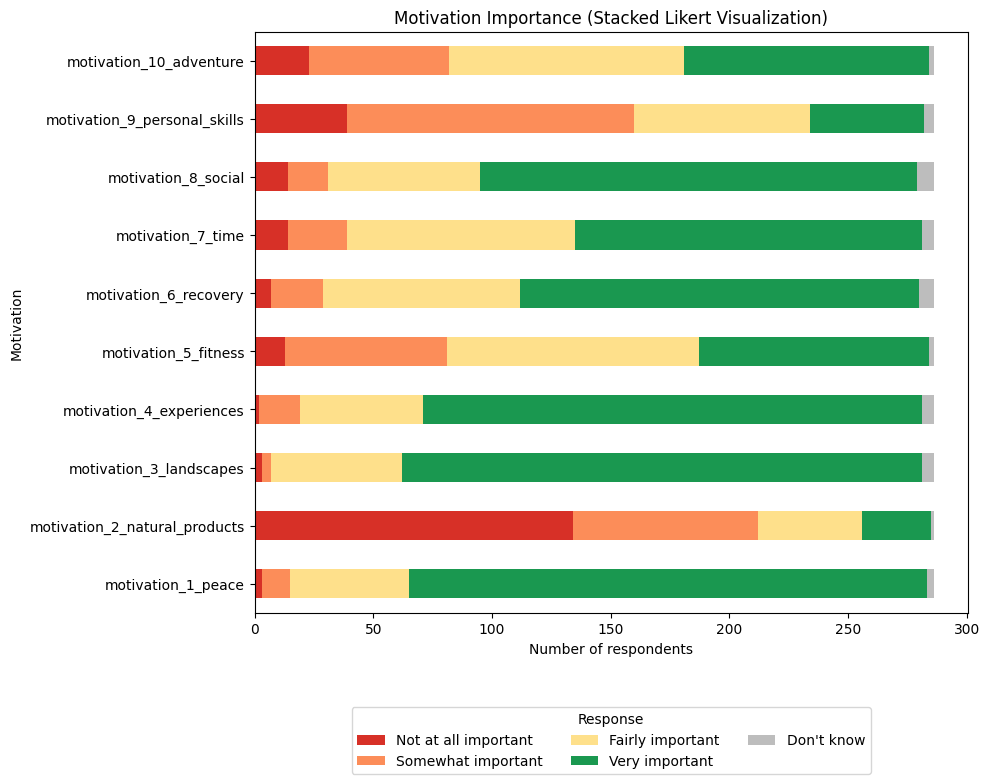

In [121]:
explore_motivation(df_nbt, motivation_col)

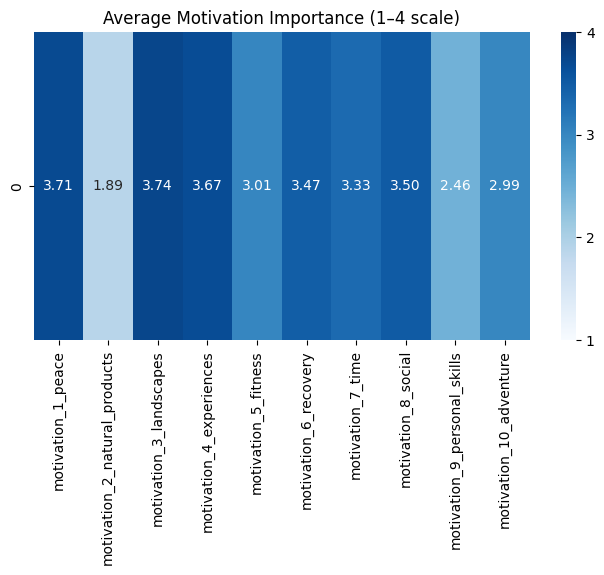

In [475]:
import seaborn as sns
import matplotlib.pyplot as plt

df_clean = df_nbt[motivation_col].replace(5, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8,4))
ax = sns.heatmap(
    avg.to_frame().T,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=1,
    vmax=4,
    cbar_kws={'ticks': [1, 2, 3, 4]}
)
plt.title("Average Motivation Importance (1–4 scale)")
plt.show()


Visitor clustering based on motivations

In [123]:
# Replace 5 with NaN for motivation columns
df_nbt_motivation = df_nbt[motivation_col].replace(5, np.nan)

# Impute with column mean
df_nbt_motivation = df_nbt_motivation.fillna(df_nbt_motivation.mean())

In [124]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_nbt = scaler.fit_transform(df_nbt_motivation)


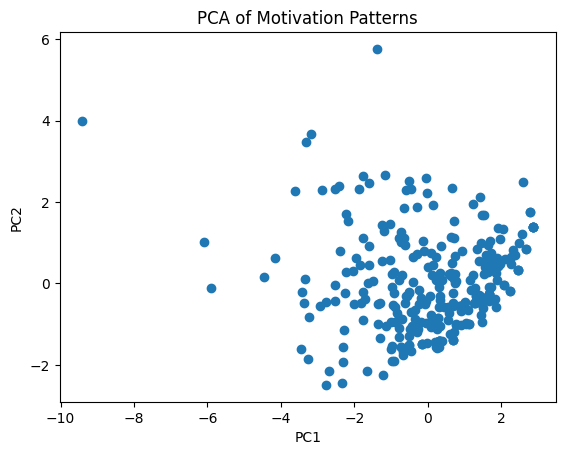

In [125]:
# PCA on motivation data
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
coords = pca.fit_transform(X_nbt)

plt.scatter(coords[:,0], coords[:,1])
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Motivation Patterns")
plt.show()


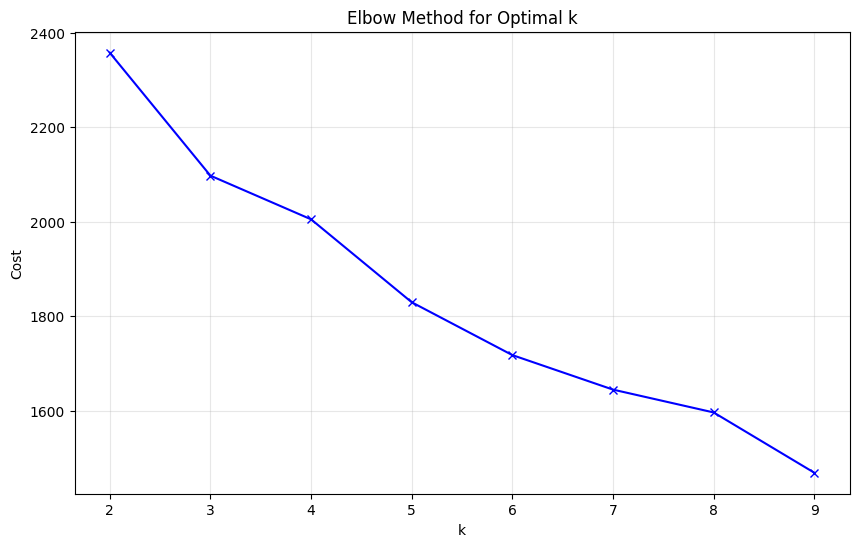

In [126]:
from sklearn.cluster import KMeans
# Find optimal number of clusters using elbow method
cost = []
k_range = range(2, 10)

for k in k_range:
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(X_nbt)
    cost.append(model.inertia_)

# Plot elbow curve
plt.figure(figsize=(10, 6))
plt.plot(k_range, cost, 'bx-')
plt.xlabel('k')
plt.ylabel('Cost')
plt.title('Elbow Method for Optimal k')
plt.grid(True, alpha=0.3)
plt.show()

In [127]:
# Apply KMeans clustering with chosen k
k = 4
model = KMeans(n_clusters=k, random_state=42)
clusters = model.fit_predict(X_nbt)

# Add cluster labels to the original dataframe
df_nbt["motivation_cluster"] = clusters

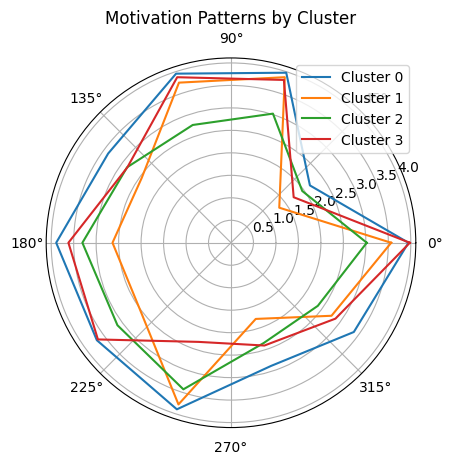

In [128]:
import matplotlib.pyplot as plt
import numpy as np

cluster_means = df_nbt.groupby("motivation_cluster")[motivation_col].mean()

# Radar plot
labels = motivation_col
angles = np.linspace(0, 2*np.pi, len(labels), endpoint=False)

for cluster in cluster_means.index:
    stats = cluster_means.loc[cluster].tolist()
    stats += stats[:1]  # close loop
    ang = np.concatenate((angles, [angles[0]]))

    plt.polar(ang, stats, label=f"Cluster {cluster}")

plt.legend()
plt.title("Motivation Patterns by Cluster")
plt.show()

## All visitors

Motivation patterns

In [131]:
df_motivation = df[motivation_col]
df_motivation

,motivation_1_peace,motivation_2_natural_products,motivation_3_landscapes,motivation_4_experiences,motivation_5_fitness,motivation_6_recovery,motivation_7_time,motivation_8_social,motivation_9_personal_skills,motivation_10_adventure
0,4.0,1.0,4.0,3.0,4.0,4.0,4.0,4.0,4.0,4.0
1,4.0,2.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0
2,2.0,1.0,3.0,3.0,2.0,4.0,4.0,2.0,4.0,4.0
3,3.0,2.0,3.0,2.0,4.0,4.0,3.0,4.0,4.0,3.0
4,3.0,1.0,2.0,1.0,4.0,4.0,4.0,4.0,4.0,4.0
...,...,...,...,...,...,...,...,...,...,...
446,4.0,1.0,4.0,4.0,3.0,4.0,3.0,4.0,2.0,3.0
447,4.0,1.0,4.0,4.0,3.0,3.0,3.0,3.0,2.0,4.0
448,4.0,1.0,4.0,3.0,2.0,4.0,2.0,4.0,3.0,3.0
449,4.0,1.0,4.0,4.0,3.0,4.0,3.0,4.0,2.0,3.0


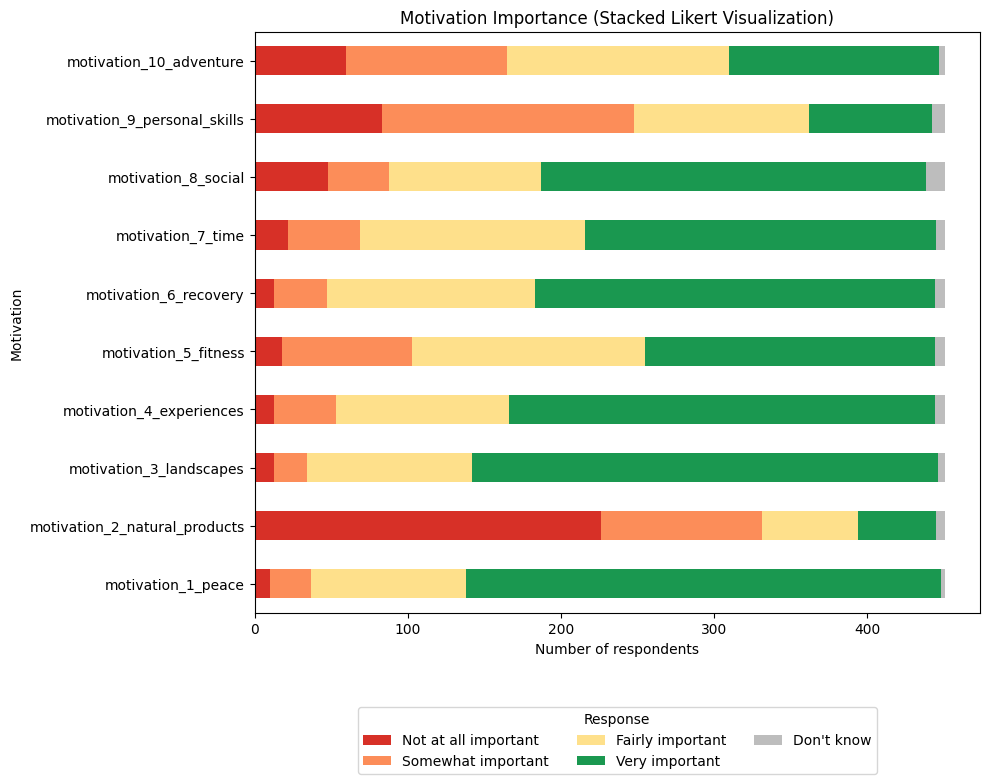

In [132]:
explore_motivation(df_motivation, motivation_col)

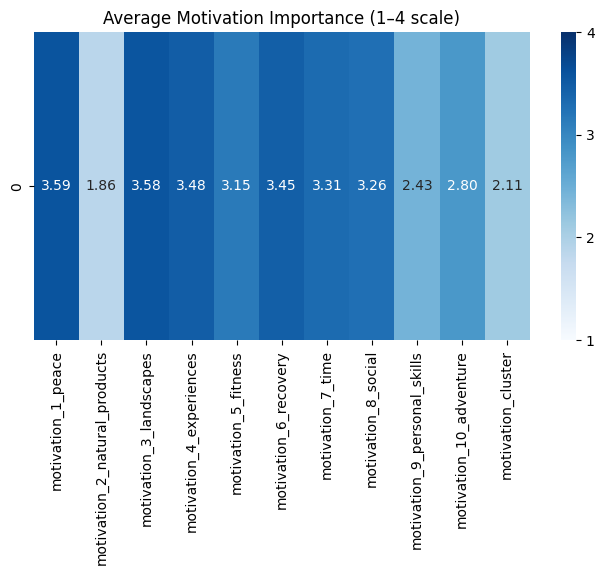

In [477]:
import seaborn as sns
import matplotlib.pyplot as plt

df_clean = df_motivation.replace(5, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8,4))
ax = sns.heatmap(
    avg.to_frame().T,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=1,
    vmax=4,
    cbar_kws={'ticks': [1, 2, 3, 4]}
)
plt.title("Average Motivation Importance (1–4 scale)")
plt.show()


Visitor clustering based on motivations

In [134]:
# Replace 5 with NaN for motivation columns
df_motivation = df_motivation.replace(5, np.nan)

# Impute with column mean
df_motivation = df_motivation.fillna(df_motivation.mean())

In [135]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_nbt = scaler.fit_transform(df_motivation)


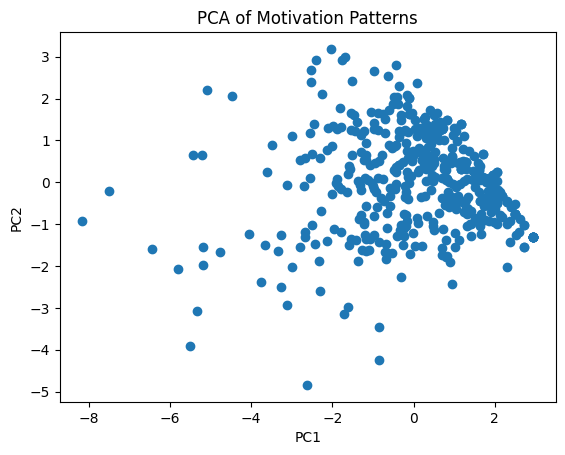

In [136]:
# PCA on motivation data
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
coords = pca.fit_transform(X_nbt)

plt.scatter(coords[:,0], coords[:,1])
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Motivation Patterns")
plt.show()


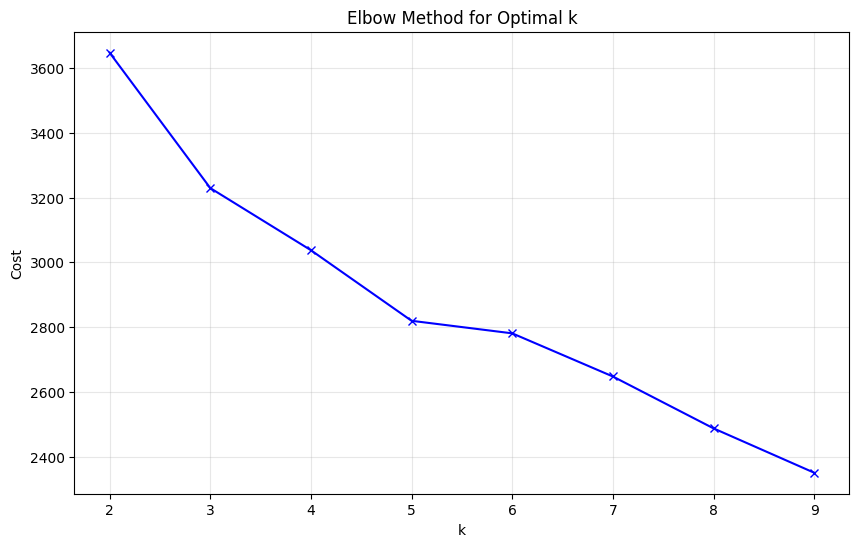

In [137]:
from sklearn.cluster import KMeans
# Find optimal number of clusters using elbow method
cost = []
k_range = range(2, 10)

for k in k_range:
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(X_nbt)
    cost.append(model.inertia_)

# Plot elbow curve
plt.figure(figsize=(10, 6))
plt.plot(k_range, cost, 'bx-')
plt.xlabel('k')
plt.ylabel('Cost')
plt.title('Elbow Method for Optimal k')
plt.grid(True, alpha=0.3)
plt.show()

In [138]:
# Apply KMeans clustering with chosen k
k = 5
model = KMeans(n_clusters=k, random_state=42)
clusters = model.fit_predict(X_nbt)

# Add cluster labels to the original dataframe
df_motivation["motivation_cluster"] = clusters

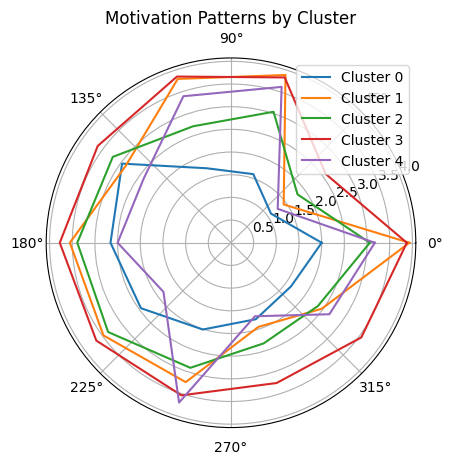

In [139]:
import matplotlib.pyplot as plt
import numpy as np

cluster_means = df_motivation.groupby("motivation_cluster")[motivation_col].mean()

# Radar plot
labels = motivation_col
angles = np.linspace(0, 2*np.pi, len(labels), endpoint=False)

for cluster in cluster_means.index:
    stats = cluster_means.loc[cluster].tolist()
    stats += stats[:1]  # close loop
    ang = np.concatenate((angles, [angles[0]]))

    plt.polar(ang, stats, label=f"Cluster {cluster}")

plt.legend()
plt.title("Motivation Patterns by Cluster")
plt.show()

# Activities across areas

## Daytrip visitors

Activities across areas

In [460]:
# Analyze activities based on area type
df_or_state_recreation = df_or[df_or['destination']==2]
df_or_state_nature_reserve = df_or[df_or['destination']==5]
df_or_wilderness_area = df_or[df_or['destination']==4]
df_or_national_park = df_or[df_or['destination']==3]
df_or_state_forest = df_or[df_or['destination']==11]

print(f'State recreation area count: {df_or_state_recreation.shape[0]}')
print(f'State nature reserve count: {df_or_state_nature_reserve.shape[0]}')
print(f'Wilderness area count: {df_or_wilderness_area.shape[0]}')
print(f'National park count: {df_or_national_park.shape[0]}')
print(f'State forest count: {df_or_state_forest.shape[0]}')


# Get the frequency counts for activities
act_counts_or_state_recreation = df_or_state_recreation['activity'].value_counts(dropna=True).sort_index()
act_counts_or_nature_reserve = df_or_state_nature_reserve['activity'].value_counts(dropna=True).sort_index()
act_counts_or_wilderness_area = df_or_wilderness_area['activity'].value_counts(dropna=True).sort_index()
act_counts_or_national_park = df_or_national_park['activity'].value_counts(dropna=True).sort_index()
act_counts_or_state_forest = df_or_state_forest['activity'].value_counts(dropna=True).sort_index()
df_or_act = pd.DataFrame({'state_recreation': act_counts_or_state_recreation, 'state_nature_reserve': act_counts_or_nature_reserve, 'wilderness_area': act_counts_or_wilderness_area,
                          'national_park': act_counts_or_national_park, 'state_forest': act_counts_or_state_forest}).fillna(0).astype(int)

df_or_act = df_or_act[df_or_act.index.notnull()]
df_or_act

State recreation area count: 18
State nature reserve count: 21
Wilderness area count: 14
National park count: 59
State forest count: 11


,state_recreation,state_nature_reserve,wilderness_area,national_park,state_forest
activity,,,,,
Boating,0,0,0,1,0
Camping,1,0,0,2,0
Cycling,0,1,0,5,2
Fishing,3,0,1,0,1
Golf,1,0,0,0,0
Hunting,0,0,2,0,1
Nature photography,0,2,1,0,2
Nature product collection,0,0,1,1,0
Outdoor activities with children,0,1,0,1,0


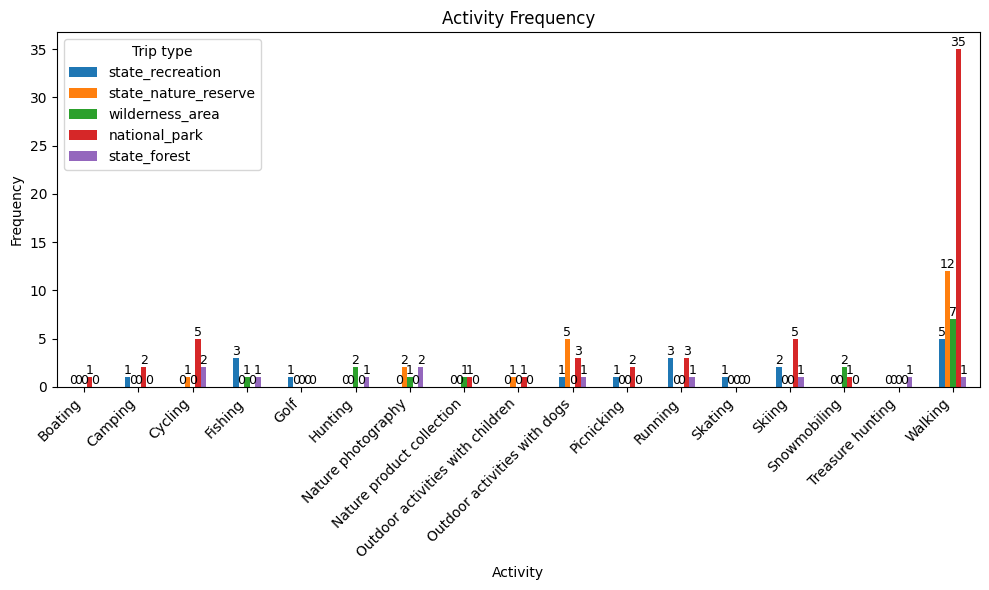

In [461]:
# Plot activity frequencies for daytrips and multiday trips side-by-side
ax = df_or_act.plot(kind='bar', figsize=(10,6))
ax.set_xlabel('Activity')
ax.set_ylabel('Frequency')
ax.set_title('Activity Frequency')
ax.legend(title='Trip type')
plt.xticks(rotation=45, ha='right')

# optional: annotate bar values
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## Multiday trip visitors

Activities across areas

In [462]:
df_nbt.shape

(286, 120)

In [463]:
# Analyze activities based on area type
df_nbt_state_recreation = df_nbt[df_nbt['destination']==2]
df_nbt_state_nature_reserve = df_nbt[df_nbt['destination']==5]
df_nbt_wilderness_area = df_nbt[df_nbt['destination']==4]
df_nbt_national_park = df_nbt[df_nbt['destination']==3]
df_nbt_state_forest = df_nbt[df_nbt['destination']==11]

print(f'State recreation area count: {df_nbt_state_recreation.shape[0]}')
print(f'State nature reserve count: {df_nbt_state_nature_reserve.shape[0]}')
print(f'Wilderness area count: {df_nbt_wilderness_area.shape[0]}')
print(f'National park count: {df_nbt_national_park.shape[0]}')
print(f'State forest count: {df_nbt_state_forest.shape[0]}')

# Get the frequency counts for activities
act_counts_nbt_state_recreation = df_nbt_state_recreation['activity'].value_counts(dropna=True).sort_index()
act_counts_nbt_nature_reserve = df_nbt_state_nature_reserve['activity'].value_counts(dropna=True).sort_index()
act_counts_nbt_wilderness_area = df_nbt_wilderness_area['activity'].value_counts(dropna=True).sort_index()
act_counts_nbt_national_park = df_nbt_national_park['activity'].value_counts(dropna=True).sort_index()
act_counts_nbt_state_forest = df_nbt_state_forest['activity'].value_counts(dropna=True).sort_index()

df_nbt_act = pd.DataFrame({'state_recreation': act_counts_nbt_state_recreation, 'state_nature_reserve': act_counts_nbt_nature_reserve, 'wilderness_area': act_counts_nbt_wilderness_area,
                           'national_park': act_counts_nbt_national_park, 'state_forest': act_counts_nbt_state_forest}).fillna(0).astype(int)

df_nbt_act = df_nbt_act[df_nbt_act.index.notnull()]
df_nbt_act

State recreation area count: 38
State nature reserve count: 8
Wilderness area count: 31
National park count: 171
State forest count: 7


,state_recreation,state_nature_reserve,wilderness_area,national_park,state_forest
activity,,,,,
Boating,4,1,1,5,0
Camping,3,1,1,7,0
Cycling,0,0,0,1,0
Fishing,8,0,6,1,3
Forest,0,0,1,0,0
Golf,0,0,0,1,1
Guided tour,0,0,1,3,0
Hunting,2,0,3,0,1
Nature photography,1,0,2,10,1


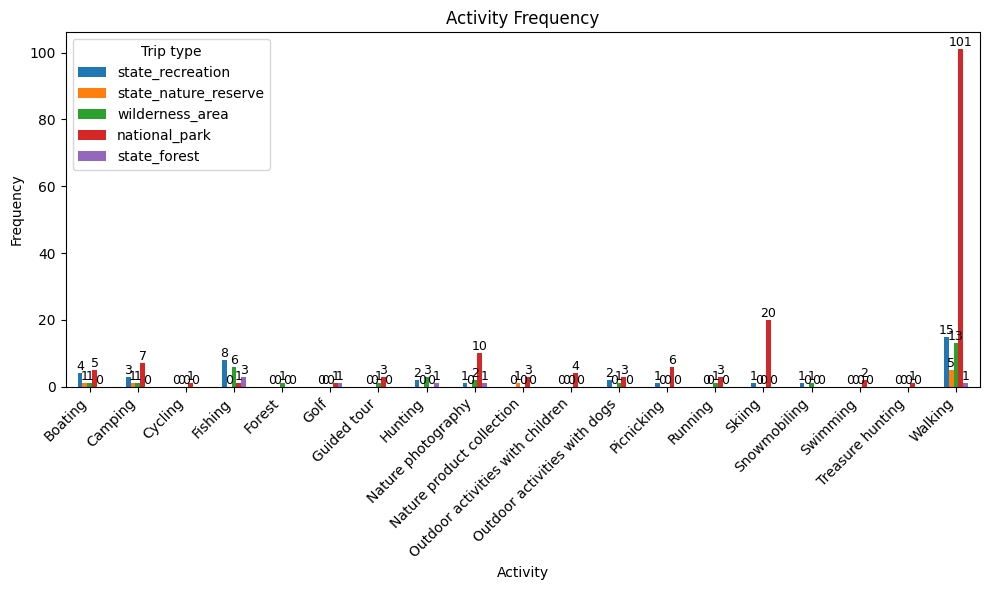

In [464]:
# Plot activity frequencies for daytrips and multiday trips side-by-side
ax = df_nbt_act.plot(kind='bar', figsize=(10,6))
ax.set_xlabel('Activity')
ax.set_ylabel('Frequency')
ax.set_title('Activity Frequency')
ax.legend(title='Trip type')
plt.xticks(rotation=45, ha='right')

# optional: annotate bar values
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## All visitors

In [465]:
df_state_recreation = df[df['destination']==2]
df_state_nature_reserve = df[df['destination']==5]
df_wilderness_area = df[df['destination']==4]
df_national_park = df[df['destination']==3]
df_state_forest = df[df['destination']==11]

print(f'State recreation area count: {df_state_recreation.shape[0]}')
print(f'State nature reserve count: {df_state_nature_reserve.shape[0]}')
print(f'Wilderness area count: {df_wilderness_area.shape[0]}')
print(f'National park count: {df_national_park.shape[0]}')
print(f'State forest count: {df_state_forest.shape[0]}')

# Get the frequency counts for activities
act_counts_state_recreation = df_state_recreation['activity'].value_counts(dropna=True).sort_index()
act_counts_state_nature_reserve = df_state_nature_reserve['activity'].value_counts(dropna=True).sort_index()
act_counts_wilderness_area = df_wilderness_area['activity'].value_counts(dropna=True).sort_index()
act_counts_national_park = df_national_park['activity'].value_counts(dropna=True).sort_index()
act_counts_state_forest = df_state_forest['activity'].value_counts(dropna=True).sort_index()
df_act = pd.DataFrame({'state_recreation': act_counts_state_recreation, 'state_nature_reserve': act_counts_state_nature_reserve, 'wilderness_area': act_counts_wilderness_area,
                          'national_park': act_counts_national_park, 'state_forest': act_counts_state_forest}).fillna(0).astype(int)

df_act = df_act[df_act.index.notnull()]
df_act

State recreation area count: 56
State nature reserve count: 29
Wilderness area count: 45
National park count: 230
State forest count: 18


,state_recreation,state_nature_reserve,wilderness_area,national_park,state_forest
activity,,,,,
Boating,4,1,1,6,0
Camping,4,1,1,9,0
Cycling,0,1,0,6,2
Fishing,11,0,7,1,4
Forest,0,0,1,0,0
Golf,1,0,0,1,1
Guided tour,0,0,1,3,0
Hunting,2,0,5,0,2
Nature photography,1,2,3,10,3


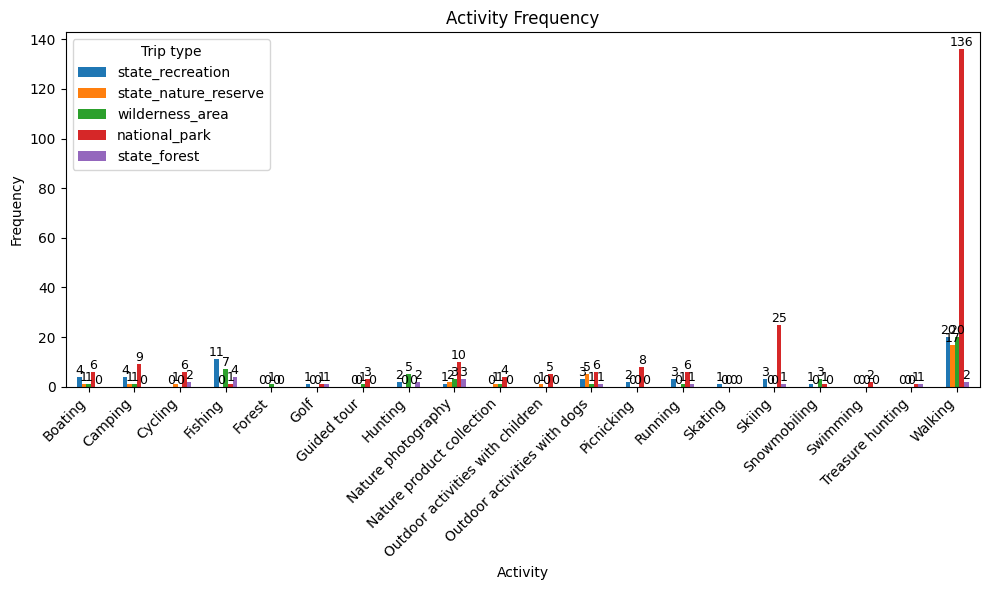

In [466]:
# Plot activity frequencies for daytrips and multiday trips side-by-side
ax = df_act.plot(kind='bar', figsize=(10,6))
ax.set_xlabel('Activity')
ax.set_ylabel('Frequency')
ax.set_title('Activity Frequency')
ax.legend(title='Trip type')
plt.xticks(rotation=45, ha='right')

# optional: annotate bar values
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# Motivations across areas

## Daytrip visitors

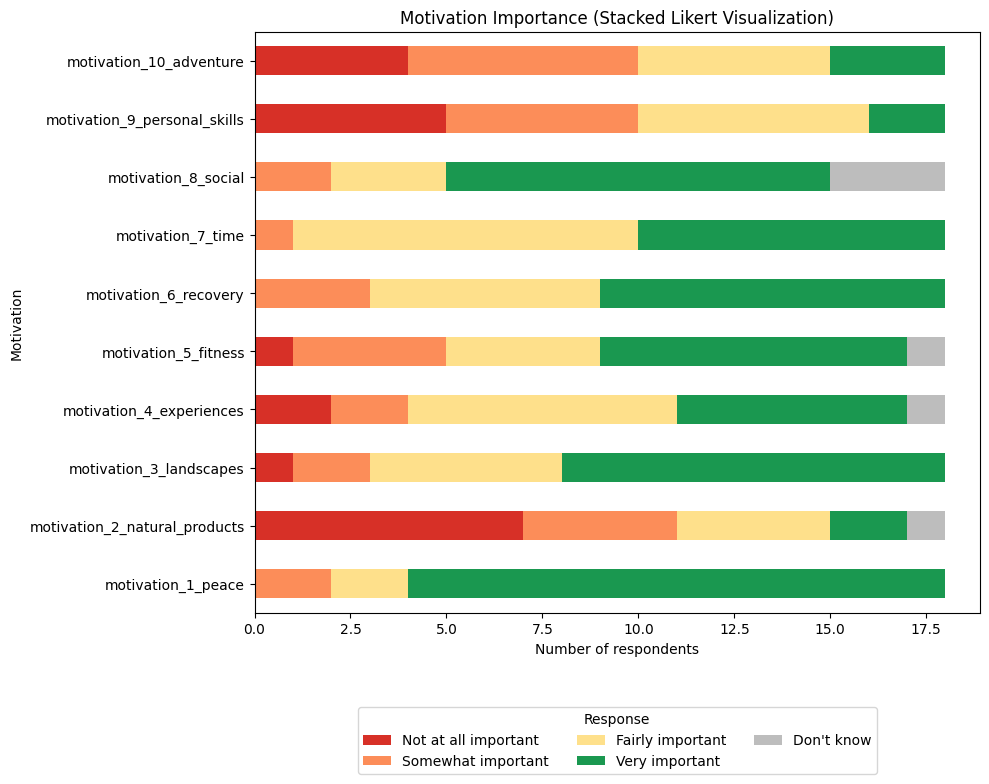

In [237]:
explore_motivation(df_or_state_recreation, motivation_col)

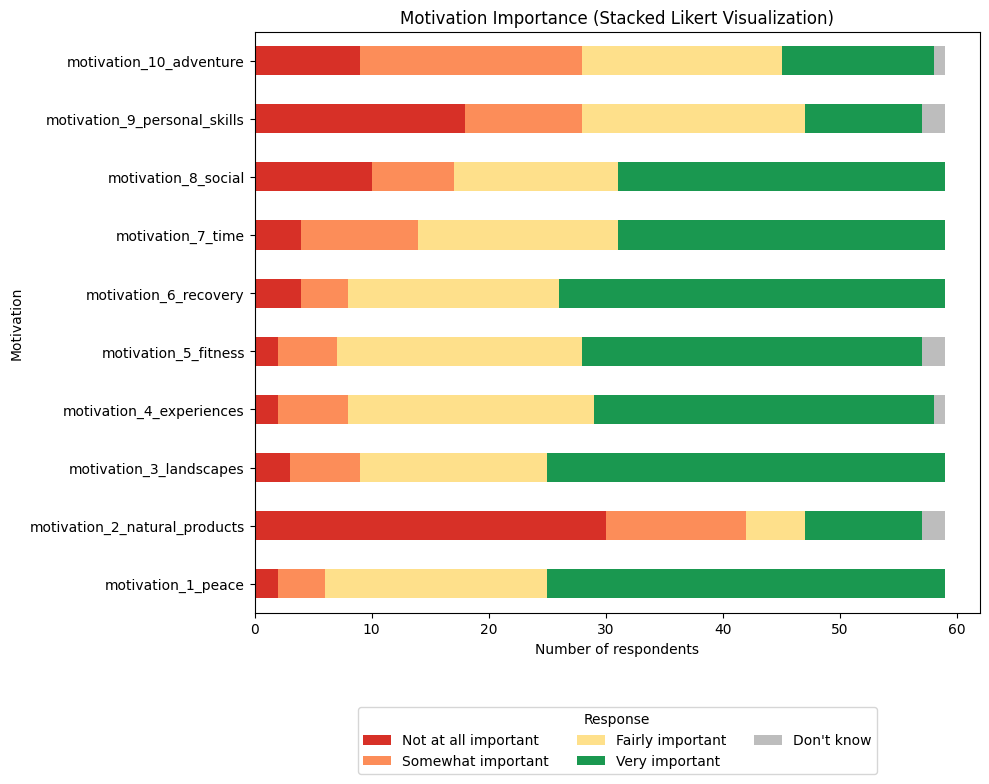

In [238]:
explore_motivation(df_or_national_park, motivation_col)

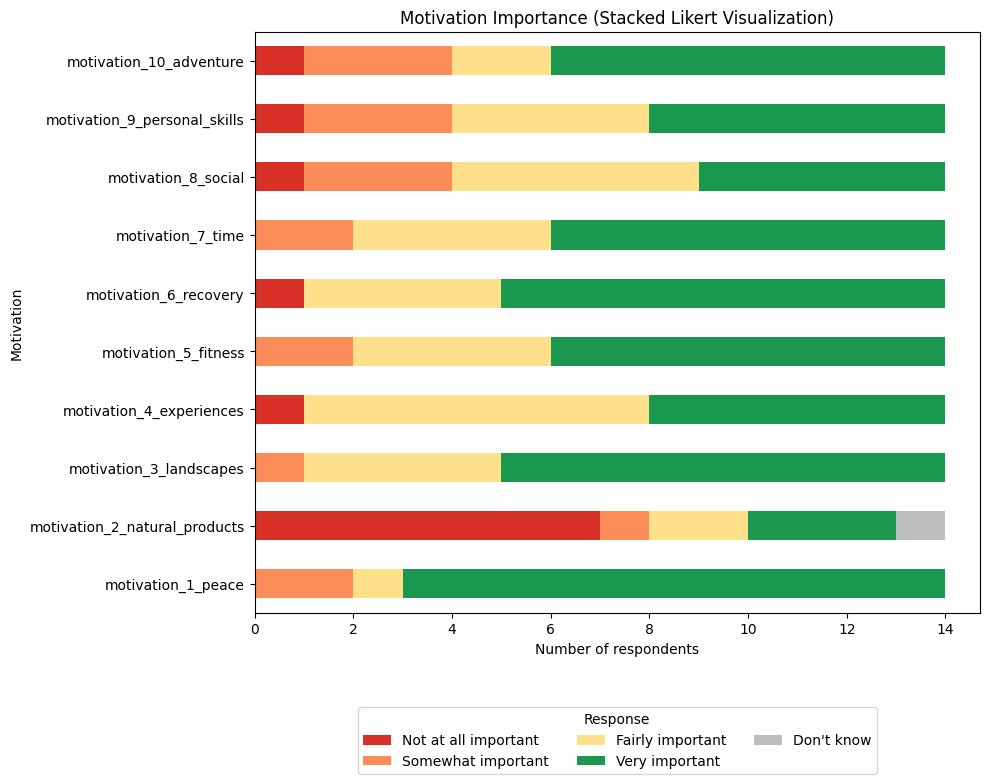

In [239]:
explore_motivation(df_or_wilderness_area, motivation_col)

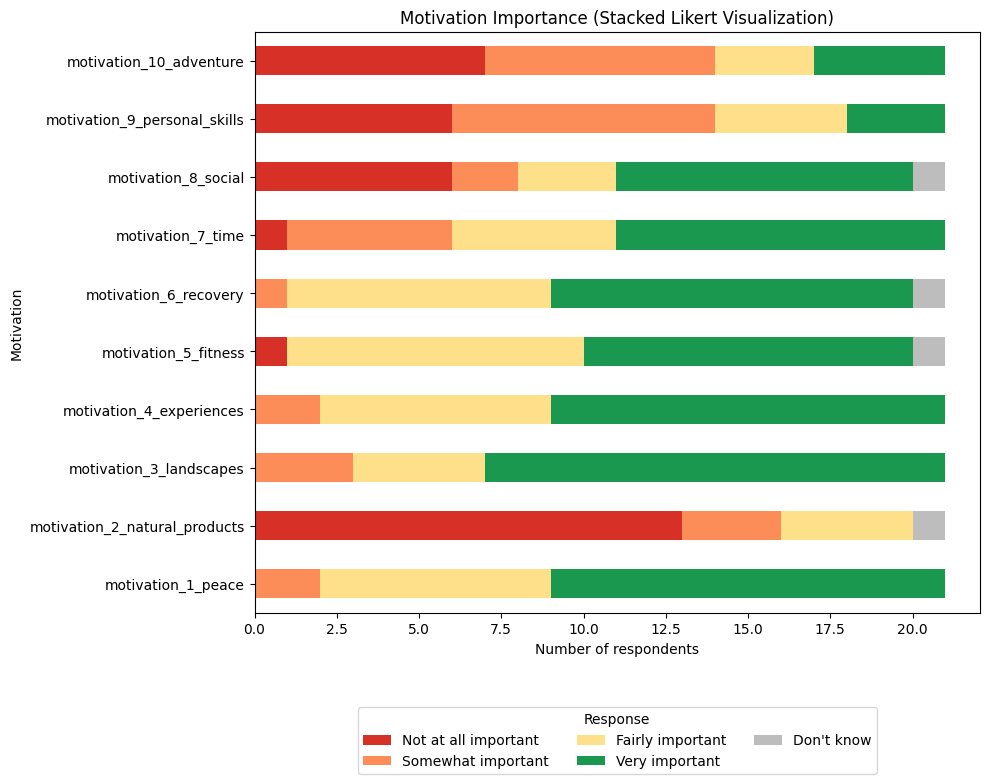

In [241]:
explore_motivation(df_or_state_nature_reserve, motivation_col)

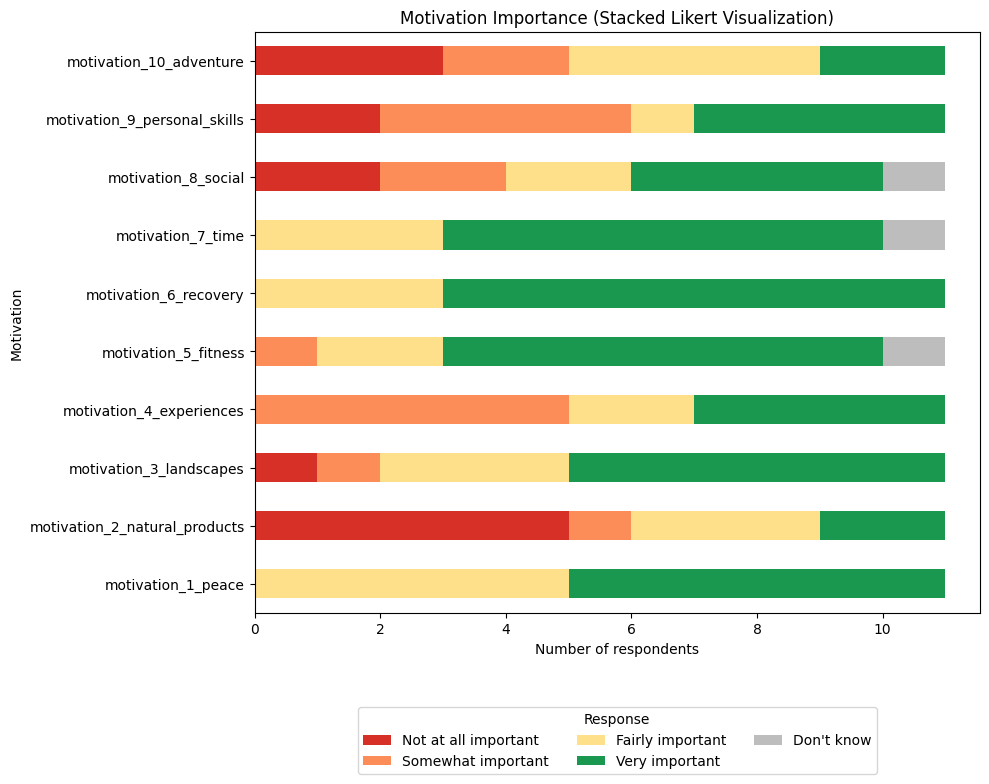

In [242]:
explore_motivation(df_or_state_forest, motivation_col)

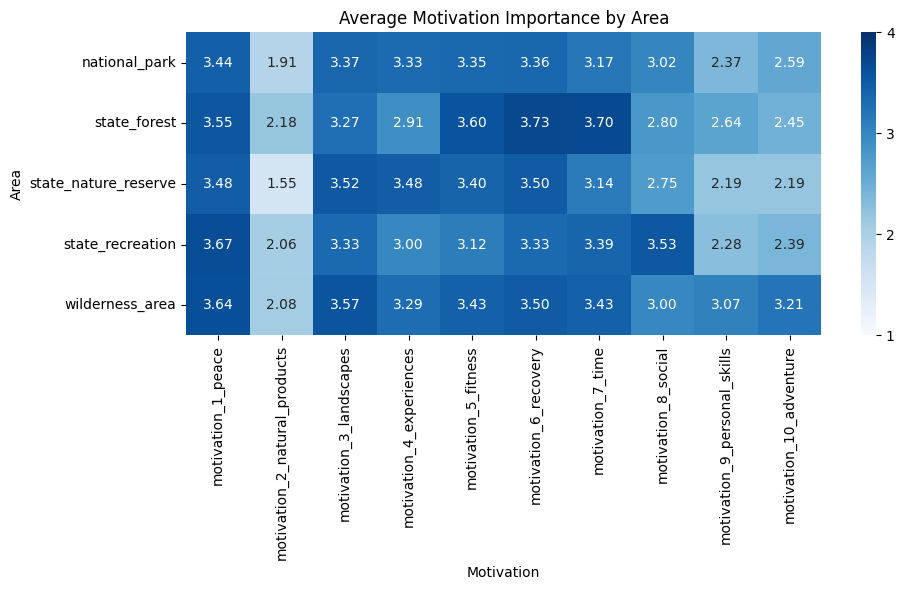

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

df_or_area_motivation = pd.concat([
    df_or_state_recreation[motivation_col].assign(area='state_recreation'),
    df_or_state_nature_reserve[motivation_col].assign(area='state_nature_reserve'),
    df_or_wilderness_area[motivation_col].assign(area='wilderness_area'),
    df_or_national_park[motivation_col].assign(area='national_park'),
    df_or_state_forest[motivation_col].assign(area='state_forest'),
], ignore_index=True)

# Clean motivation values
df_clean = df_or_area_motivation.copy()
df_clean[motivation_col] = (
    df_clean[motivation_col]
    .replace(5, np.nan)
    .apply(pd.to_numeric, errors='coerce')
)

# Average motivation by area (already a DataFrame)
avg_by_area = df_clean.groupby('area')[motivation_col].mean()

# Plot heatmap
plt.figure(figsize=(10, 6))

ax = sns.heatmap(
    avg_by_area,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=1,
    vmax=4,
    cbar_kws={'ticks': [1, 2, 3, 4]}
)

plt.title("Average Motivation Importance by Area")
plt.xlabel("Motivation")
plt.ylabel("Area")
plt.tight_layout()
plt.show()

## Multiday trip visitors

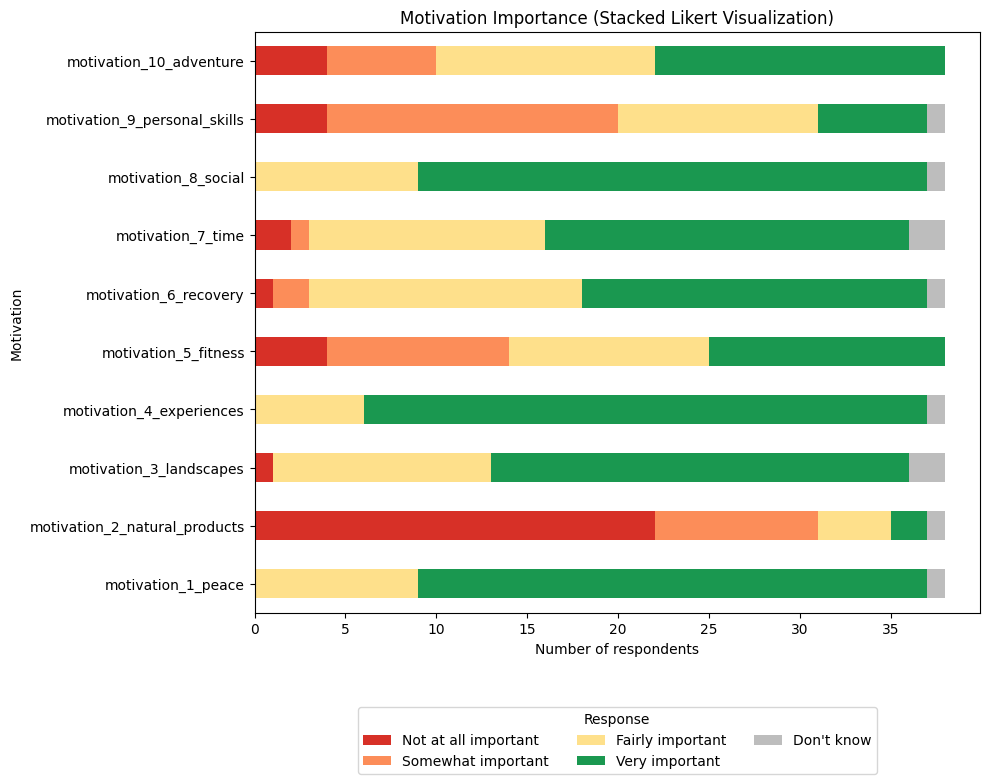

In [255]:
explore_motivation(df_nbt_state_recreation, motivation_col)

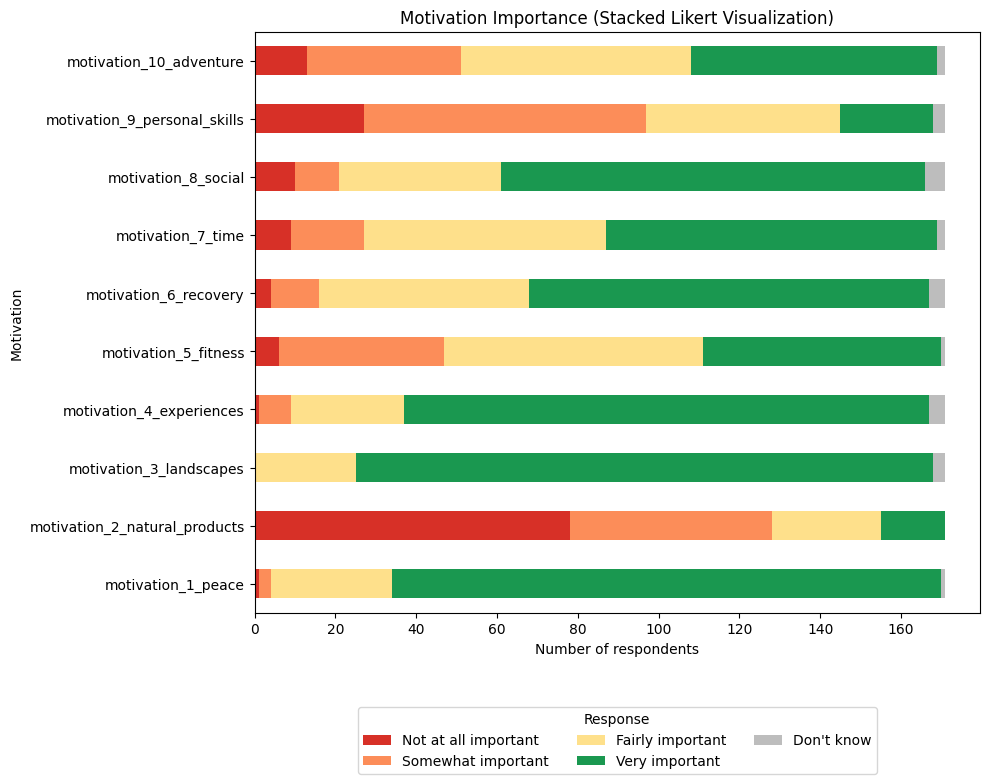

In [256]:
explore_motivation(df_nbt_national_park, motivation_col)

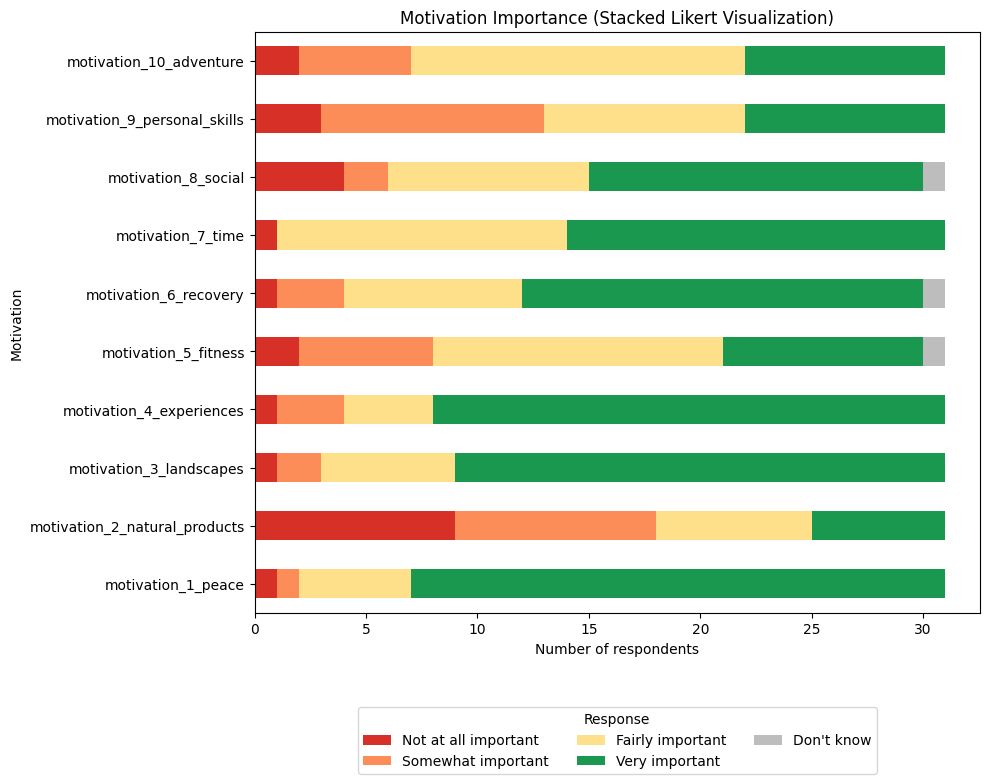

In [257]:
explore_motivation(df_nbt_wilderness_area, motivation_col)

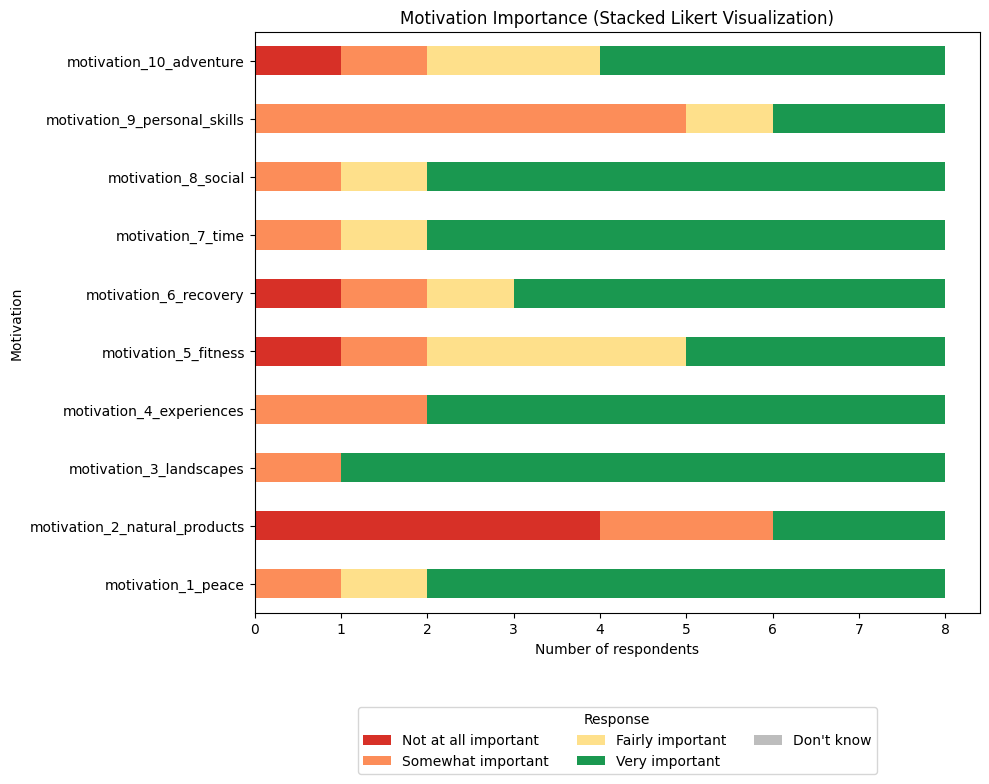

In [258]:
explore_motivation(df_nbt_state_nature_reserve, motivation_col)

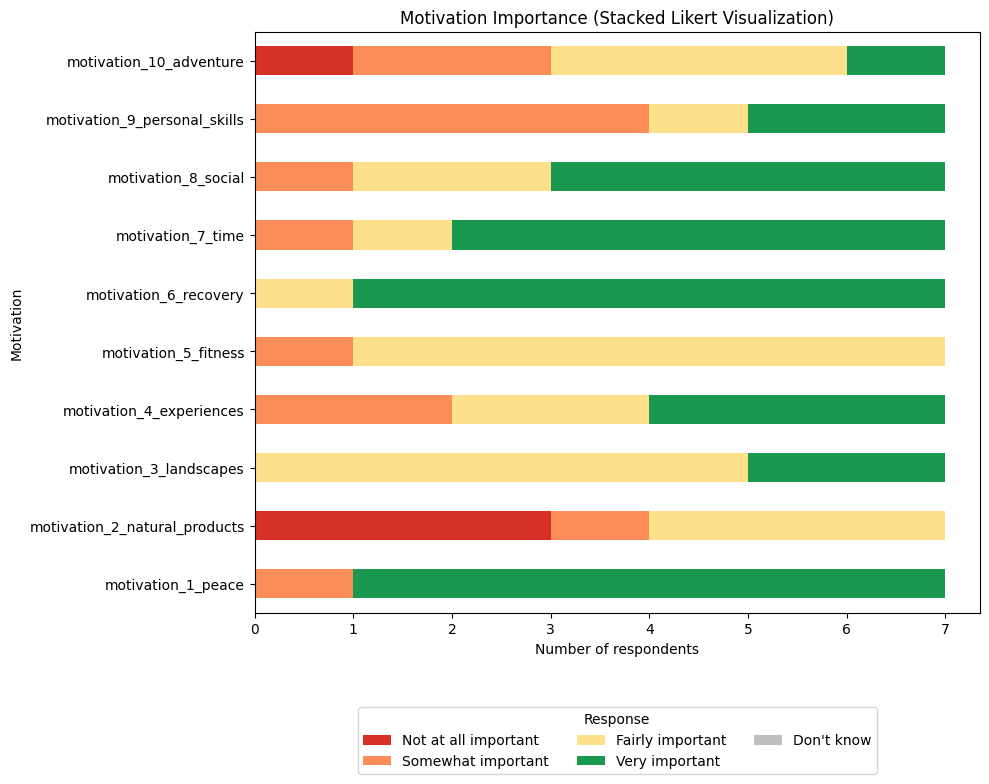

In [259]:
explore_motivation(df_nbt_state_forest, motivation_col)

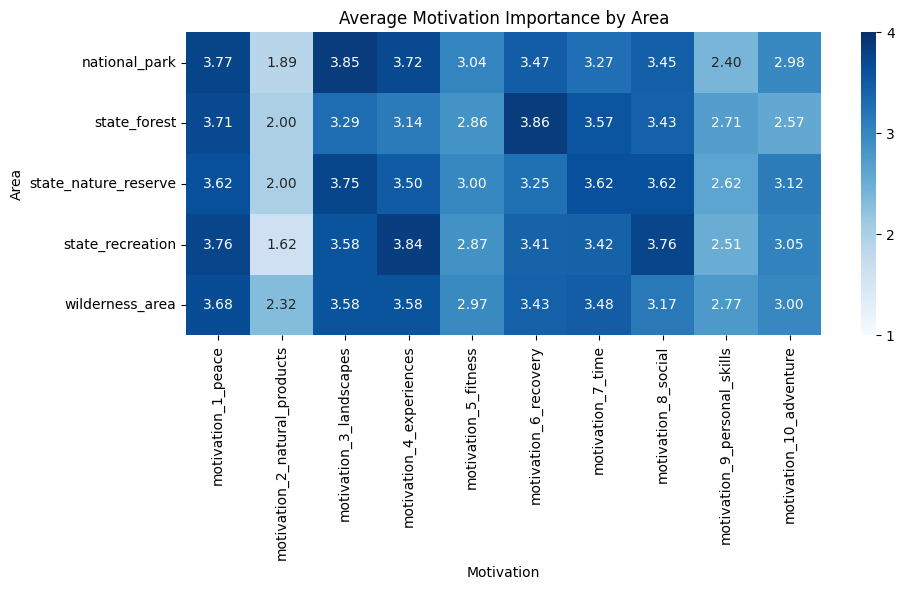

In [479]:
import seaborn as sns
import matplotlib.pyplot as plt

df_nbt_area_motivation = pd.concat([
    df_nbt_state_recreation[motivation_col].assign(area='state_recreation'),
    df_nbt_state_nature_reserve[motivation_col].assign(area='state_nature_reserve'),
    df_nbt_wilderness_area[motivation_col].assign(area='wilderness_area'),
    df_nbt_national_park[motivation_col].assign(area='national_park'),
    df_nbt_state_forest[motivation_col].assign(area='state_forest'),
], ignore_index=True)

# Clean motivation values
df_clean = df_nbt_area_motivation.copy()
df_clean[motivation_col] = (
    df_clean[motivation_col]
    .replace(5, np.nan)
    .apply(pd.to_numeric, errors='coerce')
)

# Average motivation by area (already a DataFrame)
avg_by_area = df_clean.groupby('area')[motivation_col].mean()

# Plot heatmap
plt.figure(figsize=(10, 6))

ax = sns.heatmap(
    avg_by_area,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=1,
    vmax=4,
    cbar_kws={'ticks': [1, 2, 3, 4]}
)

plt.title("Average Motivation Importance by Area")
plt.xlabel("Motivation")
plt.ylabel("Area")
plt.tight_layout()
plt.show()

## All visitors

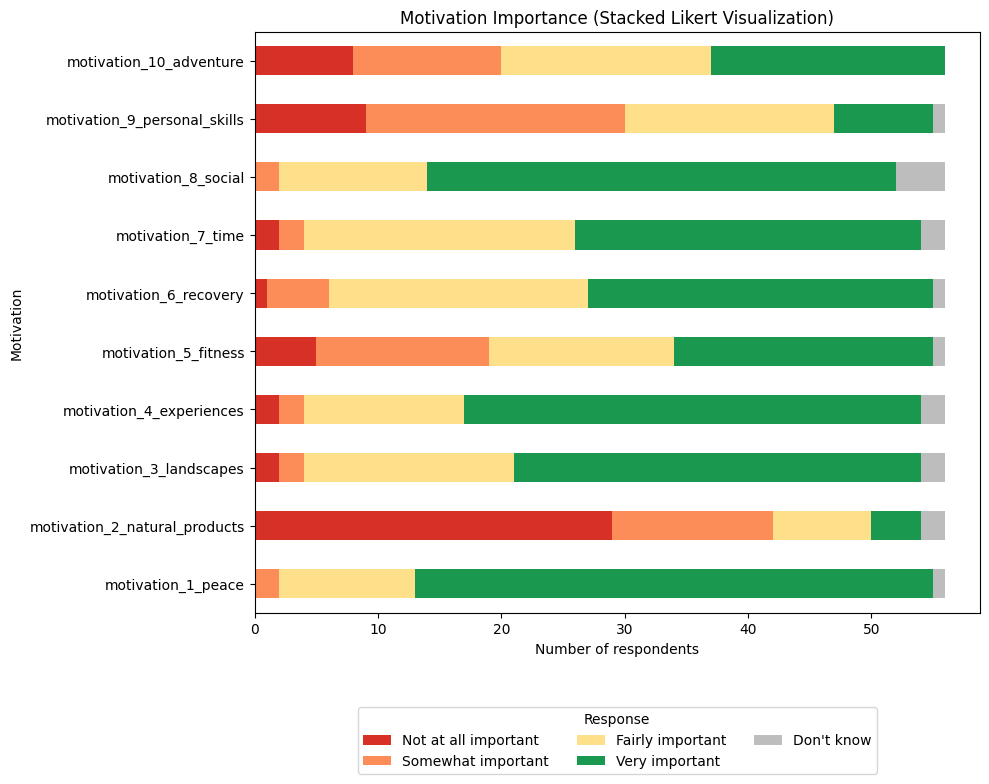

In [267]:
explore_motivation(df_state_recreation, motivation_col)

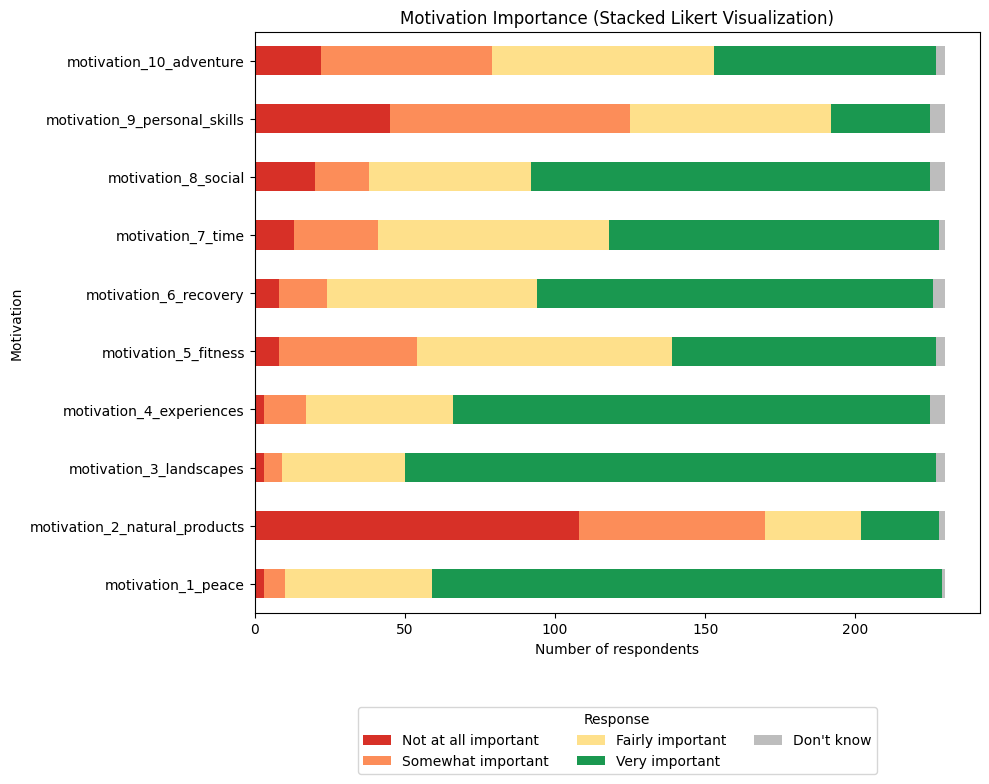

In [268]:
explore_motivation(df_national_park, motivation_col)

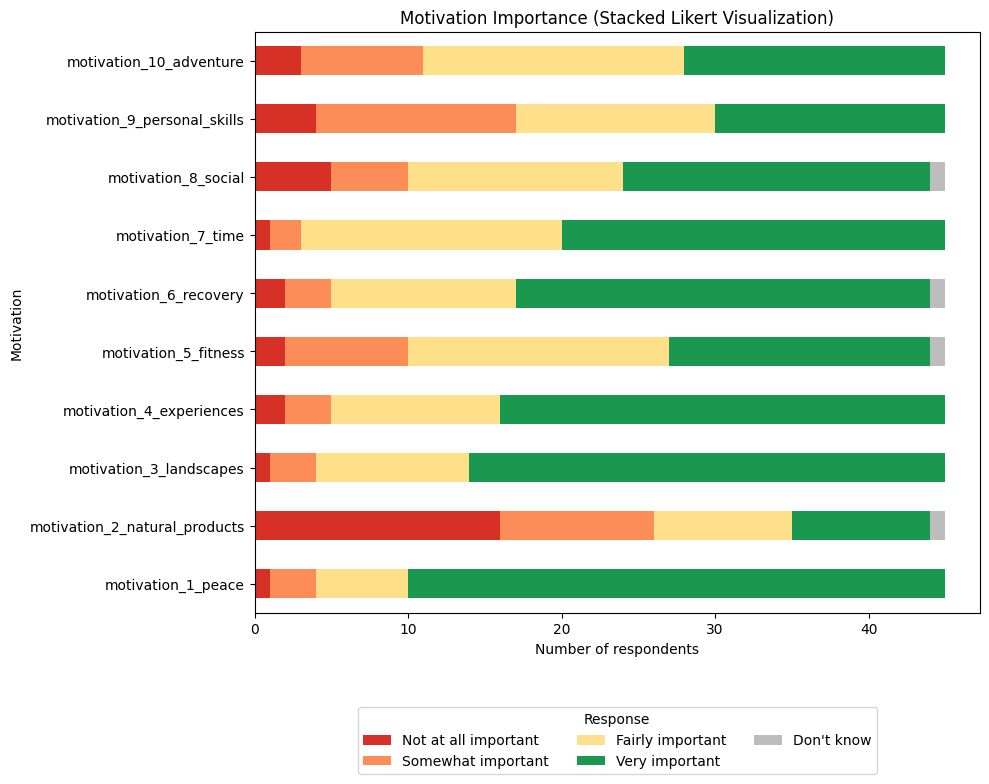

In [269]:
explore_motivation(df_wilderness_area, motivation_col)

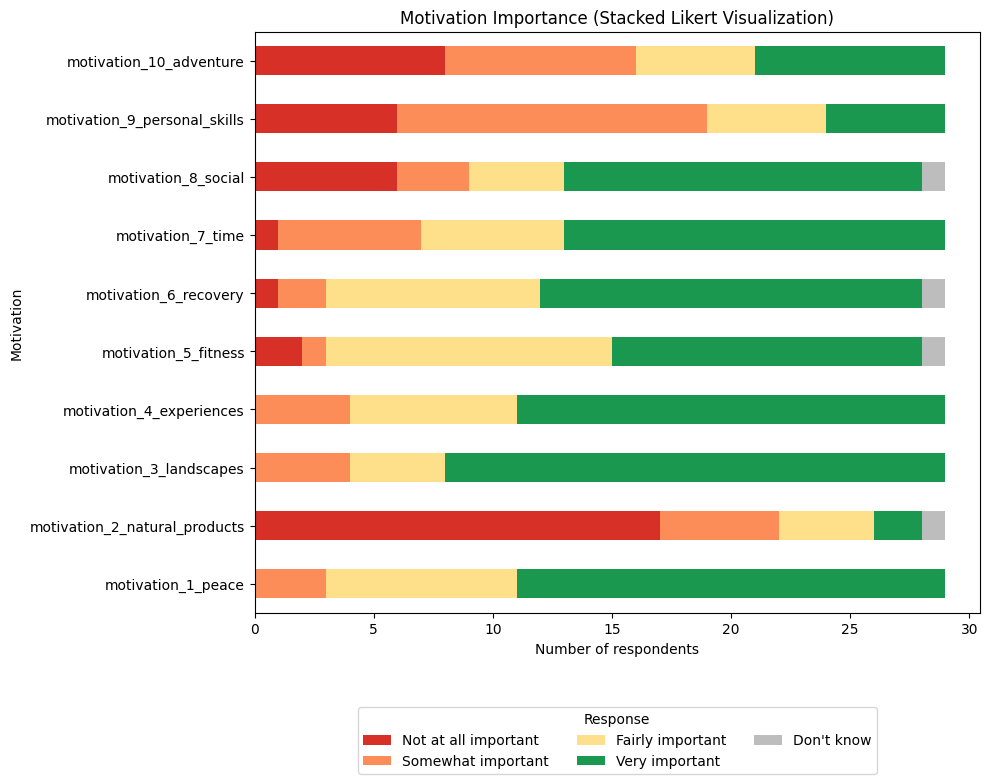

In [270]:
explore_motivation(df_state_nature_reserve, motivation_col)

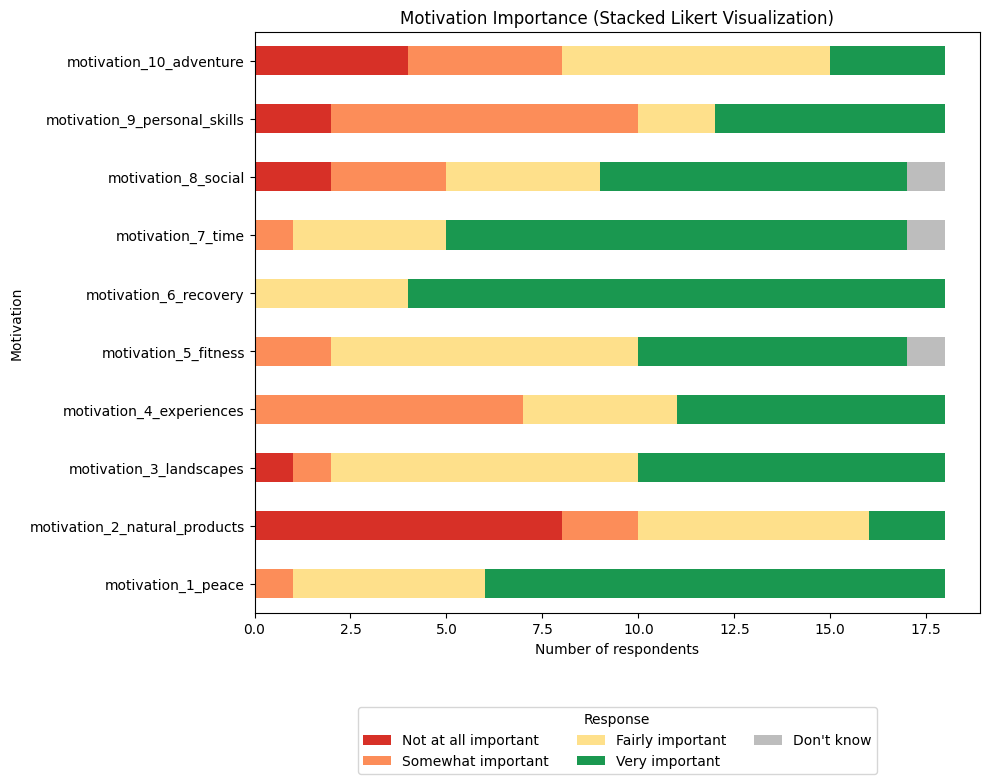

In [271]:
explore_motivation(df_state_forest, motivation_col)

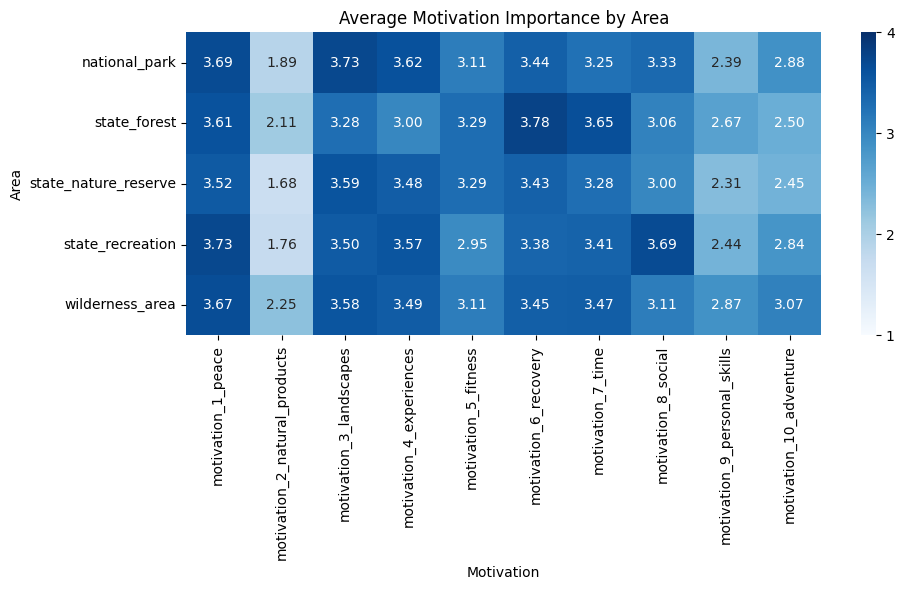

In [480]:
import seaborn as sns
import matplotlib.pyplot as plt

df_area_motivation = pd.concat([
    df_state_recreation[motivation_col].assign(area='state_recreation'),
    df_state_nature_reserve[motivation_col].assign(area='state_nature_reserve'),
    df_wilderness_area[motivation_col].assign(area='wilderness_area'),
    df_national_park[motivation_col].assign(area='national_park'),
    df_state_forest[motivation_col].assign(area='state_forest'),
], ignore_index=True)

# Clean motivation values
df_clean = df_area_motivation.copy()
df_clean[motivation_col] = (
    df_clean[motivation_col]
    .replace(5, np.nan)
    .apply(pd.to_numeric, errors='coerce')
)

# Average motivation by area (already a DataFrame)
avg_by_area = df_clean.groupby('area')[motivation_col].mean()

# Plot heatmap
plt.figure(figsize=(10, 6))

ax = sns.heatmap(
    avg_by_area,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=1,
    vmax=4,
    cbar_kws={'ticks': [1, 2, 3, 4]}
)

plt.title("Average Motivation Importance by Area")
plt.xlabel("Motivation")
plt.ylabel("Area")
plt.tight_layout()
plt.show()

# Travel time & distance
- A50. How much time did you spend travelling to an outdoor area or nature site?
- A51_km. How far was the distance from the starting point to the outdoor area or nature reserve: km

## Daytrip visitors

In [484]:
df_or[['A50_travel_time', 'A51_km_travel_distance']].describe()

,A50_travel_time,A51_km_travel_distance
count,165.000000,165.000000
mean,2.830303,26.332430
std,1.568066,67.710691
min,1.000000,0.000000
25%,2.000000,0.500000
50%,2.000000,4.000000
75%,4.000000,22.000000
max,6.000000,500.000000


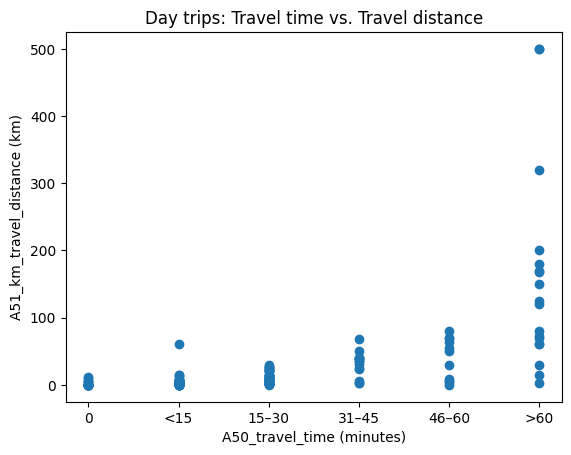

In [19]:
plt.scatter(df_or['A50_travel_time'], df_or['A51_km_travel_distance'])
plt.xlabel('A50_travel_time (minutes)')
plt.ylabel('A51_km_travel_distance (km)')

labels = {
    1: '0',
    2: '<15',
    3: '15–30',
    4: '31–45',
    5: '46–60',
    6: '>60',
}

ax = plt.gca()
ax.set_xticks(list(labels.keys()))
ax.set_xticklabels(list(labels.values()))

plt.title('Day trips: Travel time vs. Travel distance')
plt.show()

## Multiday trip visitors

In [ ]:
df_nbt[['A50_travel_time', 'A51_km_travel_distance']].describe()

,A50_travel_time,A51_km_travel_distance
count,286.000000,286.000000
mean,2.286713,15.022836
std,1.404866,73.462492
min,1.000000,0.000000
25%,1.000000,0.100000
50%,2.000000,2.000000
75%,3.000000,7.000000
max,6.000000,900.000000


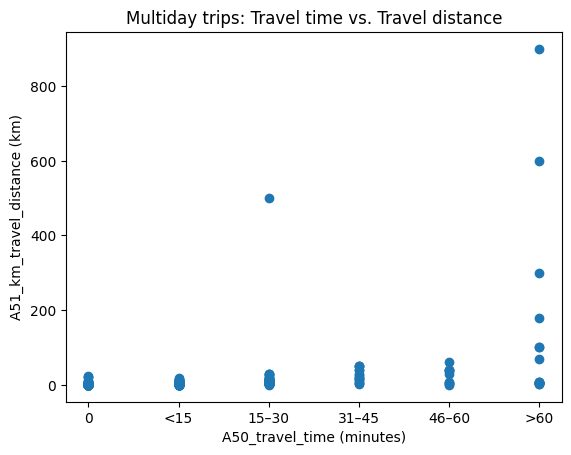

In [20]:
plt.scatter(df_nbt['A50_travel_time'], df_nbt['A51_km_travel_distance'])
plt.xlabel('A50_travel_time (minutes)')
plt.ylabel('A51_km_travel_distance (km)')

labels = {
    1: '0',
    2: '<15',
    3: '15–30',
    4: '31–45',
    5: '46–60',
    6: '>60',
}

ax = plt.gca()
ax.set_xticks(list(labels.keys()))
ax.set_xticklabels(list(labels.values()))

plt.title('Multiday trips: Travel time vs. Travel distance')
plt.show()

## All visitors

In [289]:
df[['A50_travel_time', 'A51_km_travel_distance']].describe()

,A50_travel_time,A51_km_travel_distance
count,451.000000,451.000000
mean,2.485588,19.160492
std,1.488218,71.544092
min,1.000000,0.000000
25%,1.000000,0.200000
50%,2.000000,2.000000
75%,3.000000,10.000000
max,6.000000,900.000000


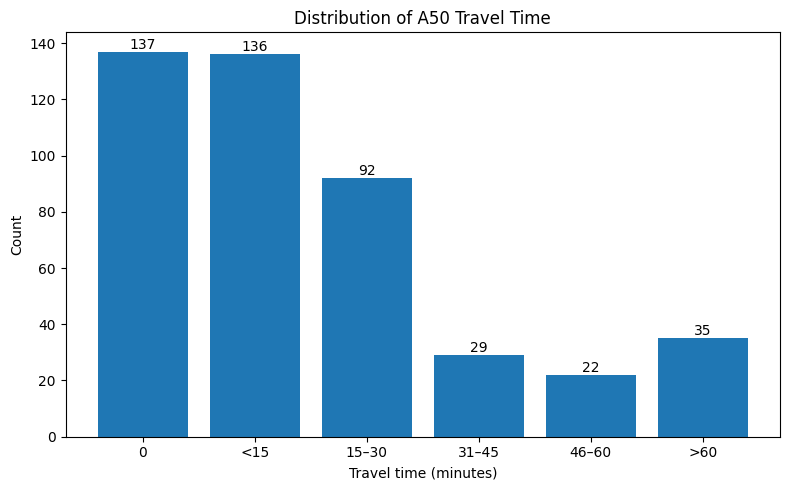

In [24]:
import matplotlib.pyplot as plt
import numpy as np

labels = {
    1: '0',
    2: '<15',
    3: '15–30',
    4: '31–45',
    5: '46–60',
    6: '>60',
}

fig, ax = plt.subplots(figsize=(8, 5))

# Plot histogram and capture counts
counts, bins, patches = ax.hist(
    df['A50_travel_time'],
    bins=6,
    rwidth=0.8
)

# Set custom x-axis labels at bin centers
bin_centers = 0.5 * (bins[:-1] + bins[1:])
ax.set_xticks(bin_centers)
ax.set_xticklabels(labels.values())

# Add value annotations on top of each bin
for count, x in zip(counts, bin_centers):
    ax.text(x, count, int(count), ha='center', va='bottom')

# Add title and axis labels
ax.set_title('Distribution of A50 Travel Time')
ax.set_xlabel('Travel time (minutes)')
ax.set_ylabel('Count')

# Ensure no legend
ax.legend_.remove() if ax.legend_ else None

plt.tight_layout()
plt.show()


In [28]:
import matplotlib.pyplot as plt
import numpy as np

# Distance intervals (km)
bins = [0, 50, 100, 200, 400, 600, 800, 1000]
labels = ['0–50', '50–100', '100–200', '200–400', '400–600', '600–800', '800–1000']

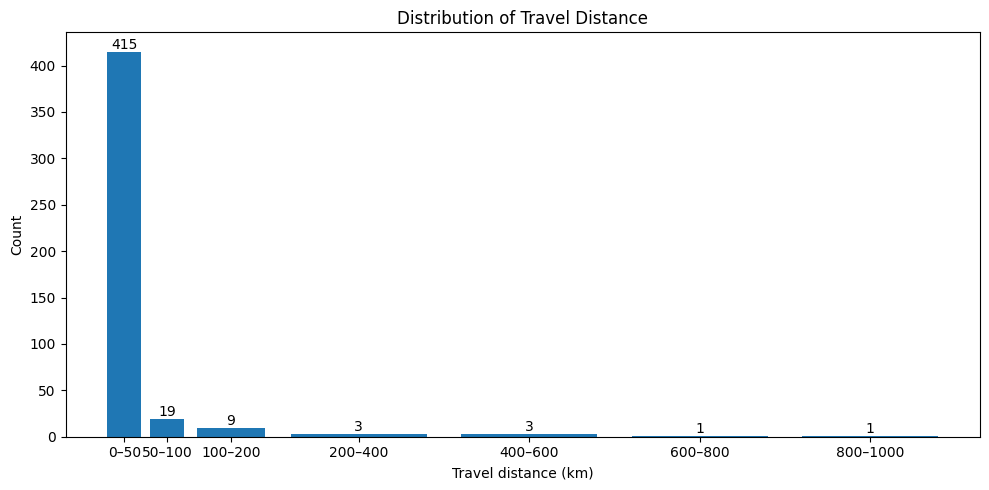

In [31]:
fig, ax = plt.subplots(figsize=(10, 5))

counts, bin_edges, patches = ax.hist(
    df['A51_km_travel_distance'],
    bins=bins,
    rwidth=0.8
)

# Bin centers for labeling
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# X-axis labels
ax.set_xticks(bin_centers)
ax.set_xticklabels(labels)

# Add count annotations
for count, x in zip(counts, bin_centers):
    ax.text(x, count, int(count), ha='center', va='bottom')

# Titles and labels
ax.set_title('Distribution of Travel Distance')
ax.set_xlabel('Travel distance (km)')
ax.set_ylabel('Count')

# Remove legend if any
ax.legend_.remove() if ax.legend_ else None

plt.tight_layout()
plt.show()


# Trip duration

## Daytrip visitors

In [297]:
# TA49h. Duration of last outdoor activity or excursion in hours
df_or[['TA49h_last_activity_duration']].describe()

,TA49h_last_activity_duration
count,165.000000
mean,2.760505
std,2.585787
min,0.266667
25%,1.000000
50%,2.000000
75%,3.166667
max,14.000000


<Axes: xlabel='Duration (hours)', ylabel='Frequency'>

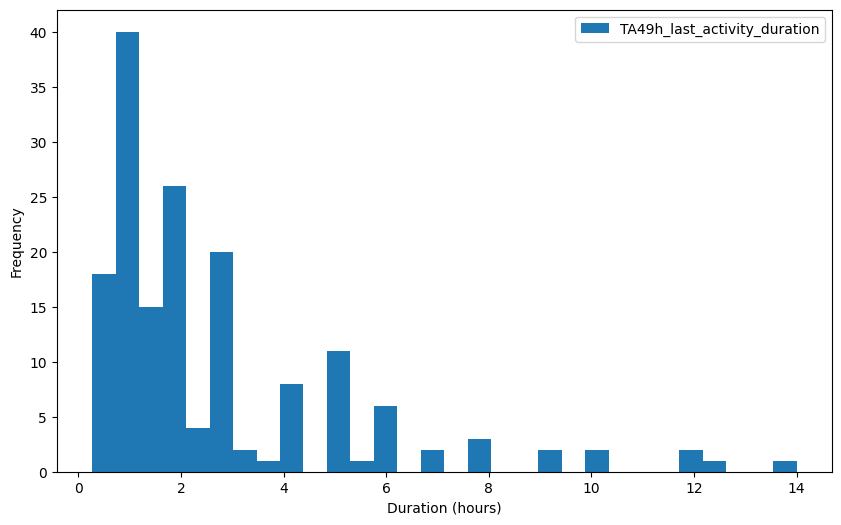

In [314]:
df_or[['TA49h_last_activity_duration']].plot(kind='hist', bins=30, figsize=(10,6), xlabel='Duration (hours)')

## Multiday trip visitors

In [302]:
# A55kesto. Duration of the multi-day trip in days
df_nbt[['A55_last_multi_day_trip_duration']].describe()

,A55_last_multi_day_trip_duration
count,283.000000
mean,5.473498
std,3.822549
min,0.000000
25%,3.000000
50%,5.000000
75%,7.000000
max,30.000000


<Axes: xlabel='Duration (days)', ylabel='Frequency'>

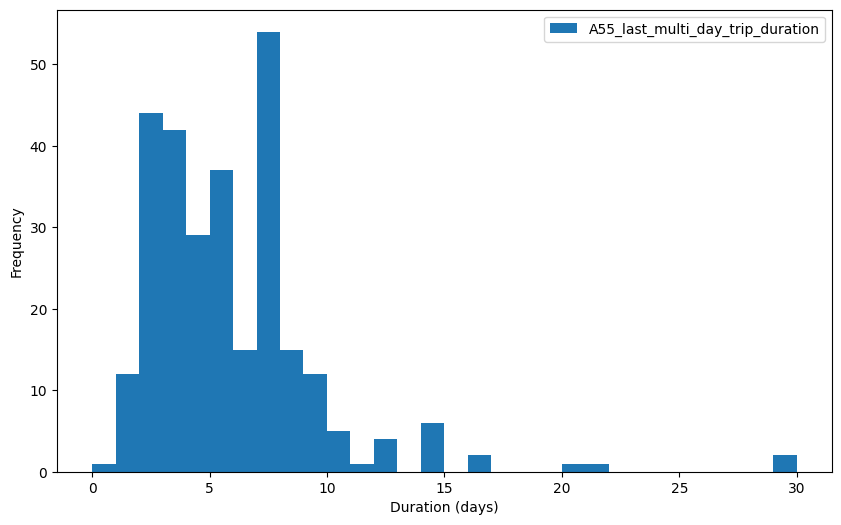

In [315]:
df_nbt[['A55_last_multi_day_trip_duration']].plot(kind='hist', bins=30, figsize=(10,6), xlabel='Duration (days)')

# Opinions

In [322]:
concern_col = ['Ymp1a_concern_logging', 'Ymp1b_concern_climate_change', 'Ymp1c_concern_noise',
               'Ymp1d_concern_water_quality', 'Ymp1e_concern_forest_reduction', 'Ymp1f_concern_species_loss',
               'Ymp1g_concern_alien_species', 'Ymp1h_concern_vegetarian', 'Ymp1i_concern_oil_spill',
               'Ymp1j_concern_landscape_closure', 'Ymp1l_concern_wind_farms', 'Ymp1m_concern_harmful_substances']

def explore_concern(df, concern_col):
    # Rename numeric values for readability
    mapping = {
        1: "Not at all worrying",
        2: "Somewhat worrying",
        3: "Very worrying",
        4: "Extremely worrying",
        5: "Don't know"
    }

    df_c = df[concern_col].replace(mapping)

    # Count responses per category
    counts = df_c.apply(lambda x: x.value_counts()).fillna(0)

    # Reorder categories
    order = ["Not at all worrying", "Somewhat worrying", "Very worrying", "Extremely worrying", "Don't know"]
    counts = counts.reindex(order).fillna(0)

    # Define a color palette
    colors = ["#d73027", "#fc8d59", "#fee08b", "#1a9850", "#bdbdbd"]

    # Plot
    ax = counts.T.plot(kind="barh", stacked=True, figsize=(10, 8), color=colors)

    plt.xlabel("Number of respondents")
    plt.ylabel("Concern")
    plt.title("Concern (Stacked Likert Visualization)")

    # Legend outside the plot
    plt.legend(
        title="Response",
        loc="upper center",
        bbox_to_anchor=(0.5, -0.15),
        ncol=3
    )

    plt.tight_layout()
    plt.show()


In [323]:
frequency_col = ['Ymp2a_frequency_save_energy', 'Ymp2b_frequency_energy_saving_products', 'Ymp2c_frequency_household_waste',
                 'Ymp2d_frequency_eco-products', 'Ymp2e_frequency_organic_food', 'Ymp2f_frequency_avoid_driving',
                 'Ymp2g_frequency_avoid_flying', 'Ymp2h_frequency_vegetarian', 'Ymp2i_frequency_recycled_products']

def explore_frequency(df, frequency_col):
    # Rename numeric values for readability
    mapping = {
        1: "Never",
        2: "Very rarely",
        3: "Quite rarely",
        4: "Quite often",
        5: "Very often",
        6: "Always",
        7: "Don't know",
        8: "Does not concern me"
    }

    df_f = df[frequency_col].replace(mapping)

    # Count responses per category
    counts = df_f.apply(lambda x: x.value_counts()).fillna(0)

    # Reorder categories
    order = ["Never", "Very rarely", "Quite rarely", "Quite often", "Very often", "Always", "Don't know", "Does not concern me"]
    counts = counts.reindex(order).fillna(0)

    # Define a color palette
    colors = ["#d73027", "#fc8d59", "#fee08b", "#97dbb5", "#1a9850", "#0b6632", "#bdbdbd", "#946588"]

    # Plot
    ax = counts.T.plot(kind="barh", stacked=True, figsize=(10, 8), color=colors)

    plt.xlabel("Number of respondents")
    plt.ylabel("Frequency")
    plt.title("Frequency (Stacked Likert Visualization)")

    # Legend outside the plot
    plt.legend(
        title="Response",
        loc="upper center",
        bbox_to_anchor=(0.5, -0.15),
        ncol=3
    )

    plt.tight_layout()
    plt.show()


In [330]:
attitude_col = ['Ymp3a_attitude_avoid_driving', 'Ymp3b_attitude_more_travelling_time', 'Ymp3c_attitude_nearby_destination',
                'Ymp3d_attitude_reduce_purchase_equipments', 'Ymp4a_attitude_low_carbon_travel', 'Ymp4b_attitude_more_travelling_time',
                'Ymp4c_attitude_nearby_destination', 'Ymp4d_attitude_group_travel', 'Ymp4e_attitude_low_carbon_services',
                'Ymp4f_attitude_avoid_trips']

def explore_attitude(df, attitude_col):
    # Rename numeric values for readability
    mapping = {
        1: "Strongly disagree",
        2: "Somewhat disagree",
        3: "Neither agree nor disagree",
        4: "Somewhat agree",
        5: "Strongly agree",
        6: "Not relevant for me"
    }

    df_a = df[attitude_col].replace(mapping)

    # Count responses per category
    counts = df_a.apply(lambda x: x.value_counts()).fillna(0)

    # Reorder categories
    order = ["Strongly disagree", "Somewhat disagree", "Neither agree nor disagree", "Somewhat agree", "Strongly agree", "Not relevant for me"]
    counts = counts.reindex(order).fillna(0)

    # Define a color palette
    colors = ["#d73027", "#fc8d59", "#fee08b", "#97dbb5", "#1a9850", "#bdbdbd"]
   
    # Plot
    ax = counts.T.plot(kind="barh", stacked=True, figsize=(10, 8), color=colors)

    plt.xlabel("Number of respondents")
    plt.ylabel("Attitude")
    plt.title("Attitude (Stacked Likert Visualization)")

    # Legend outside the plot
    plt.legend(
        title="Response",
        loc="upper center",
        bbox_to_anchor=(0.5, -0.15),
        ncol=3
    )

    plt.tight_layout()
    plt.show()



## Daytrip visitors

### Concern

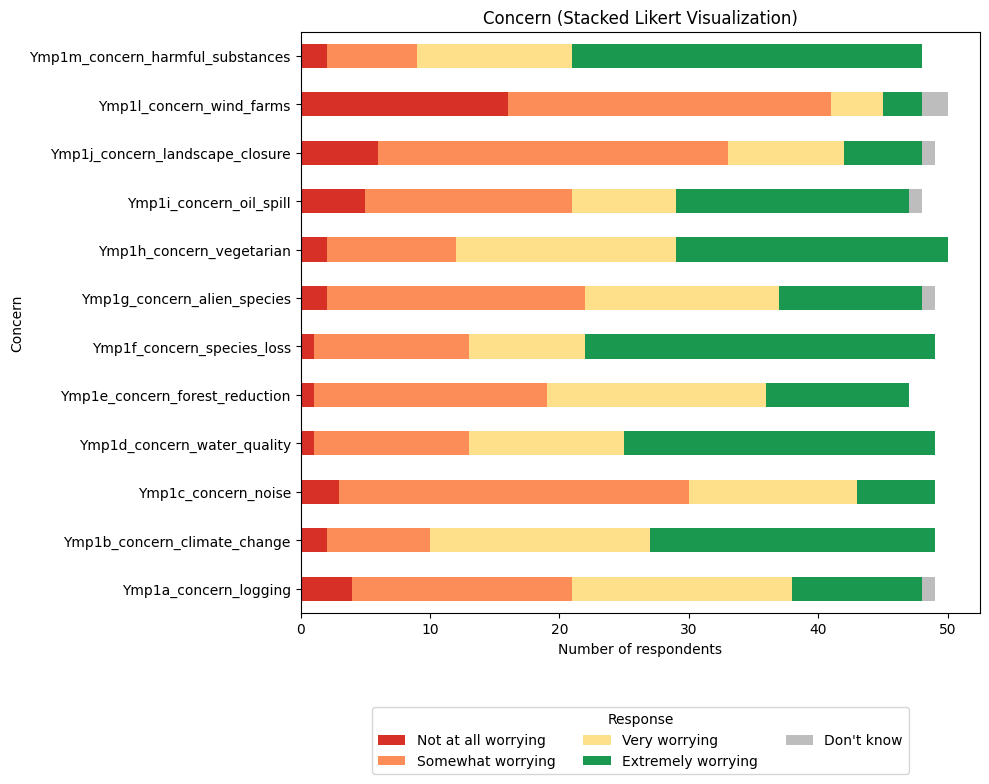

In [325]:
explore_concern(df_or, concern_col)

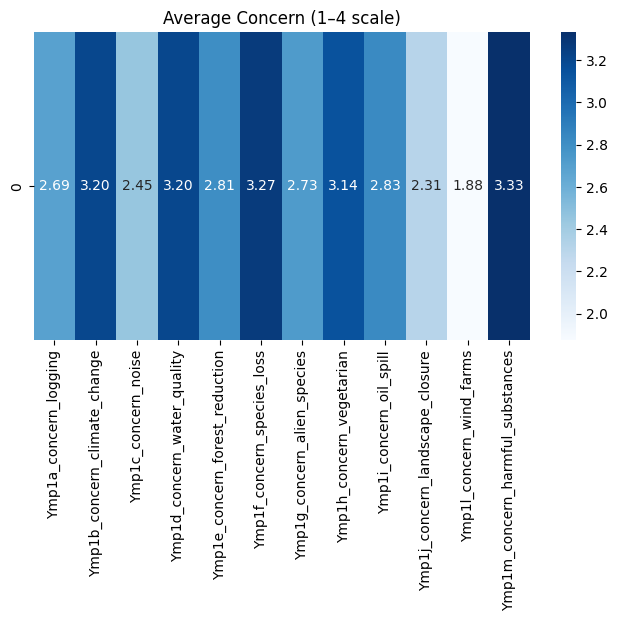

In [326]:
import seaborn as sns
import matplotlib.pyplot as plt

df_clean = df_or[concern_col].replace(5, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8,4))
sns.heatmap(avg.to_frame().T, annot=True, fmt=".2f", cmap="Blues")
plt.title("Average Concern (1–4 scale)")
plt.show()


### Frequency

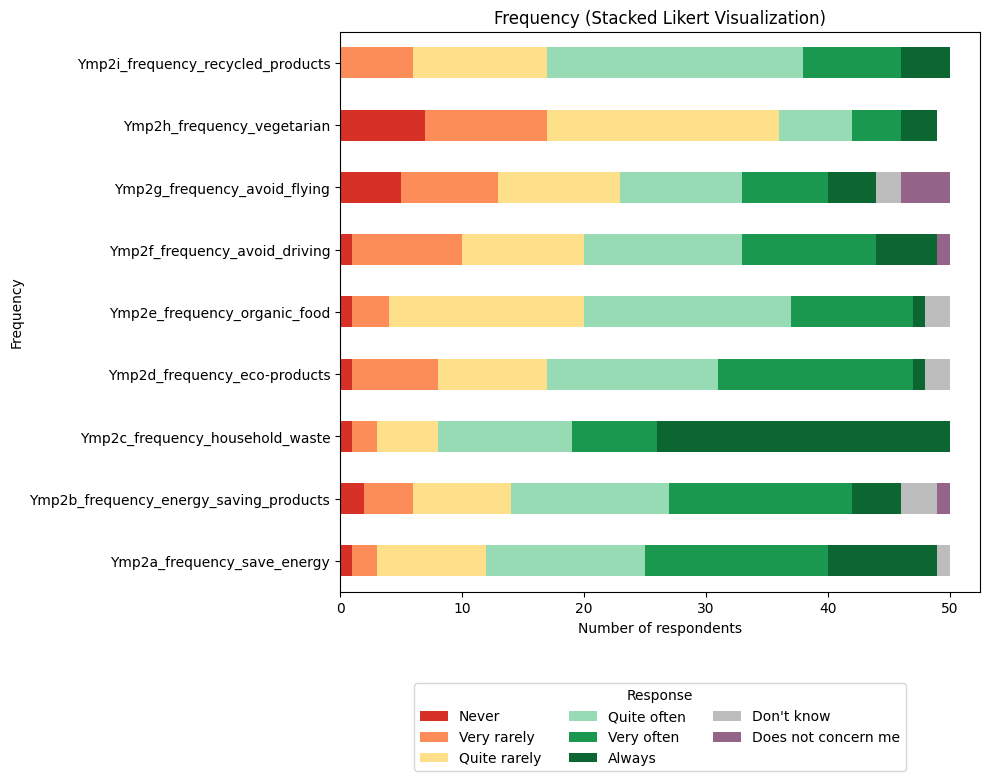

In [327]:
explore_frequency(df_or, frequency_col)

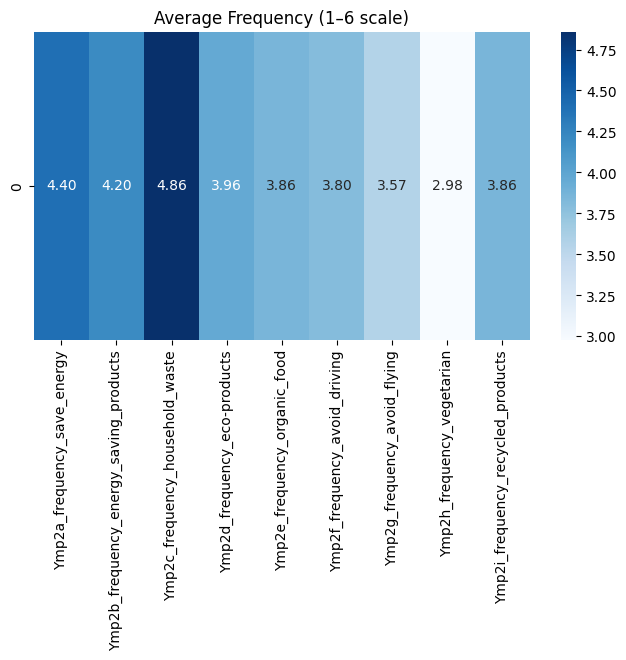

In [328]:
import seaborn as sns
import matplotlib.pyplot as plt

df_clean = df_or[frequency_col].replace(7, np.nan).apply(pd.to_numeric, errors='coerce')
df_clean = df_or[frequency_col].replace(8, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8,4))
sns.heatmap(avg.to_frame().T, annot=True, fmt=".2f", cmap="Blues")
plt.title("Average Frequency (1–6 scale)")
plt.show()


### Attitude

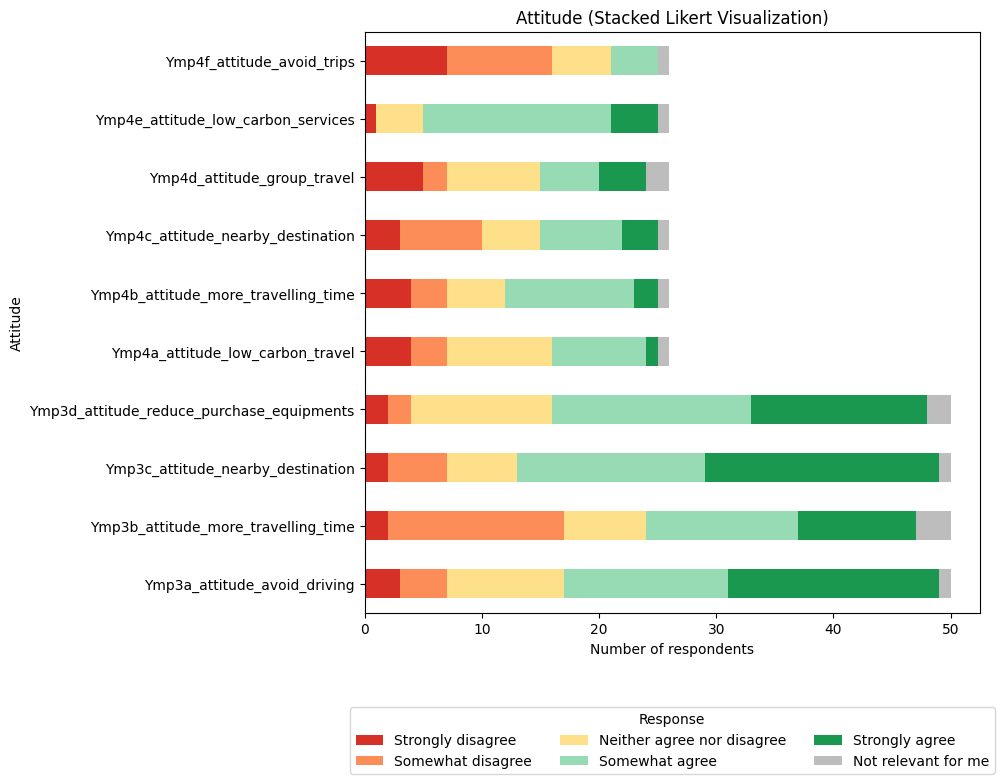

In [331]:
explore_attitude(df_or, attitude_col)

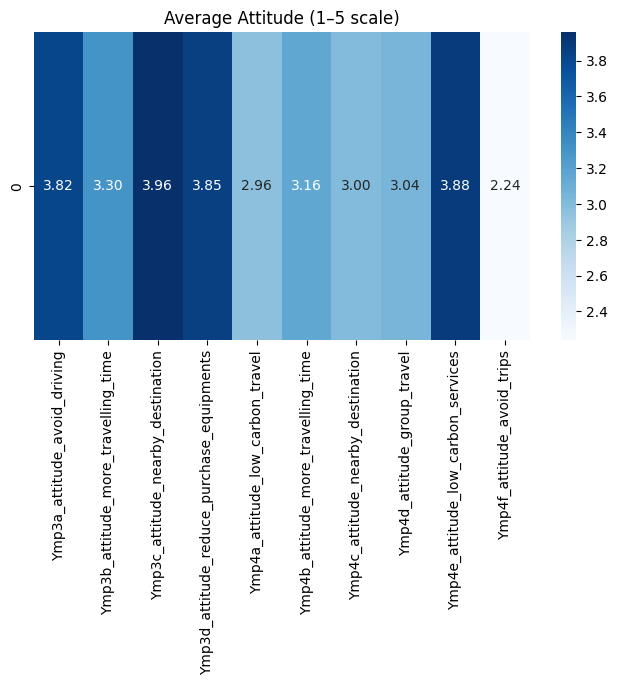

In [338]:
import seaborn as sns
import matplotlib.pyplot as plt

df_clean = df_or[attitude_col].replace(6, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8,4))
sns.heatmap(avg.to_frame().T, annot=True, fmt=".2f", cmap="Blues")
plt.title("Average Attitude (1–5 scale)")
plt.show()


## Multiday trip visitors

### Concern

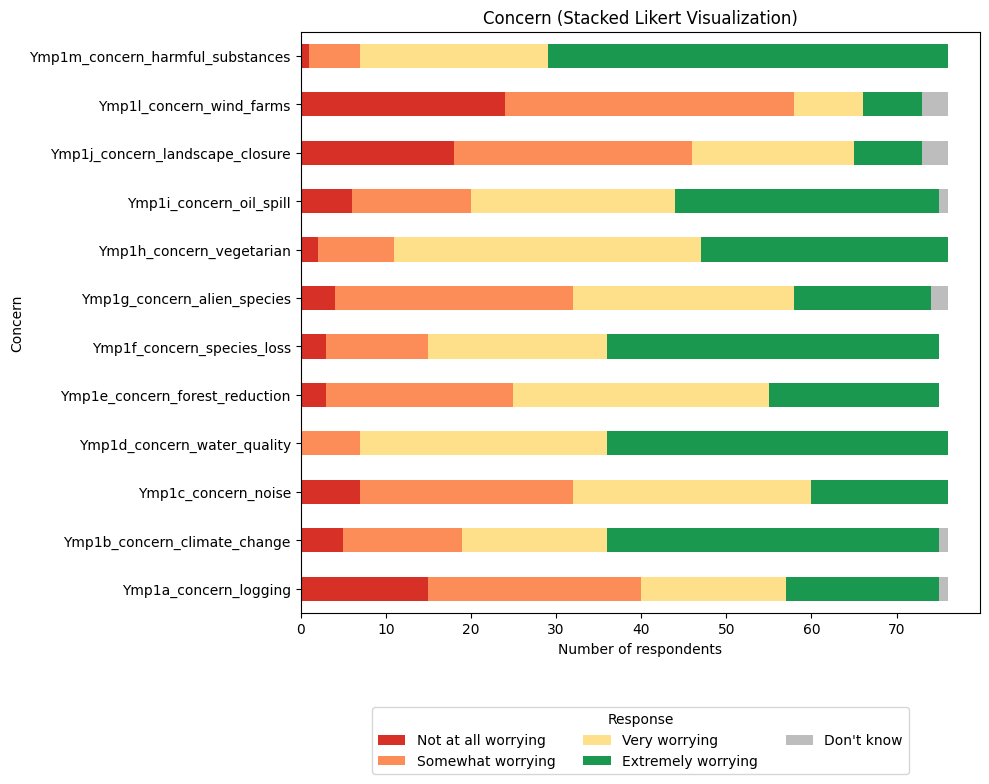

In [333]:
explore_concern(df_nbt, concern_col)

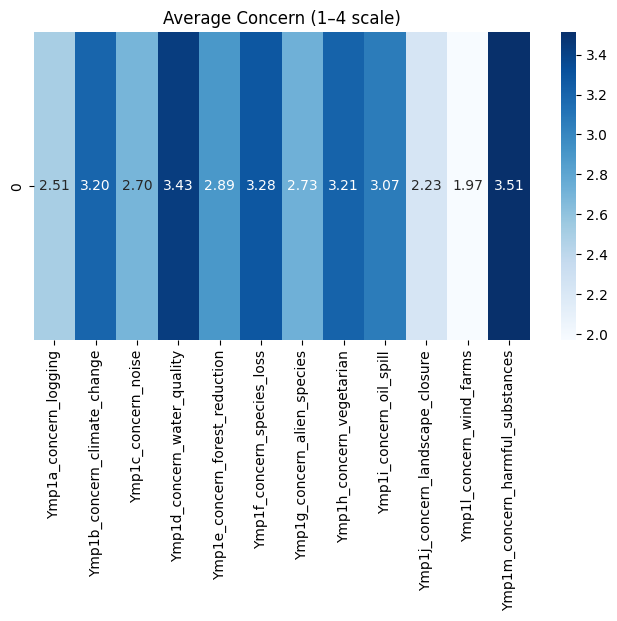

In [337]:
import seaborn as sns
import matplotlib.pyplot as plt

df_clean = df_nbt[concern_col].replace(5, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8,4))
sns.heatmap(avg.to_frame().T, annot=True, fmt=".2f", cmap="Blues")
plt.title("Average Concern (1–4 scale)")
plt.show()


### Frequency

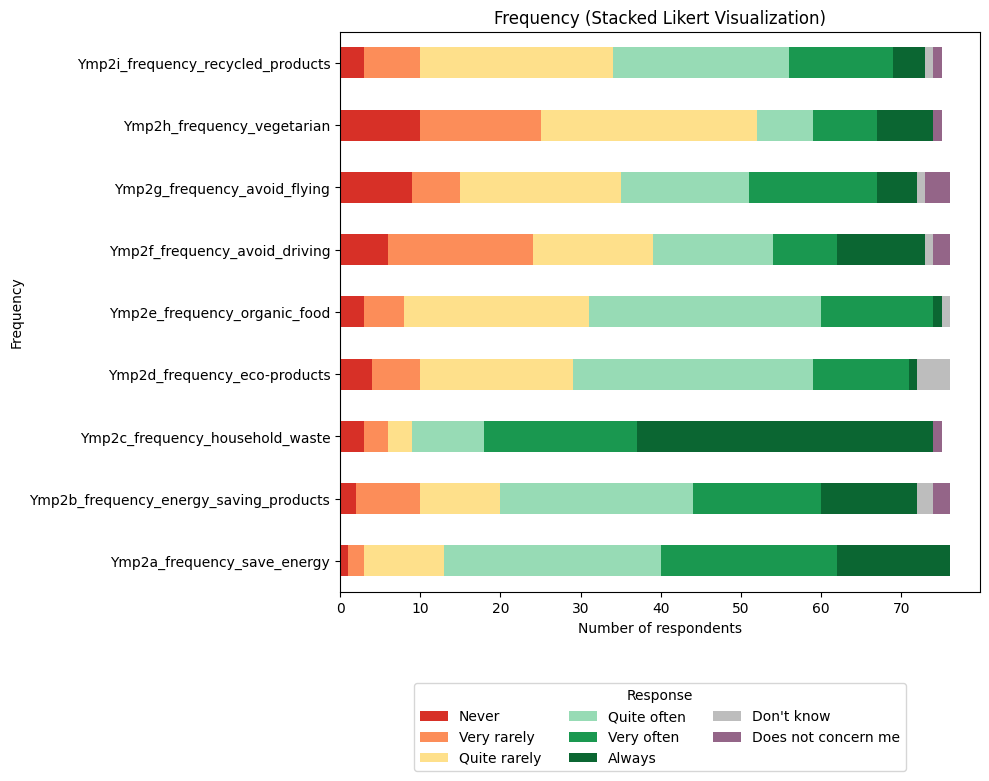

In [339]:
explore_frequency(df_nbt, frequency_col)

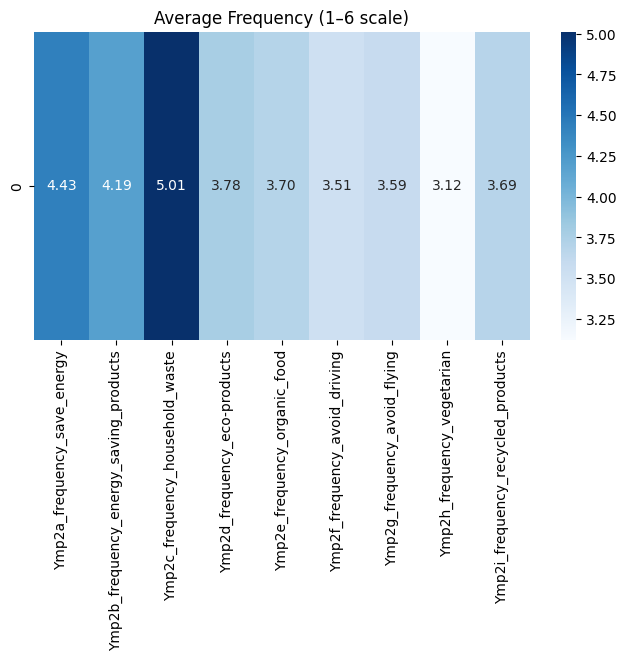

In [340]:
import seaborn as sns
import matplotlib.pyplot as plt

df_clean = df_nbt[frequency_col].replace(7, np.nan).apply(pd.to_numeric, errors='coerce')
df_clean = df_nbt[frequency_col].replace(8, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8,4))
sns.heatmap(avg.to_frame().T, annot=True, fmt=".2f", cmap="Blues")
plt.title("Average Frequency (1–6 scale)")
plt.show()


### Attitude

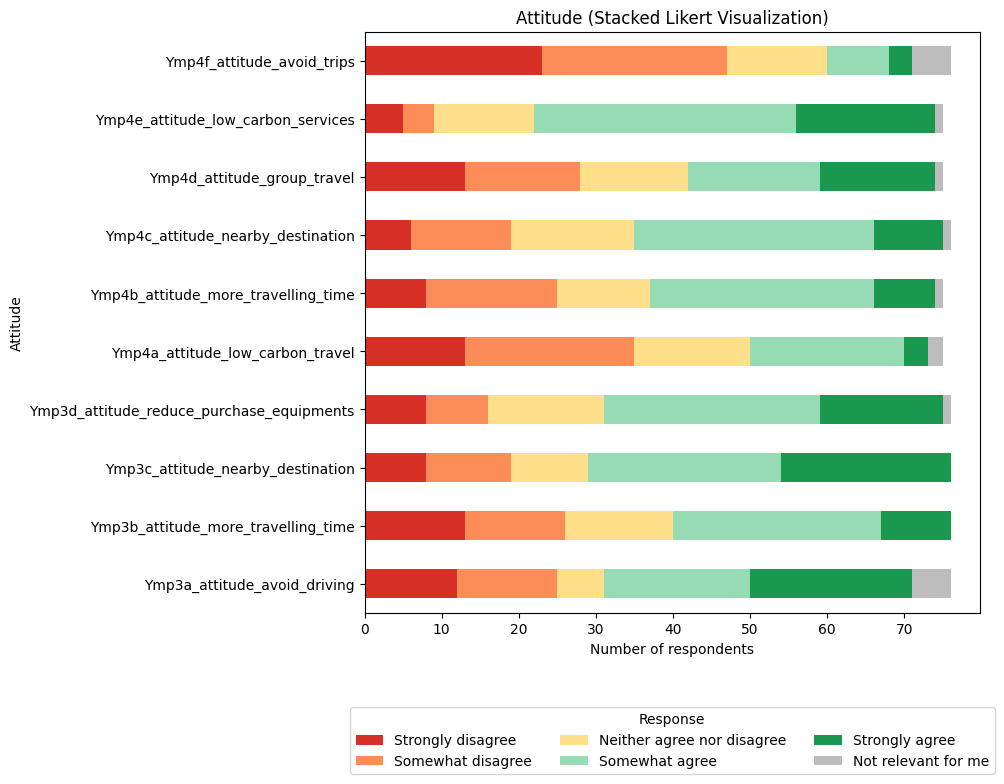

In [341]:
explore_attitude(df_nbt, attitude_col)

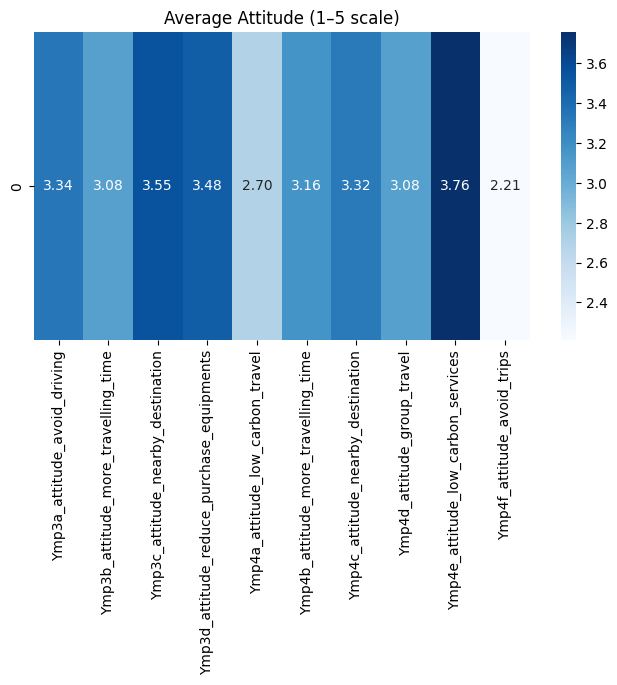

In [342]:
import seaborn as sns
import matplotlib.pyplot as plt

df_clean = df_nbt[attitude_col].replace(6, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8,4))
sns.heatmap(avg.to_frame().T, annot=True, fmt=".2f", cmap="Blues")
plt.title("Average Attitude (1–5 scale)")
plt.show()


## All visitors

### Concern

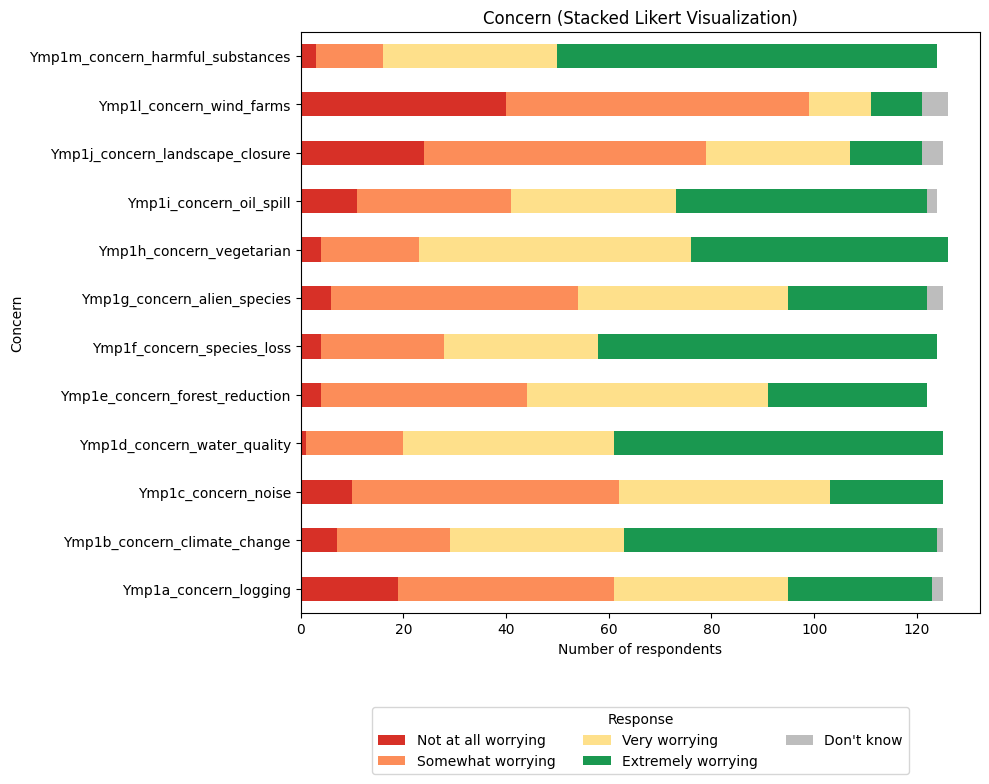

In [343]:
explore_concern(df, concern_col)

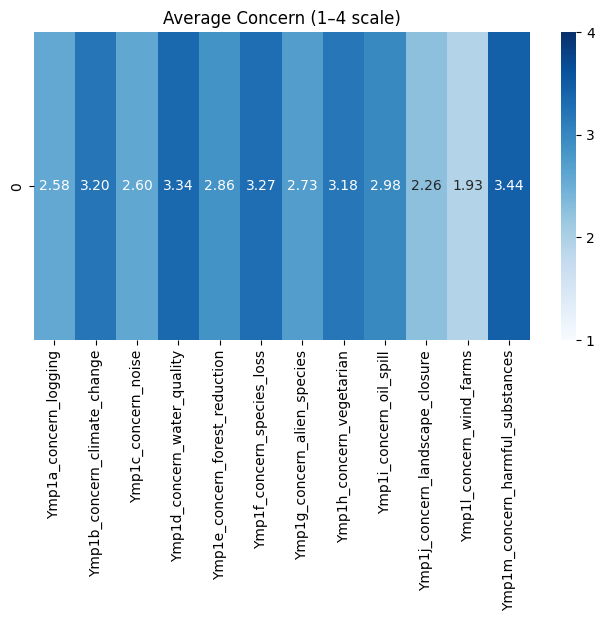

In [486]:
import seaborn as sns
import matplotlib.pyplot as plt

df_clean = df[concern_col].replace(5, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8,4))
ax = sns.heatmap(
    avg.to_frame().T,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=1,
    vmax=4,
    cbar_kws={'ticks': [1, 2, 3, 4]}
)
plt.title("Average Concern (1–4 scale)")
plt.show()


### Frequency

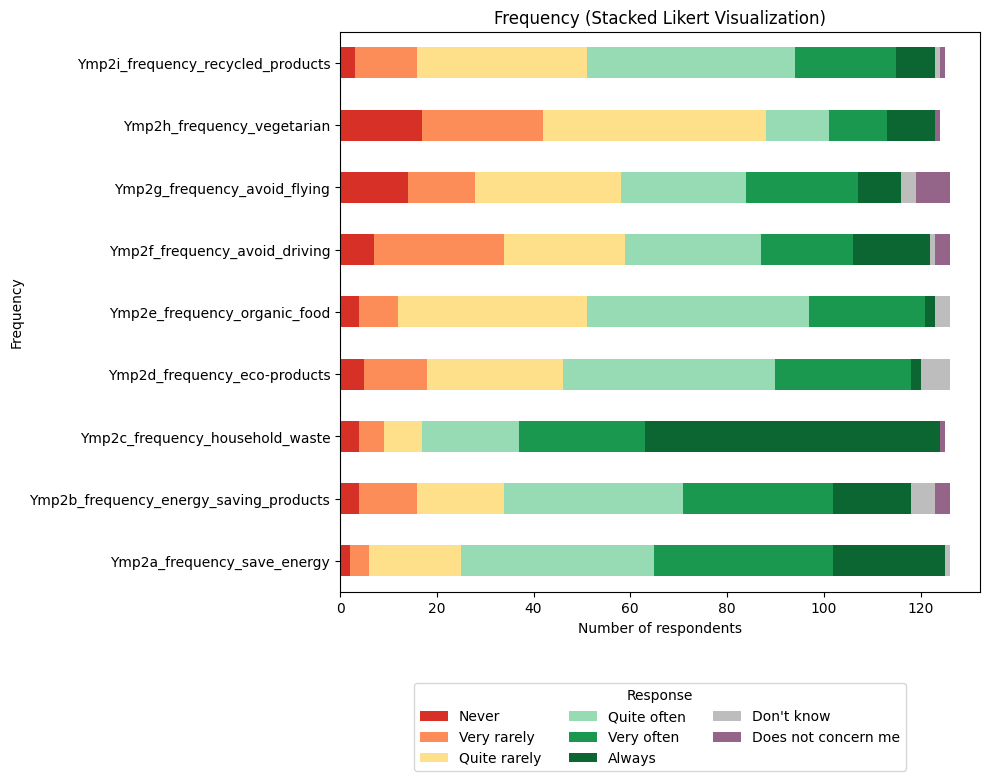

In [345]:
explore_frequency(df, frequency_col)

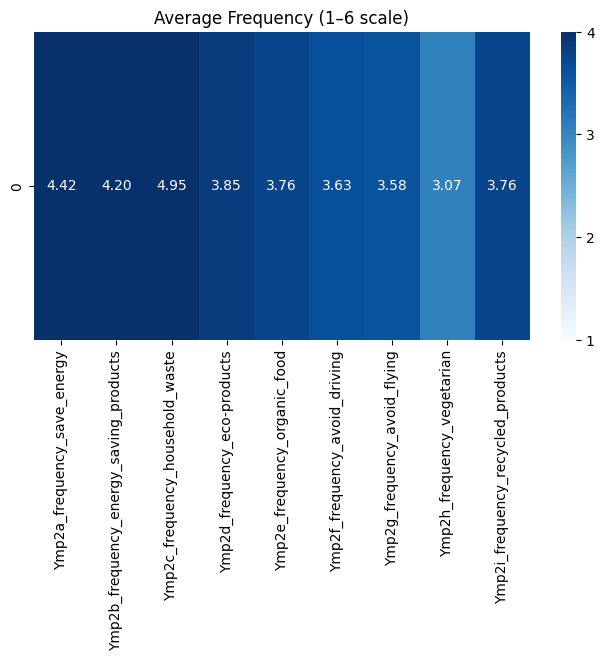

In [487]:
import seaborn as sns
import matplotlib.pyplot as plt

df_clean = df[frequency_col].replace(7, np.nan).apply(pd.to_numeric, errors='coerce')
df_clean = df[frequency_col].replace(8, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8,4))
ax = sns.heatmap(
    avg.to_frame().T,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=1,
    vmax=4,
    cbar_kws={'ticks': [1, 2, 3, 4]}
)
plt.title("Average Frequency (1–6 scale)")
plt.show()


### Attitude

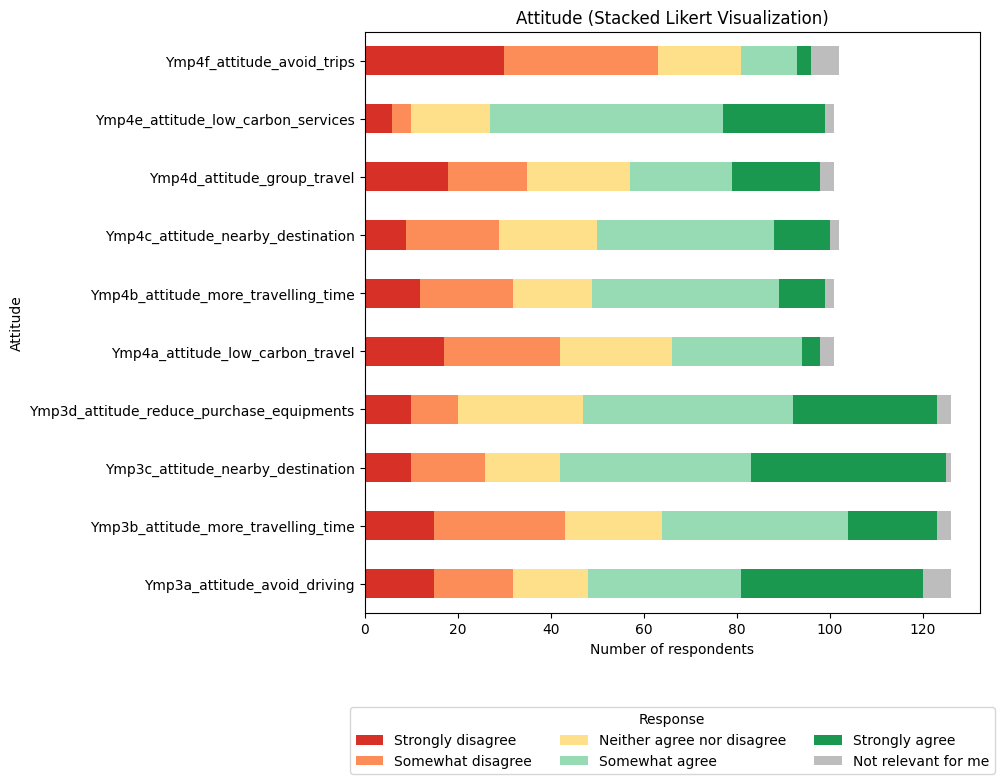

In [347]:
explore_attitude(df, attitude_col)

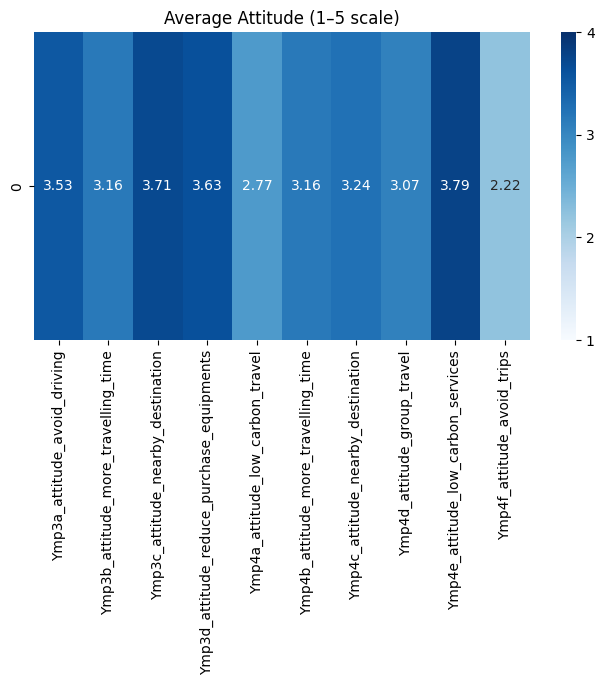

In [488]:
import seaborn as sns
import matplotlib.pyplot as plt

df_clean = df[attitude_col].replace(6, np.nan).apply(pd.to_numeric, errors='coerce')
avg = df_clean.mean()

plt.figure(figsize=(8,4))
ax = sns.heatmap(
    avg.to_frame().T,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=1,
    vmax=4,
    cbar_kws={'ticks': [1, 2, 3, 4]}
)
plt.title("Average Attitude (1–5 scale)")
plt.show()


# Area characteristics

In [481]:
area_characteristics_col = [
    'B_6a_area_footpath', 'B_6b_area_built_path', 'B_6c_area_references', 'B_6d_area_signposting', 'B_6e_area_visitor_center', 'B_6f_area_outdoor_house',
    'B_6g_area_deserted_house', 'B_6h_area_fireplace', 'B_6i_area_beach', 'B_6j_area_camping_area', 'B_6k_area_ski_trail', 'B_6l_area_ski_slope',
    'B_6m_area_boat_dock', 'B_6n_area_other', 'B_7a_lawn', 'B_7b_forest', 'B_7suo_swamp', 'B_7c_cultivated_field',
    'B_7d_meadow', 'B_7e_mountain', 'B_7f_lake', 'B_7g_sea', 'B_7h_river', 'B_7i_berry', 'B_7j_mushroom', 'B_7k_hunting', 'B_7l_fishing',
    'B_7m_natural_attraction', 'B_7n_other']

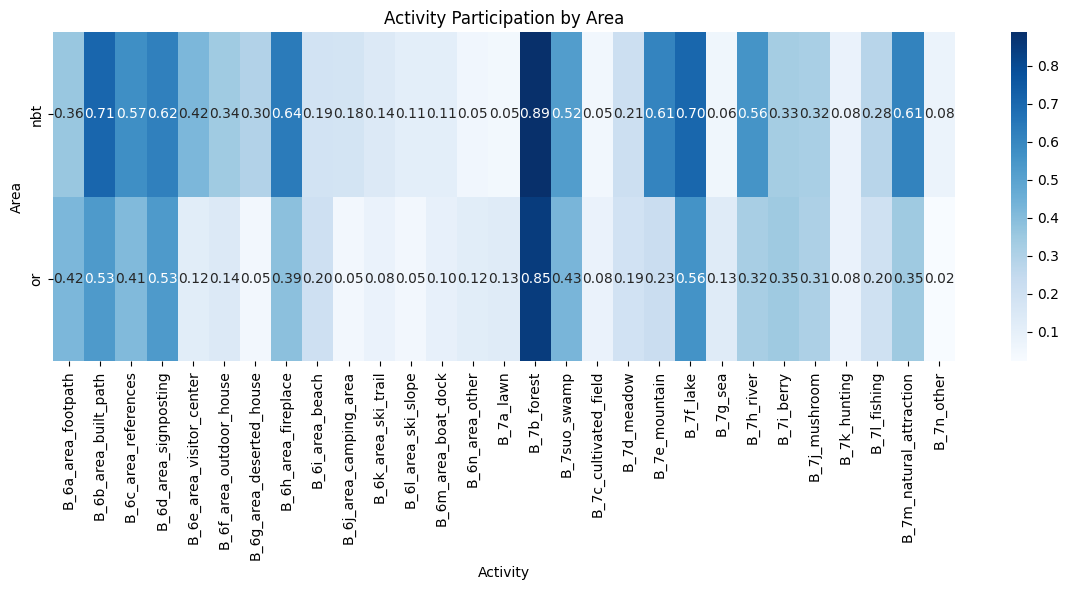

In [482]:
import seaborn as sns

group_means = df.groupby('source')[area_characteristics_col].mean()

plt.figure(figsize=(12, 6))
sns.heatmap(
    group_means,
    annot=True,
    fmt=".2f",
    cmap='Blues'
)

plt.title('Activity Participation by Area')
plt.xlabel('Activity')
plt.ylabel('Area')
plt.tight_layout()
plt.show()


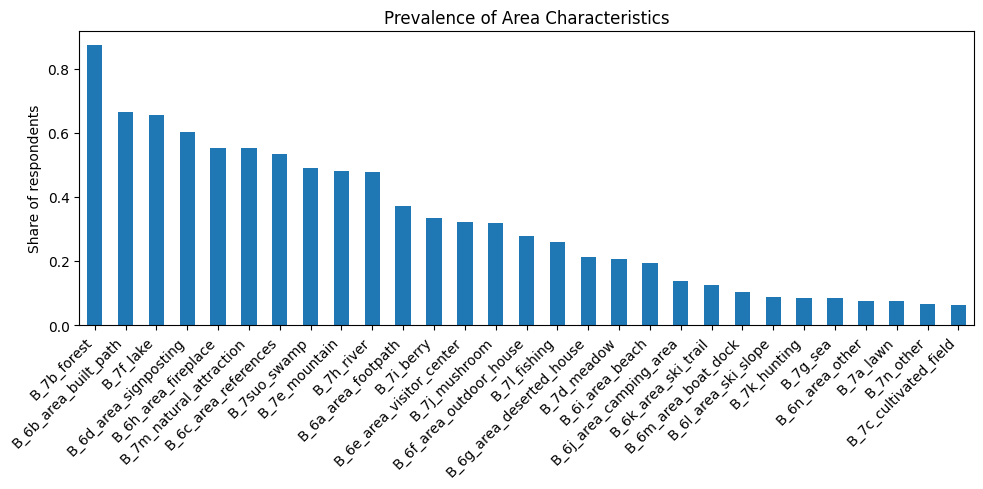

In [483]:
import matplotlib.pyplot as plt

shares = df[area_characteristics_col].mean().sort_values(ascending=False)

ax = shares.plot(kind='bar', figsize=(10, 5))
ax.set_ylabel('Share of respondents')
ax.set_title('Prevalence of Area Characteristics')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


# Accompany

## Daytrip visitors

B_2_accompany
1.0    70
2.0    69
3.0    24
6.0     1
7.0     1
Name: count, dtype: int64


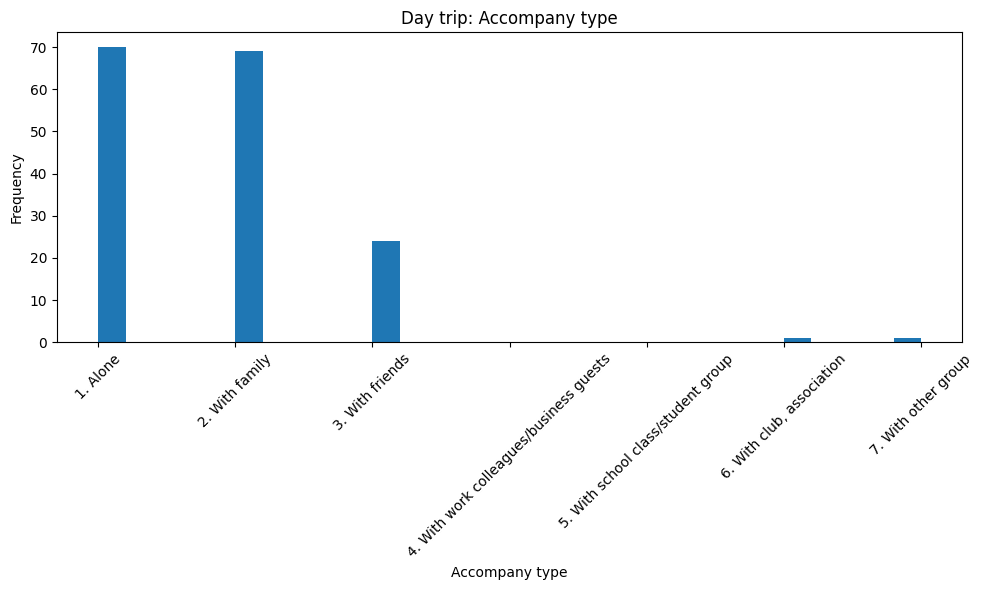

In [38]:
# Plot accompany type for the full dataset
import matplotlib.pyplot as plt

print(df_or['B_2_accompany'].value_counts().sort_index())

ax = df_or['B_2_accompany'].plot(
    kind='hist',
    bins=30,
    figsize=(10, 6),
    xlabel='Accompany type'
)

# Replace x ticks
ax.set_xticks([1, 2, 3, 4, 5, 6, 7])
ax.set_xticklabels(['1. Alone', '2. With family', '3. With friends', '4. With work colleagues/business guests',
                    '5. With school class/student group', '6. With club, association', '7. With other group'],
                    rotation=45)
ax.set_title('Day trip: Accompany type')

plt.tight_layout()
plt.show()


In [ ]:
# Average number of accompany for each accompany type
df_or.groupby('B_2_accompany')['B_2a_accompany_num'].mean()

B_2_accompany
1.0         NaN
2.0    1.676471
3.0    2.250000
6.0    5.000000
7.0    6.000000
Name: B_2a_accompany_num, dtype: float64

In [ ]:
# Frequency counts for accompany with children (1. yes, 2. no)
df_or[['B_2b_accompany_children']].value_counts()

B_2b_accompany_children
2.0                        74
1.0                        21
Name: count, dtype: int64

In [ ]:
# Gender distribution by accompany type (1. male, 2. female, 3. other)
df_or.groupby('B_2_accompany')['A1_gender'].value_counts(normalize=True).unstack()

A1_gender,1,2,3
B_2_accompany,,,
1.0,0.600000,0.385714,0.014286
2.0,0.565217,0.434783,NaN
3.0,0.791667,0.208333,NaN
6.0,1.000000,NaN,NaN
7.0,NaN,1.000000,NaN


In [412]:
# Age distribution by accompany type (1. <16, 2. 16-24, 3. 25-34, 4. 35-44, 5. 45-54, 6. 55-64, 7. 65+)
df_or.groupby('B_2_accompany')['A2_age'].value_counts(normalize=True).unstack()

A2_age,1,2,3,4,5,6,7,8
B_2_accompany,,,,,,,,
1.0,0.014286,0.128571,0.128571,0.200000,0.128571,0.257143,0.114286,0.028571
2.0,NaN,0.086957,0.202899,0.231884,0.144928,0.144928,0.144928,0.043478
3.0,NaN,0.166667,0.166667,0.041667,0.208333,0.125000,0.250000,0.041667
6.0,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN
7.0,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN


## Multiday trip visitors

B_2_accompany
1.0     23
2.0    169
3.0     74
4.0      3
5.0      4
6.0      8
7.0      5
Name: count, dtype: int64


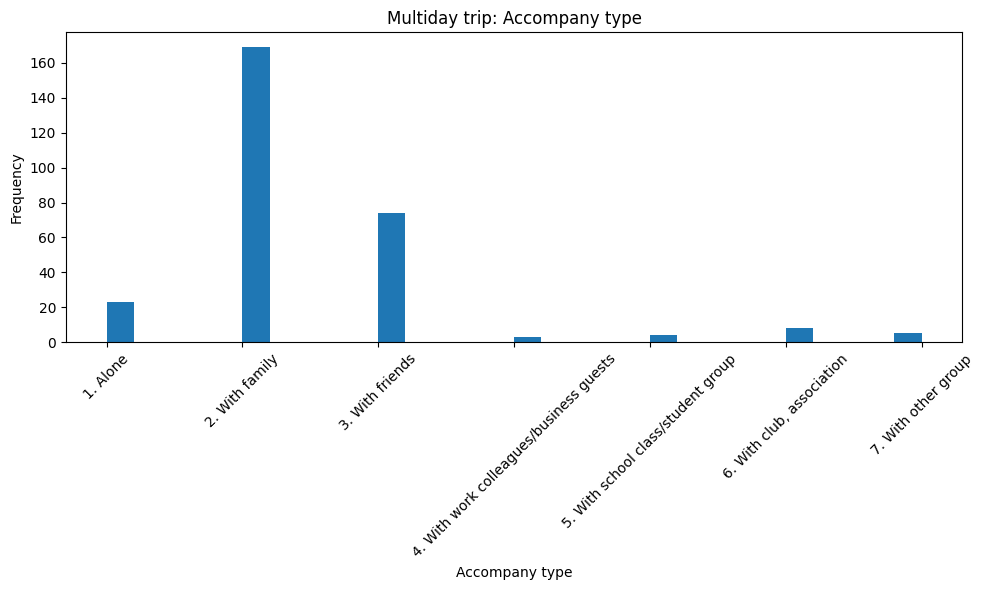

In [39]:
# Plot accompany type for the full dataset
import matplotlib.pyplot as plt

print(df_nbt['B_2_accompany'].value_counts().sort_index())

ax = df_nbt['B_2_accompany'].plot(
    kind='hist',
    bins=30,
    figsize=(10, 6),
    xlabel='Accompany type'
)

# Replace x ticks
ax.set_xticks([1, 2, 3, 4, 5, 6, 7])
ax.set_xticklabels(['1. Alone', '2. With family', '3. With friends', '4. With work colleagues/business guests',
                    '5. With school class/student group', '6. With club, association', '7. With other group'],
                    rotation=45)
ax.set_title('Multiday trip: Accompany type')

plt.tight_layout()
plt.show()


In [ ]:
# Average number of accompany for each accompany type
df_nbt.groupby('B_2_accompany')['B_2a_accompany_num'].mean()

B_2_accompany
1.0         NaN
2.0    1.881657
3.0    2.662162
4.0    4.333333
5.0    5.000000
6.0    5.250000
7.0    4.800000
Name: B_2a_accompany_num, dtype: float64

In [ ]:
# Frequency counts for accompany with children (1. yes, 2. no)
df_nbt[['B_2b_accompany_children']].value_counts()

B_2b_accompany_children
2.0                        211
1.0                         51
Name: count, dtype: int64

In [413]:
# Gender distribution by accompany type (1. male, 2. female, 3. other)
df_nbt.groupby('B_2_accompany')['A1_gender'].value_counts(normalize=True).unstack()

A1_gender,1,2,3
B_2_accompany,,,
1.0,0.565217,0.434783,NaN
2.0,0.437870,0.556213,0.005917
3.0,0.594595,0.405405,NaN
4.0,0.666667,0.333333,NaN
5.0,0.250000,0.750000,NaN
6.0,0.375000,0.500000,0.125000
7.0,0.400000,0.600000,NaN


In [414]:
# Age distribution by accompany type (1. <16, 2. 16-24, 3. 25-34, 4. 35-44, 5. 45-54, 6. 55-64, 7. 65+)
df_nbt.groupby('B_2_accompany')['A2_age'].value_counts(normalize=True).unstack()

A2_age,1,2,3,4,5,6,7,8
B_2_accompany,,,,,,,,
1.0,NaN,NaN,0.173913,0.086957,0.391304,0.260870,0.086957,NaN
2.0,0.023669,0.041420,0.218935,0.248521,0.230769,0.112426,0.112426,0.011834
3.0,NaN,0.067568,0.243243,0.135135,0.135135,0.243243,0.148649,0.027027
4.0,NaN,NaN,0.333333,0.666667,NaN,NaN,NaN,NaN
5.0,NaN,0.750000,0.250000,NaN,NaN,NaN,NaN,NaN
6.0,NaN,0.375000,0.250000,NaN,0.250000,NaN,0.125000,NaN
7.0,0.200000,0.400000,NaN,NaN,0.200000,NaN,0.200000,NaN


## All visitors

B_2_accompany
1.0     93
2.0    238
3.0     98
4.0      3
5.0      4
6.0      9
7.0      6
Name: count, dtype: int64


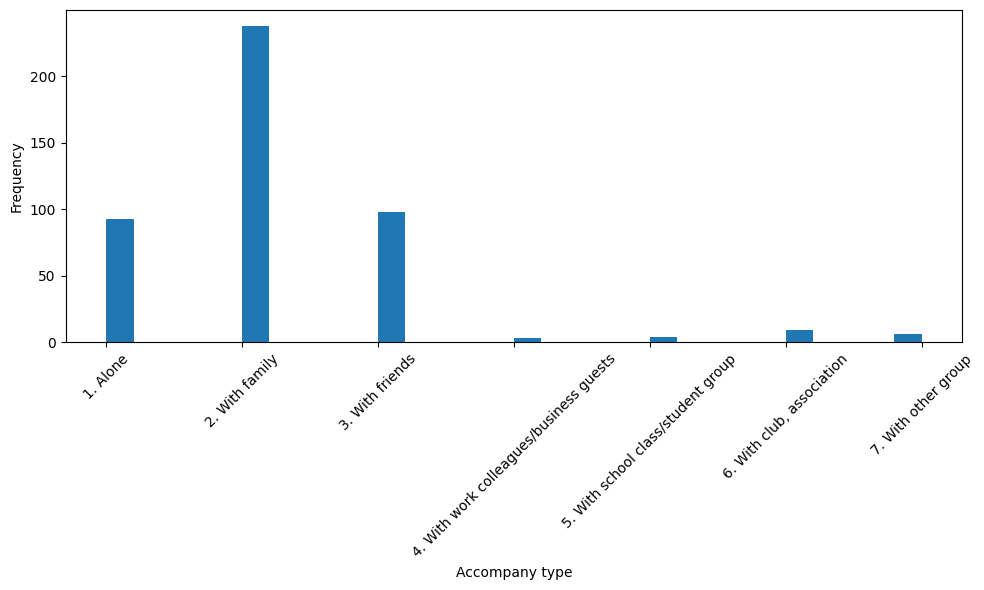

In [ ]:
# Plot accompany type for the full dataset
import matplotlib.pyplot as plt

print(df['B_2_accompany'].value_counts().sort_index())

ax = df['B_2_accompany'].plot(
    kind='hist',
    bins=30,
    figsize=(10, 6),
    xlabel='Accompany type'
)

# Replace x ticks
ax.set_xticks([1, 2, 3, 4, 5, 6, 7])
ax.set_xticklabels(['1. Alone', '2. With family', '3. With friends', '4. With work colleagues/business guests',
                    '5. With school class/student group', '6. With club, association', '7. With other group'],
                    rotation=45)

plt.tight_layout()
plt.show()


In [ ]:
# Average number of accompany for each accompany type
df.groupby('B_2_accompany')['B_2a_accompany_num'].mean()

B_2_accompany
1.0         NaN
2.0    1.822785
3.0    2.561224
4.0    4.333333
5.0    5.000000
6.0    5.222222
7.0    5.000000
Name: B_2a_accompany_num, dtype: float64

In [ ]:
# Frequency counts for accompany with children (1. yes, 2. no)
df[['B_2b_accompany_children']].value_counts()

B_2b_accompany_children
2.0                        285
1.0                         72
Name: count, dtype: int64

In [416]:
# Gender distribution by accompany type (1. male, 2. female, 3. other)
df.groupby('B_2_accompany')['A1_gender'].value_counts(normalize=True).unstack()

A1_gender,1,2,3
B_2_accompany,,,
1.0,0.591398,0.397849,0.010753
2.0,0.474790,0.521008,0.004202
3.0,0.642857,0.357143,NaN
4.0,0.666667,0.333333,NaN
5.0,0.250000,0.750000,NaN
6.0,0.444444,0.444444,0.111111
7.0,0.333333,0.666667,NaN


In [417]:
# Age distribution by accompany type (1. <16, 2. 16-24, 3. 25-34, 4. 35-44, 5. 45-54, 6. 55-64, 7. 65+)
df.groupby('B_2_accompany')['A2_age'].value_counts(normalize=True).unstack()

A2_age,1,2,3,4,5,6,7,8
B_2_accompany,,,,,,,,
1.0,0.010753,0.096774,0.139785,0.172043,0.193548,0.258065,0.107527,0.021505
2.0,0.016807,0.054622,0.214286,0.243697,0.205882,0.121849,0.121849,0.021008
3.0,NaN,0.091837,0.224490,0.112245,0.153061,0.214286,0.173469,0.030612
4.0,NaN,NaN,0.333333,0.666667,NaN,NaN,NaN,NaN
5.0,NaN,0.750000,0.250000,NaN,NaN,NaN,NaN,NaN
6.0,NaN,0.333333,0.222222,NaN,0.222222,0.111111,0.111111,NaN
7.0,0.166667,0.333333,NaN,NaN,0.166667,NaN,0.333333,NaN


# Activities across visiting groups

In [397]:
df.groupby('B_2_accompany')['activity'].value_counts(normalize=True).unstack().fillna(0)

activity,Boating,Camping,Cycling,Fishing,Forest,Golf,Guided tour,Hunting,Nature product collection,Outdoor activities with children,Outdoor activities with dogs,Picnicking,RoNature photography,Running,Skating,Skiing,Snowmobiling,Swimming,Treasure hunting,Walking
B_2_accompany,,,,,,,,,,,,,,,,,,,,
1.0,0.010753,0.021505,0.118280,0.021505,0.010753,0.000000,0.000000,0.000000,0.010753,0.010753,0.150538,0.010753,0.064516,0.075269,0.000000,0.032258,0.010753,0.000000,0.021505,0.430108
2.0,0.037815,0.037815,0.021008,0.037815,0.000000,0.004202,0.004202,0.025210,0.016807,0.025210,0.029412,0.025210,0.042017,0.012605,0.004202,0.121849,0.004202,0.004202,0.012605,0.533613
3.0,0.020408,0.051020,0.010204,0.122449,0.000000,0.040816,0.020408,0.051020,0.010204,0.010204,0.040816,0.040816,0.030612,0.010204,0.000000,0.061224,0.040816,0.010204,0.010204,0.418367
4.0,0.333333,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.666667
5.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
6.0,0.111111,0.111111,0.000000,0.000000,0.000000,0.111111,0.000000,0.111111,0.111111,0.000000,0.000000,0.000000,0.000000,0.111111,0.000000,0.111111,0.000000,0.000000,0.111111,0.111111
7.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.166667,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.166667,0.000000,0.000000,0.000000,0.666667


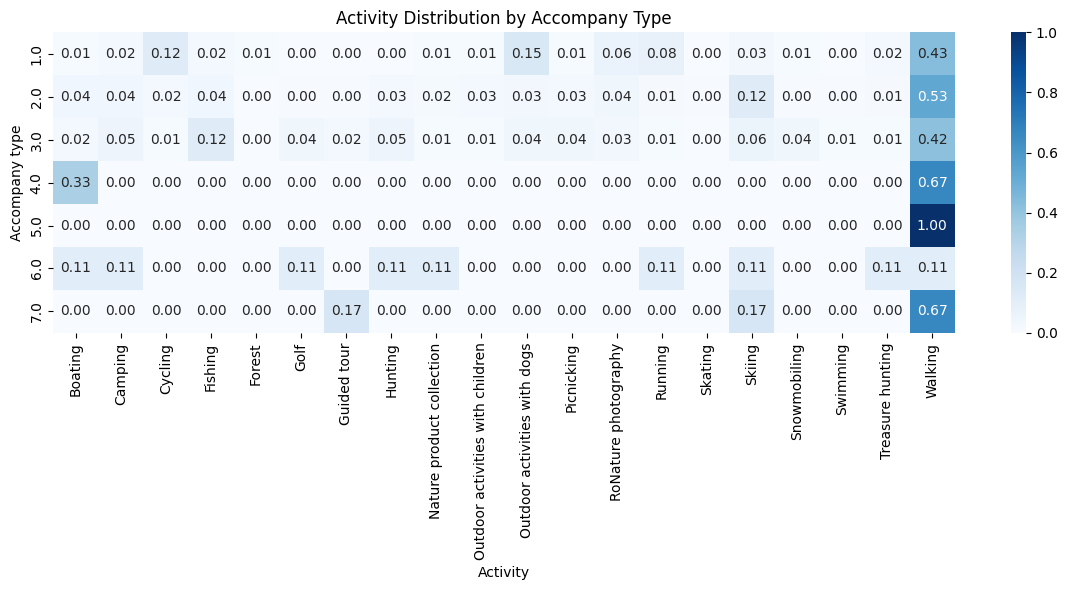

In [399]:
import seaborn as sns
import matplotlib.pyplot as plt

table = (
    df.groupby('B_2_accompany')['activity']
      .value_counts(normalize=True)
      .unstack()
      .fillna(0)
)

plt.figure(figsize=(12, 6))
sns.heatmap(
    table,
    annot=True,
    fmt=".2f",
    cmap="Blues"
)

plt.xlabel('Activity')
plt.ylabel('Accompany type')
plt.title('Activity Distribution by Accompany Type')
plt.tight_layout()
plt.show()


# Demographics across activities 

## Gender

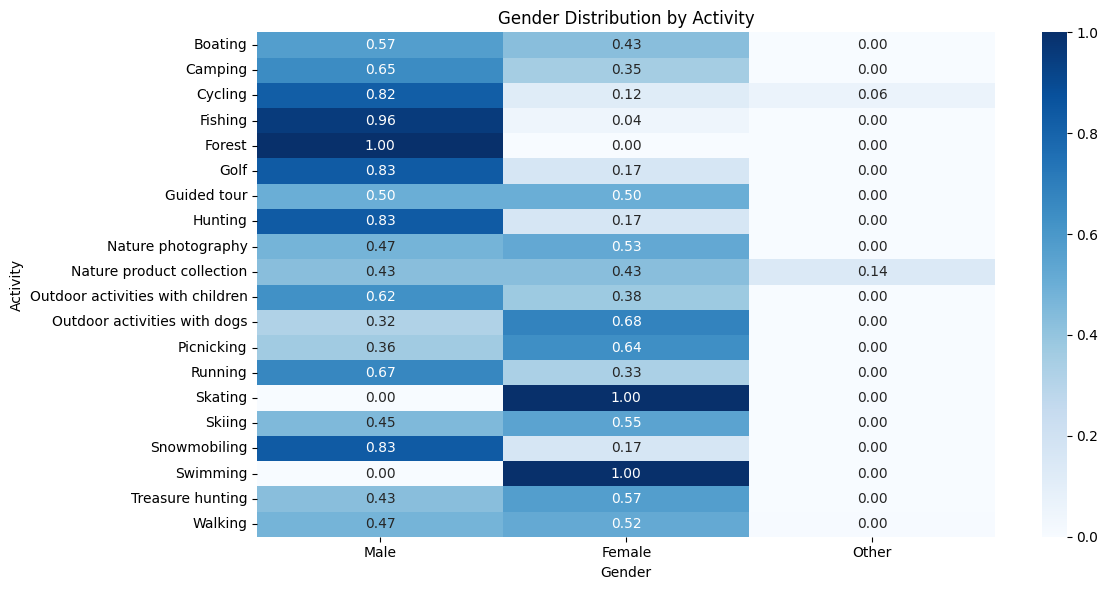

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

labels = {
    1: 'Male',
    2: 'Female',
    3: 'Other',
}

# Map gender codes to labels
df['A1_gender_label'] = df['A1_gender'].map(labels)

table = (
    df.groupby('activity')['A1_gender_label']
      .value_counts(normalize=True)
      .unstack()
      .fillna(0)
)

# Enforce original order
ordered_labels = [labels[k] for k in sorted(labels)]
table = table.reindex(columns=ordered_labels)

plt.figure(figsize=(12, 6))
sns.heatmap(
    table,
    annot=True,
    fmt=".2f",
    cmap="Blues"
)

plt.xlabel('Gender')
plt.ylabel('Activity')
plt.title('Gender Distribution by Activity')
plt.tight_layout()
plt.show()


## Age

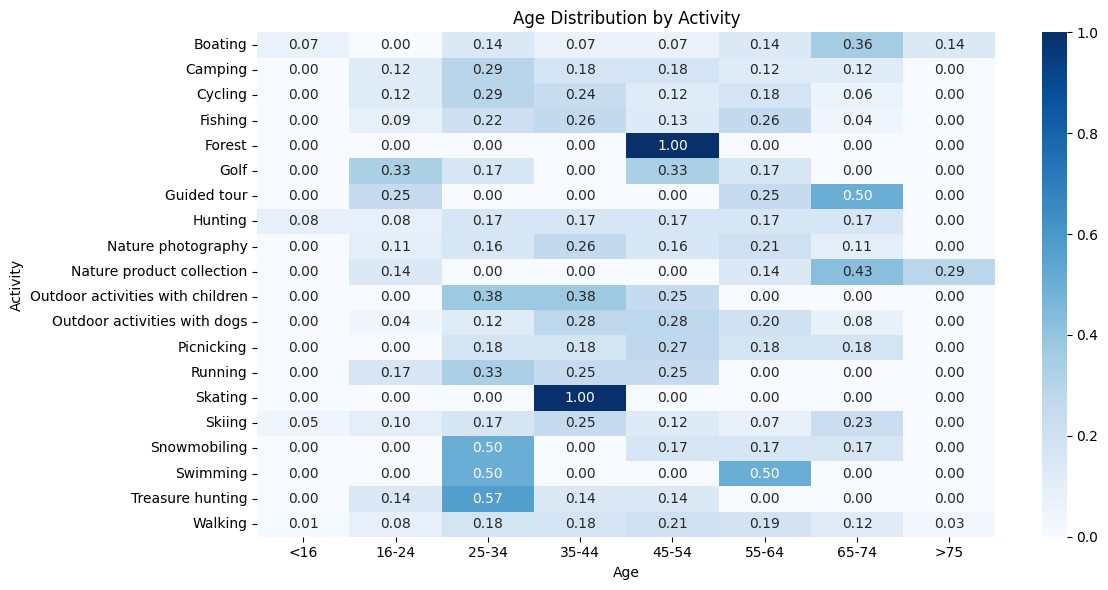

In [36]:
import seaborn as sns
import matplotlib.pyplot as plt

labels = {
    1: '<16',
    2: '16-24',
    3: '25-34',
    4: '35-44',
    5: '45-54',
    6: '55-64',
    7: '65-74',
    8: '>75'
}

# Map gender codes to labels
df['A2_age_label'] = df['A2_age'].map(labels)


table = (
    df.groupby('activity')['A2_age_label']
      .value_counts(normalize=True)
      .unstack()
      .fillna(0)
)

# Enforce original order
ordered_labels = [labels[k] for k in sorted(labels)]
table = table.reindex(columns=ordered_labels)

plt.figure(figsize=(12, 6))
sns.heatmap(
    table,
    annot=True,
    fmt=".2f",
    cmap="Blues"
)

plt.xlabel('Age')
plt.ylabel('Activity')
plt.title('Age Distribution by Activity')
plt.tight_layout()
plt.show()


# Motivations across visiting groups

In [470]:
df.groupby('B_2_accompany')[motivation_col].mean()

,motivation_1_peace,motivation_2_natural_products,motivation_3_landscapes,motivation_4_experiences,motivation_5_fitness,motivation_6_recovery,motivation_7_time,motivation_8_social,motivation_9_personal_skills,motivation_10_adventure
B_2_accompany,,,,,,,,,,
1.0,3.451613,1.806452,3.365591,3.172043,3.397849,3.462366,3.494624,2.032258,2.322581,2.430108
2.0,3.680672,1.949580,3.710084,3.626050,3.151261,3.500000,3.319328,3.680672,2.474790,2.857143
3.0,3.591837,1.867347,3.479592,3.520408,3.030612,3.418367,3.244898,3.581633,2.561224,3.020408
4.0,4.000000,1.666667,4.333333,4.000000,3.333333,4.000000,4.000000,4.333333,3.000000,3.000000
5.0,3.750000,2.000000,4.000000,3.500000,3.750000,4.000000,3.250000,3.250000,3.000000,4.000000
6.0,2.888889,2.000000,3.444444,3.333333,3.444444,3.444444,3.111111,3.444444,3.111111,3.000000
7.0,3.333333,2.166667,3.833333,3.333333,2.666667,3.166667,2.833333,3.500000,2.500000,3.166667


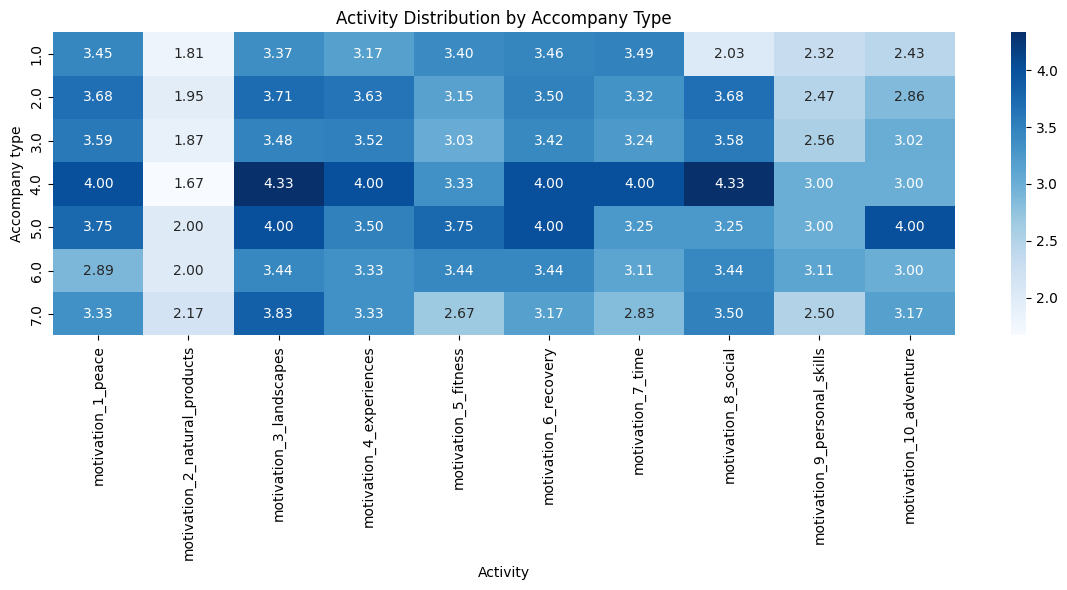

In [471]:
import seaborn as sns
import matplotlib.pyplot as plt

table = df.groupby('B_2_accompany')[motivation_col].mean()

plt.figure(figsize=(12, 6))
sns.heatmap(
    table,
    annot=True,
    fmt=".2f",
    cmap="Blues"
)

plt.xlabel('Activity')
plt.ylabel('Accompany type')
plt.title('Activity Distribution by Accompany Type')
plt.tight_layout()
plt.show()

# Municipality

In [5]:
import fiona
import geopandas as gpd

In [6]:
layers = fiona.listlayers('../../../data/boundaries/SuomenHallinnollisetKuntajakopohjaisetAluejaot_2026_10k.gpkg')
print(layers)

['Maakunta', 'Elinvoimakeskus', 'Valtakunta', 'Kunta', 'Hyvinvointialue']


In [7]:
gdf_municipality = gpd.read_file('../../../data/boundaries/SuomenHallinnollisetKuntajakopohjaisetAluejaot_2026_10k.gpkg', layer='Kunta')

In [8]:
gdf_municipality['lvvi3_count'] = (gdf_municipality['namefin'].map(df['area_municipality'].value_counts()))

In [9]:
gdf_municipality[['namefin', 'lvvi3_count']]

,namefin,lvvi3_count
0,Parainen,4.0
1,Outokumpu,1.0
2,Rauma,8.0
3,Alajärvi,NaN
4,Posio,7.0
...,...,...
303,Teuva,1.0
304,Hankasalmi,NaN
305,Soini,1.0
306,Kauhava,1.0


In [14]:
df['area_municipality'].value_counts()[:20].to_frame()

,count
area_municipality,
Kuusamo,28
Inari,26
Kolari,25
Espoo,24
Enontekiö,13
Lieksa,12
Muonio,10
Salo,9
Helsinki,9


In [99]:
gdf_municipality["lvvi3_count"].max()

28.0

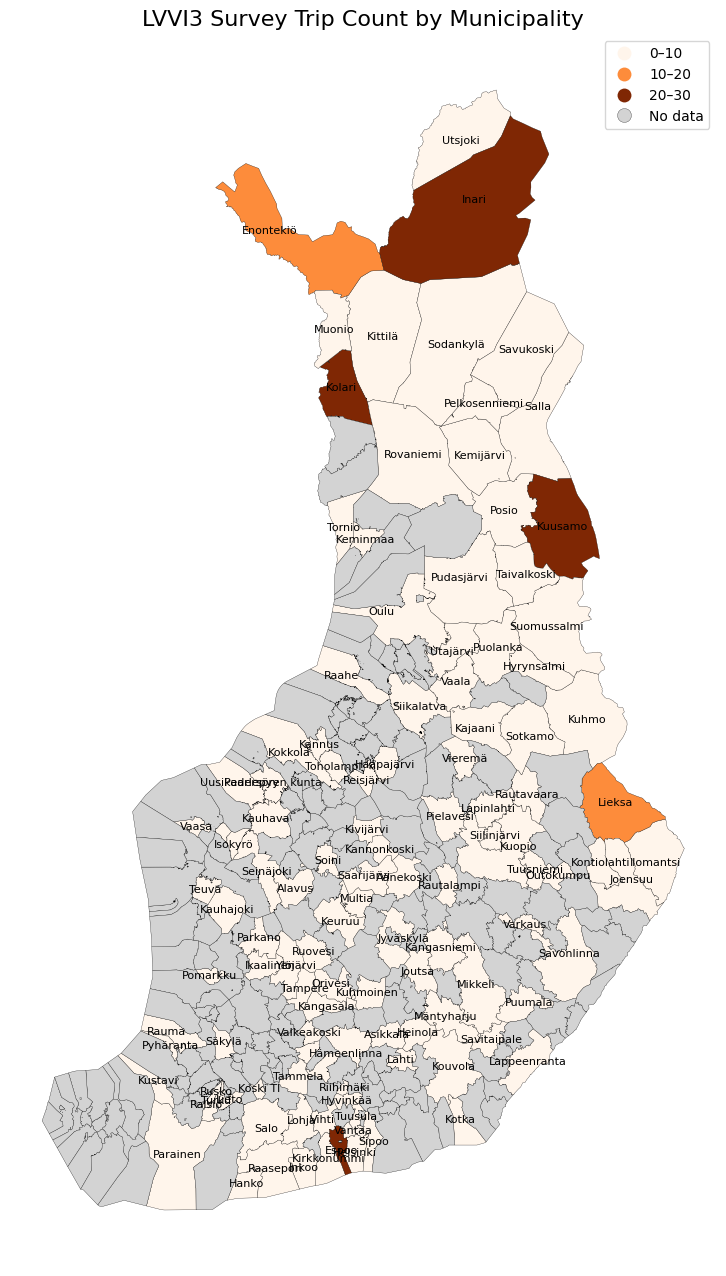

In [18]:
import matplotlib.pyplot as plt

bins = [0, 10, 20, 30]
labels = ["0–10", "10–20", "20–30"]

gdf_municipality["lvvi3_cat"] = pd.cut(gdf_municipality["lvvi3_count"], bins=bins, labels=labels)

fig, ax = plt.subplots(1, 1, figsize=(12, 16))

gdf_municipality.plot(
    column="lvvi3_cat",
    categorical=True,
    cmap="Oranges",
    legend=True,
    ax=ax,
    edgecolor="black",
    linewidth=0.2,
    missing_kwds={"color": "lightgrey", "label": "No data"}
)

# Label municipalities
# for _, row in gdf_municipality.iterrows():
#     if row.geometry is not None:
#         point = row.geometry.representative_point()
#         ax.annotate(
#             row["namefin"],
#             xy=(point.x, point.y),
#             ha="center",
#             va="center",
#             fontsize=8,
#             color="black"
#         )
for _, row in gdf_municipality.iterrows():
    if row.geometry is not None and pd.notna(row["lvvi3_cat"]):
        point = row.geometry.representative_point()
        ax.annotate(
            row["namefin"],
            xy=(point.x, point.y),
            ha="center",
            va="center",
            fontsize=8,
            color="black"
        )

ax.set_title("LVVI3 Survey Trip Count by Municipality", fontsize=16)
ax.axis("off")

plt.show()